# Diabetes screening — 20-feature version
Same pipeline and experiments as `diabetes-analysis.ipynb`, with three differences:
1. **20 features** selected before the split (instead of 28), for a shorter screening questionnaire.
2. **Missing BMI filled from height and weight** where both are known.
3. **5-fold cross-validation** for every classical model (neural networks are evaluated on the validation set with their learning curves).

Outputs are kept separate from the 28-feature notebook: TensorBoard logs in `runs_20_features/`, split files `diabete_study_20_features_*.csv`.

## Setup
This notebook runs both locally and on Kaggle. On Kaggle, turn on **Internet** in the notebook settings (needed to download the data and install `tensorboardX`). Outputs are written to `/kaggle/working/` on Kaggle and to the project folder locally.

In [5]:
%pip install -q tensorboardX imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
import glob
import shutil
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedShuffleSplit)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             f1_score,
                             confusion_matrix
                             )

In [7]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ON_KAGGLE = os.path.exists("/kaggle/input")
OUTPUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
DATA_DIR = os.path.join(OUTPUT_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)

print("Running on Kaggle" if ON_KAGGLE else "Running locally")
print("Data folder:", DATA_DIR)

Running on Kaggle
Data folder: /kaggle/working/data


In [8]:
##### Download the BRFSS 2023 data (skipped if it is already there)
XPT_PATH = os.path.join(DATA_DIR, "LLCP2023.XPT")

if not os.path.exists(XPT_PATH):
    !wget -O LLCP2023XPT.zip https://www.cdc.gov/brfss/annual_data/2023/files/LLCP2023XPT.zip
    !unzip -o LLCP2023XPT.zip -d {DATA_DIR}
    !mv "{DATA_DIR}/LLCP2023.XPT " {XPT_PATH}
    !rm LLCP2023XPT.zip

print("Using:", XPT_PATH)


Using: /kaggle/working/data/LLCP2023.XPT


In [9]:
df = pd.read_sas(XPT_PATH, format="xport", encoding="latin-1")
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,03012023,03,01,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,01062023,01,06,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,03082023,03,08,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,03062023,03,06,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,01062023,01,06,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [10]:
target = "DIABETE4"

binary_cols = ["_RFHYPE6", "_RFCHOL3", "CVDSTRK3", "_MICHD", "CHCKDNY2",
               "_TOTINDA", "_RFDRHV8", "_HLTHPL1", "MEDCOST1", "DIFFWALK", "_SEX"]
ordinal_cols = ["GENHLTH", "_AGEG5YR", "_EDUCAG", "_INCOMG1", "_SMOKER3", "_CHOLCH3"]
numeric_cols = ["_BMI5", "PHYSHLTH", "MENTHLTH", "_DRNKWK2", "DROCDY4_",
                "_AGE80", "HTIN4", "WTKG3", "PA3MIN_", "PA3VIGM_", "STRFREQ_"]

In [11]:
diabete_study = df[numeric_cols + ordinal_cols + binary_cols + [target]]
diabete_study.to_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"), index=False)

del df            # the full 350-column table is no longer needed
import gc
gc.collect()      # return the memory to the system

0

In [12]:
data = pd.read_csv(os.path.join(DATA_DIR, "BRFSS_dataset.csv"))
data.shape

(433323, 29)

In [13]:
data.columns

Index(['_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK2', 'DROCDY4_', '_AGE80',
       'HTIN4', 'WTKG3', 'PA3MIN_', 'PA3VIGM_', 'STRFREQ_', 'GENHLTH',
       '_AGEG5YR', '_EDUCAG', '_INCOMG1', '_SMOKER3', '_CHOLCH3', '_RFHYPE6',
       '_RFCHOL3', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', '_TOTINDA', '_RFDRHV8',
       '_HLTHPL1', 'MEDCOST1', 'DIFFWALK', '_SEX', 'DIABETE4'],
      dtype='object')

In [14]:
# rename columns from code to variable names
column_names = {
    # Target
    "DIABETE4": "diabetes",

    # Binary
    "_RFHYPE6": "high_blood_pressure",
    "_RFCHOL3": "high_cholesterol",
    "CVDSTRK3": "stroke",
    "_MICHD":   "heart_disease",
    "CHCKDNY2": "kidney_disease",
    "_TOTINDA": "physical_activity",
    "_RFDRHV8": "heavy_drinker",
    "_HLTHPL1": "health_insurance",
    "MEDCOST1": "cant_afford_doctor",
    "DIFFWALK": "difficulty_walking",
    "_SEX":     "sex",

    # Ordinal
    "GENHLTH":  "general_health",
    "_AGEG5YR": "age_group",
    "_EDUCAG":  "education",
    "_INCOMG1": "income",
    "_SMOKER3": "smoking_status",
    "_CHOLCH3": "cholesterol_check",

    # Numeric
    "_BMI5":    "bmi",
    "PHYSHLTH": "poor_physical_health_days",
    "MENTHLTH": "poor_mental_health_days",
    "_DRNKWK2": "drinks_per_week",
    "DROCDY4_": "drink_occasions_per_day",
    "_AGE80":   "age",
    "HTIN4":    "height_inches",
    "WTKG3":     "weight_kg",
    "PA3MIN_":  "exercise_minutes_per_week",
    "PA3VIGM_": "vigorous_exercise_minutes_per_week",
    "STRFREQ_": "strength_training_per_week",
}

data_renamed = data.rename(columns=column_names)


In [15]:
num = data_renamed.select_dtypes("number").columns
data_renamed[num] = data_renamed[num].mask(data_renamed[num].abs() < 1e-10, 0)

In [16]:
data_renamed.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,3047.0,88.0,88.0,0.0,0.0,80.0,63.0,7802.0,NaN,NaN,...,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0
1,2856.0,88.0,88.0,0.0,0.0,80.0,57.0,5987.0,360.0,180.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0
2,2231.0,6.0,2.0,0.0,0.0,80.0,64.0,5897.0,36.0,18.0,...,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0
3,2744.0,2.0,88.0,0.0,0.0,78.0,66.0,7711.0,180.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,3.0
4,2585.0,88.0,88.0,47.0,7.0,76.0,68.0,7711.0,600.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0


## Basic Data Explaratory and handling missing values
The BRFSS survey is an encoded survey where numbers 7 and 9 mean respectfully don't know or refused to provide. In this study, we will consider it as NaN value. Let's first check how many of them are there per columns. These two codes are included in following features: **["diabetes", "stroke", "kidney_disease", "cant_afford_doctor", "difficulty_walking", "general_health"]**
Reference source: **codebook23_llcp-v2-508**

In [17]:
## check for missingness
dk_cols = ["diabetes", "stroke", "kidney_disease", "cant_afford_doctor",
           "difficulty_walking", "general_health", "difficulty_walking",
           "high_cholesterol"]

missing_table = pd.DataFrame({
    "7 appearance in %":     (data_renamed[dk_cols] == 7).mean() * 100,
    "9 appearance in %":     (data_renamed[dk_cols] == 9).mean() * 100,
    "7 & 9 appearance in %": data_renamed[dk_cols].isin([7, 9]).mean() * 100,
}).round(2)
missing_table.index.name = "column_name"

missing_table


,7 appearance in %,9 appearance in %,7 & 9 appearance in %
column_name,,,
diabetes,0.16,0.07,0.23
stroke,0.28,0.06,0.34
kidney_disease,0.37,0.06,0.44
cant_afford_doctor,0.27,0.08,0.35
difficulty_walking,0.28,0.11,0.39
general_health,0.21,0.08,0.29
difficulty_walking,0.28,0.11,0.39
high_cholesterol,0.00,0.76,0.76


In [18]:
## check for NAN
columns = ["exercise_minutes_per_week",
           "vigorous_exercise_minutes_per_week",
           "high_cholesterol","bmi","weight_kg",
           "height_inches","strength_training_per_week",
           "heart_disease"

           ]

In [19]:
# Codes that mean "don't know / refused / missing" in each column
missing_codes = {
    "diabetes":                   [7, 9],
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "high_cholesterol":           [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "income":                     [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

all_codes = [7, 9, 77, 99, 14, 99900, 900, 99000]

rows = {}
for col, codes in missing_codes.items():
    s = data_renamed[col]
    row = {f"{c} appearance in %": (s == c).mean() * 100 if c in codes else np.nan
           for c in all_codes}
    row["NaN in %"] = s.isna().mean() * 100
    row["total missing in %"] = (s.isin(codes) | s.isna()).mean() * 100
    rows[col] = row

missing_table = pd.DataFrame(rows).T.round(2)
missing_table.index.name = "column_name"

missing_table.sort_values("total missing in %", ascending=False)


,7 appearance in %,9 appearance in %,77 appearance in %,99 appearance in %,14 appearance in %,99900 appearance in %,900 appearance in %,99000 appearance in %,NaN in %,total missing in %
column_name,,,,,,,,,,
income,NaN,19.99,NaN,NaN,NaN,NaN,NaN,NaN,0.00,19.99
high_cholesterol,NaN,0.76,NaN,NaN,NaN,NaN,NaN,NaN,11.96,12.71
heavy_drinker,NaN,7.58,NaN,NaN,NaN,NaN,NaN,NaN,0.00,7.58
drinks_per_week,NaN,NaN,NaN,NaN,NaN,7.58,NaN,NaN,0.00,7.58
drink_occasions_per_day,NaN,NaN,NaN,NaN,NaN,NaN,6.91,NaN,0.00,6.91
cholesterol_check,NaN,6.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00,6.10
smoking_status,NaN,5.32,NaN,NaN,NaN,NaN,NaN,NaN,0.00,5.32
health_insurance,NaN,4.31,NaN,NaN,NaN,NaN,NaN,NaN,0.00,4.31
difficulty_walking,0.28,0.11,NaN,NaN,NaN,NaN,NaN,NaN,3.73,4.12


Drop 7 and 9 inside the target (7=don't know, 9=refused)

In [20]:
# Drop rows where the target is unknown (7 = don't know, 9 = refused) or blank
clean_data = data_renamed[~data_renamed["diabetes"].isin([7, 9])]
clean_data = clean_data.dropna(subset=["diabetes"])

print(f"{len(data_renamed)} rows before 'vs', {len(clean_data)} rows now")
clean_data["diabetes"].value_counts()


433323 rows before 'vs', 432339 rows now


diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
Name: count, dtype: int64


**According to Vounzoulaki in his research report titled "Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis", women with a known history of gestational diabetes (diabetes during pregnancy) were 10 times more likely to develop type 2 diabetes (Vounzoulaki et al., 2020). For this reason, we will merge data on diabetes in pregnant women with prediabetes data.******


In [21]:
# Gestational diabetes only (2), at risk, together with prediabetes (4)
clean_data["diabetes"] = clean_data["diabetes"].replace({2: 4})
clean_data["diabetes"].value_counts()

diabetes
3.0    358706
1.0     59786
4.0     13847
Name: count, dtype: int64

In [22]:
## replace 7 (don't know) with NaN
columns = ["difficulty_walking", "kidney_disease", "cant_afford_doctor",
           "stroke", "general_health"]
clean_data[columns].head()

,difficulty_walking,kidney_disease,cant_afford_doctor,stroke,general_health
0,1.0,2.0,2.0,2.0,2.0
1,2.0,2.0,2.0,2.0,2.0
2,1.0,2.0,1.0,2.0,4.0
3,1.0,2.0,2.0,2.0,2.0
4,1.0,2.0,2.0,2.0,4.0


In [23]:
###### Codes that mean "don't know / refused / missing" in each column
to_nan = {
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

clean_data = clean_data.replace({col: {code: np.nan for code in codes}
                                 for col, codes in to_nan.items()})


In [24]:
for col in ["poor_physical_health_days", "poor_mental_health_days"]:
    clean_data[col] = clean_data[col].replace(88, 0)

In [25]:
# check for missing values
print("Missing values...")
(clean_data.isna().mean() * 100).round(2).sort_values(ascending=False)

Missing values...


exercise_minutes_per_week             28.38
vigorous_exercise_minutes_per_week    27.34
high_cholesterol                      11.91
bmi                                    9.30
weight_kg                              7.83
heavy_drinker                          7.54
drinks_per_week                        7.54
drink_occasions_per_day                6.88
height_inches                          6.42
cholesterol_check                      6.06
smoking_status                         5.29
health_insurance                       4.27
difficulty_walking                     4.09
strength_training_per_week             3.29
poor_physical_health_days              2.47
poor_mental_health_days                1.85
age_group                              1.75
heart_disease                          1.00
education                              0.51
high_blood_pressure                    0.40
kidney_disease                         0.37
cant_afford_doctor                     0.34
general_health                  

In [26]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 432339 entries, 0 to 433322
Data columns (total 29 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   bmi                                 392119 non-null  float64
 1   poor_physical_health_days           421667 non-null  float64
 2   poor_mental_health_days             424355 non-null  float64
 3   drinks_per_week                     399739 non-null  float64
 4   drink_occasions_per_day             402612 non-null  float64
 5   age                                 432339 non-null  float64
 6   height_inches                       404602 non-null  float64
 7   weight_kg                           398482 non-null  float64
 8   exercise_minutes_per_week           309628 non-null  float64
 9   vigorous_exercise_minutes_per_week  314131 non-null  float64
 10  strength_training_per_week          418108 non-null  float64
 11  general_health                 

In [27]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,2847.766461,4.478899,4.355040,280.333270,16.430516,55.379346,67.066945,8288.308315,636.715375,162.025047,...,1.957555,1.915378,1.952367,1.247115,1.059249,1.054591,1.914125,1.838916,1.529837,2.755458
std,653.954620,8.823183,8.316287,815.396316,27.138132,17.909326,4.185244,2133.152545,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,1202.000000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,2268.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2410.000000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,6804.000000,140.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000,3.000000
50%,2740.000000,0.000000,0.000000,23.000000,3.000000,58.000000,67.000000,8029.000000,315.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
75%,3162.000000,4.000000,5.000000,233.000000,17.000000,71.000000,70.000000,9435.000000,672.000000,144.500000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
max,9984.000000,30.000000,30.000000,53200.000000,100.000000,80.000000,95.000000,28400.000000,118602.000000,59301.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000


In [28]:
TARGET = "diabetes"
features = [
    # Numeric
    "bmi", "poor_physical_health_days", "poor_mental_health_days",
    "drinks_per_week", "drink_occasions_per_day", "age",
    "height_inches", "weight_kg", "exercise_minutes_per_week",
    "vigorous_exercise_minutes_per_week", "strength_training_per_week",

    # Ordinal
    "general_health", "age_group", "education", "income",
    "smoking_status", "cholesterol_check",

    # Binary
    "high_blood_pressure", "high_cholesterol", "stroke", "heart_disease",
    "kidney_disease", "physical_activity", "heavy_drinker",
    "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex",
]

Features/target

## Encode Binaries values
for sex, 0 is male and 1 is female

In [29]:
# 1 i yes, 2 is no
one_is_yes = ["stroke", "heart_disease", "kidney_disease", "cant_afford_doctor",
              "difficulty_walking", "physical_activity", "health_insurance"]

# 1 is no, 2 is yes
one_is_no = ["high_blood_pressure", "high_cholesterol", "heavy_drinker"]


In [30]:
for col in one_is_yes:
    clean_data[col] = clean_data[col].map({1: 1, 2: 0})

for col in one_is_no:
    clean_data[col] = clean_data[col].map({1: 0, 2: 1})

clean_data["sex"] = clean_data["sex"].map({1: 0, 2: 1})

# high_cholesterol: keep "unknown" (never checked / don't know) as its own category
clean_data["high_cholesterol"] = clean_data["high_cholesterol"].fillna(-1)   # -1 = unknown


## Encode ordinal values

In [31]:
# smoking: 0 = never, 1 = former, 2 = some days, 3 = daily
clean_data["smoking_status"] = clean_data["smoking_status"].map({4: 0, 3: 1, 2: 2, 1: 3})

# cholesterol check: 0 = within 5 years, 1 = more than 5 years ago, 2 = never
clean_data["cholesterol_check"] = clean_data["cholesterol_check"].map({1: 0, 2: 1, 3: 2})

# income: keep 1–7, unknown (9) becomes 0
clean_data["income"] = clean_data["income"].replace(9, 0)

# age group: 0 = 18–24, 1 = 25–29, ..., 12 = 80+
clean_data["age_group"] = clean_data["age_group"] - 1


BRFSS for privacy reasons multiplied some numerical values to 100 or 1000. This section will bring those features to their initial values

In [32]:
scale_map = {
    "bmi": 100,
    "weight_kg": 100,
    "drinks_per_week": 100,
    "drink_occasions_per_day": 100,
    "strength_training_per_week": 1000,
}
for col, factor in scale_map.items():
    clean_data[col] = clean_data[col] / factor
print("Complete")

Complete


### Fill missing BMI from height and weight
BMI is blank for about 9% of respondents. Where both height and weight are known, BMI can be calculated directly (weight in kg divided by height in metres squared). The official BMI is kept wherever it exists, because recalculating it for everyone would discard the official value of respondents who reported their height in metric units (their `height_inches` is blank).

In [33]:
# Fill missing BMI from height and weight where both are known: BMI = weight (kg) / height (m)^2
# The official BMI is kept wherever it exists (it also covers people who reported a metric height,
# for whom height_inches is blank).
computed_bmi = clean_data["weight_kg"] / (clean_data["height_inches"] * 0.0254) ** 2
bmi_missing_before = clean_data["bmi"].isna().sum()
clean_data["bmi"] = clean_data["bmi"].fillna(computed_bmi)
print(f"BMI missing: {bmi_missing_before} -> {clean_data['bmi'].isna().sum()} "
      f"({bmi_missing_before - clean_data['bmi'].isna().sum()} filled from height and weight)")

BMI missing: 40220 -> 38289 (1931 filled from height and weight)


In [34]:
clean_data.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,30.47,0.0,0.0,0.00,0.00,80.0,63.0,78.02,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1,1.0
1,28.56,0.0,0.0,0.00,0.00,80.0,57.0,59.87,360.0,180.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,3.0
2,22.31,6.0,2.0,0.00,0.00,80.0,64.0,58.97,36.0,18.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1,3.0
3,27.44,2.0,0.0,0.00,0.00,78.0,66.0,77.11,180.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,3.0
4,25.85,0.0,0.0,0.47,0.07,76.0,68.0,77.11,600.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,1.0


In [35]:
clean_data["high_cholesterol"].value_counts()

high_cholesterol
 0.0    219032
 1.0    158647
-1.0     54660
Name: count, dtype: int64

## Check for outlier

In [36]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,394050.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,28.479649,4.478899,4.355040,2.803333,0.164305,55.379346,67.066945,82.883083,636.715375,162.025047,...,0.042445,0.084622,0.047633,0.752885,0.059249,0.945409,0.085875,0.161084,0.529837,2.755458
std,6.572748,8.823183,8.316287,8.153963,0.271381,17.909326,4.185244,21.331525,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.724823
min,3.895188,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,22.680000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,24.090000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,68.040000,140.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3.000000
50%,27.400000,0.000000,0.000000,0.230000,0.030000,58.000000,67.000000,80.290000,315.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
75%,31.620000,4.000000,5.000000,2.330000,0.170000,71.000000,70.000000,94.350000,672.000000,144.500000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
max,146.414287,30.000000,30.000000,532.000000,1.000000,80.000000,95.000000,284.000000,118602.000000,59301.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


drinks_per_week shows a surprising maximun value of 532 drinks in a week, which is in average around 76 drinks per day.

In [37]:
# check the distribution of drinks_per_week
clean_data["drinks_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])


0.25000      0.000000
0.50000      0.230000
0.75000      2.330000
0.90000      8.000000
0.95000     14.000000
0.99000     30.000000
0.99900     84.000000
0.99990    224.244446
0.99999    511.036680
1.00000    532.000000
Name: drinks_per_week, dtype: float64

At 99.9% quantile, only 84 drinks were taken in a week, which is 12 drinks per day.  At 99.99%, it is 224 drinks per week, around 32 drinks per day. According to the Ohio State report, a clinical sample of people with alcohol use disorder averaged 6.4 drinks per day. My personal assumption is that values in the extreme outliers might be due to a typing error. The value will be capped at 0.999 quantile

In [38]:
cap = clean_data["drinks_per_week"].quantile(0.999)
clean_data["drinks_per_week"] = clean_data["drinks_per_week"].clip(upper=cap)


**exercise_minutes_per_week and vigorous_exercise_minutes_per_week also have an issue. Their maximun values are 118602 and 59301 minutes while a week has 24*60*7 minutes = 10080 minutes**

In [39]:
check_activity_min = clean_data["exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,140.0000,2.333333
0.50000,50.000,315.0000,5.250000
0.75000,75.000,672.0000,11.200000
0.90000,90.000,1440.0000,24.000000
0.95000,95.000,2310.0000,38.500000
0.99000,99.000,4872.0000,81.200000
0.99900,99.900,13244.7600,220.746000
0.99990,99.990,47522.2380,792.037300
0.99999,99.999,94416.1704,1573.602840
1.00000,100.000,118602.0000,1976.700000


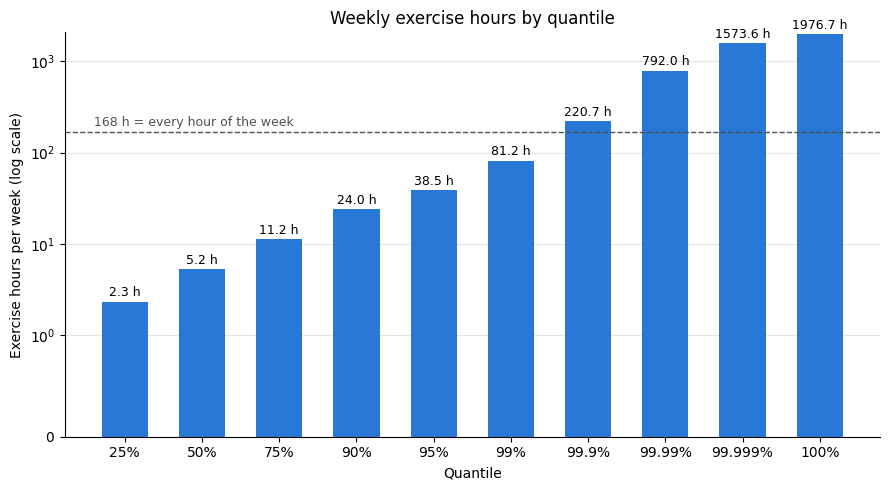

In [40]:
import matplotlib.pyplot as plt
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("Weekly exercise hours by quantile")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


Considering that a week has 168h (24h per day), any practice value beyond 168h is mathematically impossible. At 99%, a consistent practice time of 81.2h per week (11h per day) seems also to be quite impossible even for profesionnal athletes. The most plausible value is found at 95% quantile (38.5h)

In [41]:
cap = clean_data["exercise_minutes_per_week"].quantile(0.95)
clean_data["exercise_minutes_per_week"] = clean_data["exercise_minutes_per_week"].clip(upper=cap)

Check for vigorous_exercise_minutes_per_week

In [42]:
check_activity_min = clean_data["vigorous_exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,0.000,0.000000
0.50000,50.000,0.000,0.000000
0.75000,75.000,144.500,2.408333
0.90000,90.000,420.000,7.000000
0.95000,95.000,780.000,13.000000
0.99000,99.000,2100.000,35.000000
0.99900,99.900,4620.000,77.000000
0.99990,99.990,16051.320,267.522000
0.99999,99.999,43364.376,722.739600
1.00000,100.000,59301.000,988.350000


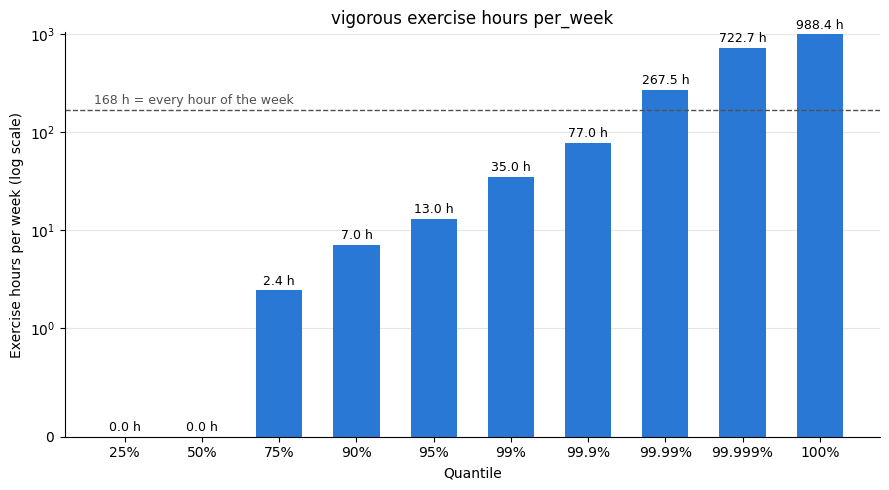

In [43]:
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("vigorous exercise hours per_week")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [44]:
cap = clean_data["vigorous_exercise_minutes_per_week"].quantile(0.95)
clean_data["vigorous_exercise_minutes_per_week"] = clean_data["vigorous_exercise_minutes_per_week"].clip(upper=cap)

People who answered "no physical activity" (`physical_activity = 0`) were not asked how long they exercise, so BRFSS left their exercise minutes blank. Their real value is 0 minutes. The caps above were computed on active people only, before filling these zeros.

In [45]:
inactive = clean_data["physical_activity"] == 0
clean_data.loc[inactive, ["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]] = 0

clean_data[["exercise_minutes_per_week", "vigorous_exercise_minutes_per_week"]].isna().mean() * 100

exercise_minutes_per_week             3.739889
vigorous_exercise_minutes_per_week    2.698346
dtype: float64

In [46]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]

clean_data[numeric_cols].describe()

,bmi,age,height_inches,weight_kg,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,strength_training_per_week
count,394050.000000,432339.000000,404602.000000,398482.000000,421667.000000,424355.000000,399739.000000,402612.000000,416170.000000,420673.000000,418108.000000
mean,28.479649,55.379346,67.066945,82.883083,4.478899,4.355040,2.738830,0.164305,401.479287,88.748978,1.863999
std,6.572748,17.909326,4.185244,21.331525,8.823183,8.316287,6.682283,0.271381,565.802171,190.844661,2.844207
min,3.895188,18.000000,36.000000,22.680000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.090000,41.000000,64.000000,68.040000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.400000,58.000000,67.000000,80.290000,0.000000,0.000000,0.230000,0.030000,182.000000,0.000000,0.467000
75%,31.620000,71.000000,70.000000,94.350000,4.000000,5.000000,2.330000,0.170000,495.000000,70.000000,3.000000
max,146.414287,80.000000,95.000000,284.000000,30.000000,30.000000,84.000000,1.000000,2310.000000,780.000000,97.000000


Similar with exercise per week, any value above the total number of hours per week (168h) is impossible and 11h constant exercise is not very plausible. We will also cap at 95% quantille.

At 99%, it is recorded at 4872 min, which is equivalent to 81.2h per week, 

## Feature selection: 20 features
A screening questionnaire is more useful when it is short. The 20 features below were kept based on permutation importance (screening F2, LightGBM) from the full 28-feature experiments, plus established clinical risk factors kept regardless of importance (`sex`, `smoking_status`, `difficulty_walking`, `physical_activity`, `stroke`, `heavy_drinker`). The selection is applied **before** the train/validation/test split, so every model uses exactly these columns. Because the split is row-based with the same `random_state`, the same people end up in each set as in the 28-feature notebook.

In [47]:
# 20 features, selected before the split: permutation importance (LightGBM) + established clinical risk factors
SELECTED_FEATURES = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day", "drinks_per_week",
    "exercise_minutes_per_week", "strength_training_per_week",
    # ordinal / categorical
    "general_health", "age_group", "high_cholesterol", "cholesterol_check", "smoking_status",
    # binary
    "high_blood_pressure", "sex", "kidney_disease", "heart_disease",
    "difficulty_walking", "physical_activity", "stroke", "heavy_drinker",
]
assert len(SELECTED_FEATURES) == 20

X = clean_data[SELECTED_FEATURES]
Y = clean_data[TARGET]
print("features:", X.shape[1], "| rows:", X.shape[0])

features: 20 | rows: 432339


Check for class Imbalance

In [48]:
classes = Y.value_counts()
target_class_imbalance = pd.DataFrame({
    "class": classes.index,
    "class_percentage %": (classes * 100 / len(Y)).round(2),
}).reset_index(drop=True)
target_class_imbalance

,class,class_percentage %
0,3.0,82.97
1,1.0,13.83
2,4.0,3.20


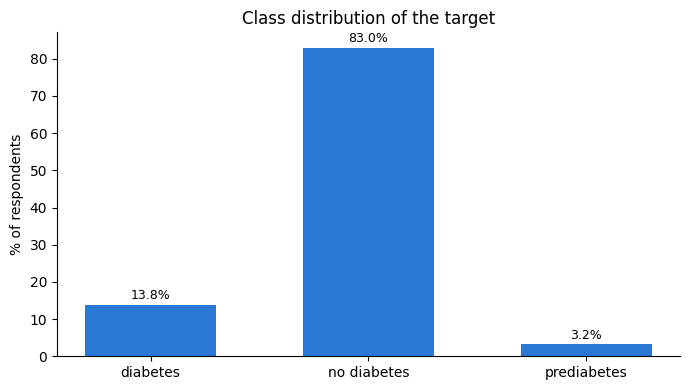

In [49]:
classes = Y.value_counts().sort_index()
target_class_imbalance = pd.DataFrame({
    "class": classes.index.astype(int).astype(str),
    "class_percentage": (classes / len(Y) * 100).round(2).values,
})

class_names = {"1": "diabetes", "2": "pregnancy only", "3": "no diabetes", "4": "prediabetes"}
labels = target_class_imbalance["class"].map(class_names)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, target_class_imbalance["class_percentage"], color="#2a78d6", width=0.6)
for bar, p in zip(bars, target_class_imbalance["class_percentage"]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width() / 2, p),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_ylabel("% of respondents")
ax.set_title("Class distribution of the target")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [50]:
import os
from datetime import datetime
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             balanced_accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             average_precision_score,
                             f1_score,
                             fbeta_score,
                             make_scorer,
                             confusion_matrix,
                             classification_report)
from tensorboardX import SummaryWriter

RANDOM_STATE = 42
LOG_DIR = os.path.join(OUTPUT_DIR, "runs_20_features")   # view with: tensorboard --logdir runs_20_features
# 2 (diabetes only during pregnancy) was merged into 4 -> "at risk"
CLASS_NAMES = {1: "diabetes", 3: "no diabetes", 4: "at risk"}
CLASS_COLORS = {1: "#2a78d6", 3: "#1baf7a", 4: "#eda100"}   # one fixed color per class
FLAG_CLASSES = [1, 4]   # diabetes or at risk -> flagged for follow-up
results_log = []   # every experiment's summary lands here -> becomes your results table


# ---------- Screening = binary view: needs follow-up (diabetes or at risk) vs no diabetes ----------
def is_flagged(class_labels):
    return np.isin(np.asarray(class_labels), FLAG_CLASSES)

def screen_sensitivity(y_true, y_pred):
    return recall_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_precision(y_true, y_pred):
    return precision_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_specificity(y_true, y_pred):
    actually_flagged = is_flagged(y_true)
    predicted_flagged = is_flagged(y_pred)
    return (~predicted_flagged[~actually_flagged]).mean()

def screen_f1(y_true, y_pred):
    return f1_score(is_flagged(y_true), is_flagged(y_pred), zero_division=0)

def screen_f2(y_true, y_pred):
    return fbeta_score(is_flagged(y_true), is_flagged(y_pred), beta=2, zero_division=0)


def log_experiment(run_name, pipeline, config, X_train, y_train, X_val, y_val,
                   do_cv=True, use_tensorboard=True):
    '''
    Fits `pipeline`, evaluates it on the validation set, logs to TensorBoard,
    and records a row for the results table. Returns the fitted pipeline.

    run_name : short descriptive string, e.g. "logreg_balanced"
    config   : dict of whatever you want tracked, e.g. {"model": "LogisticRegression", "C": 1.0}
    '''
    pipeline.fit(X_train, y_train)
    classes = pipeline.classes_
    labels = [CLASS_NAMES.get(int(class_code), str(class_code)) for class_code in classes]

    val_probs = pipeline.predict_proba(X_val)
    val_preds = pipeline.predict(X_val)
    y_val_array = np.asarray(y_val)
    y_val_binarized = label_binarize(y_val_array, classes=classes)

    # ---------- 1. Main metrics: screening (diabetes or at risk = flagged) ----------
    flagged = is_flagged(val_preds)
    metrics = {
        "screen_sensitivity": screen_sensitivity(y_val_array, val_preds),
        "screen_precision": screen_precision(y_val_array, val_preds),
        "screen_f2": screen_f2(y_val_array, val_preds),
        "screen_f1": screen_f1(y_val_array, val_preds),
    }

    # ---------- 2. Per-group metrics ----------
    metrics["screen_specificity"] = screen_specificity(y_val_array, val_preds)
    metrics["pct_flagged"] = flagged.mean() * 100
    metrics["missed/diabetes"] = (val_preds[y_val_array == 1] == 3).mean()   # diabetes predicted as no diabetes
    for flag_class in FLAG_CLASSES:
        metrics[f"screen_sensitivity/{CLASS_NAMES[flag_class]}"] = flagged[y_val_array == flag_class].mean()

    per_class_precision = precision_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_recall = recall_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    per_class_f1 = f1_score(y_val_array, val_preds, average=None, labels=classes, zero_division=0)
    for class_index, class_name in enumerate(labels):
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]
        metrics[f"val_precision/{class_name}"] = per_class_precision[class_index]
        metrics[f"val_recall/{class_name}"] = per_class_recall[class_index]   # = sensitivity for that class
        metrics[f"val_f1/{class_name}"] = per_class_f1[class_index]
        metrics[f"val_roc_auc/{class_name}"] = roc_auc_score(class_is_true, class_probability)
        metrics[f"val_pr_auc/{class_name}"] = average_precision_score(class_is_true, class_probability)

    # ---------- 3. Supporting metrics: overall model quality ----------
    metrics.update({
        "val_roc_auc_ovr": roc_auc_score(y_val_array, val_probs, multi_class="ovr", average="macro"),
        "val_f1_macro": f1_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_balanced_accuracy": balanced_accuracy_score(y_val_array, val_preds),
        "val_accuracy": accuracy_score(y_val_array, val_preds),
        "val_precision_macro": precision_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_recall_macro": recall_score(y_val_array, val_preds, average="macro", zero_division=0),
        "val_precision_weighted": precision_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_recall_weighted": recall_score(y_val_array, val_preds, average="weighted", zero_division=0),
        "val_f1_weighted": f1_score(y_val_array, val_preds, average="weighted", zero_division=0),
    })

    # ---------- Cross-validation on the TRAINING data only ----------
    if do_cv:
        cv_scoring = {
            "screen_sensitivity": make_scorer(screen_sensitivity),
            "screen_precision": make_scorer(screen_precision),
            "screen_specificity": make_scorer(screen_specificity),
            "screen_f2": make_scorer(screen_f2),
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
            "roc_auc_ovr": "roc_auc_ovr",
        }
        cv_results = cross_validate(
            pipeline, X_train, y_train,
            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
            scoring=cv_scoring,
            n_jobs=2,   # each parallel fold copies the data; more than 2 runs out of RAM locally
        )
        for score_name in cv_scoring:
            metrics[f"cv_{score_name}_mean"] = cv_results[f"test_{score_name}"].mean()
            metrics[f"cv_{score_name}_std"] = cv_results[f"test_{score_name}"].std()

    print(f"[{run_name}] SCREENING  sensitivity = {metrics['screen_sensitivity']:.3f} | "
          f"precision = {metrics['screen_precision']:.3f} | "
          f"F2 = {metrics['screen_f2']:.3f} | "
          f"F1 = {metrics['screen_f1']:.3f} | "
          f"specificity = {metrics['screen_specificity']:.3f} | "
          f"flagged = {metrics['pct_flagged']:.1f}%")
    print(f"    flagged: diabetes = {metrics['screen_sensitivity/diabetes']:.3f} | "
          f"at risk = {metrics['screen_sensitivity/at risk']:.3f} | "
          f"diabetics missed = {metrics['missed/diabetes']:.3f}")
    print(f"    OVERALL  ROC-AUC (OvR) = {metrics['val_roc_auc_ovr']:.4f} | "
          f"macro F1 = {metrics['val_f1_macro']:.4f} | "
          f"balanced acc = {metrics['val_balanced_accuracy']:.4f} | "
          f"accuracy = {metrics['val_accuracy']:.4f}")
    if do_cv:
        print(f"    CV  screening F2 = {metrics['cv_screen_f2_mean']:.4f} (+/- {metrics['cv_screen_f2_std']:.4f}) | "
              f"sensitivity = {metrics['cv_screen_sensitivity_mean']:.4f} (+/- {metrics['cv_screen_sensitivity_std']:.4f}) | "
              f"precision = {metrics['cv_screen_precision_mean']:.4f} (+/- {metrics['cv_screen_precision_std']:.4f}) | "
              f"macro F1 = {metrics['cv_f1_macro_mean']:.4f} (+/- {metrics['cv_f1_macro_std']:.4f})")
    print(classification_report(y_val_array, val_preds, labels=classes, target_names=labels,
                                digits=3, zero_division=0))

    # ---------- Confusion matrix: counts, colored by row % (= recall per class) ----------
    confusion_counts = confusion_matrix(y_val_array, val_preds, labels=classes)
    confusion_row_share = confusion_counts / confusion_counts.sum(axis=1, keepdims=True)
    fig_cm, cm_axis = plt.subplots(figsize=(6, 5))
    cm_axis.imshow(confusion_row_share, cmap="Blues", vmin=0, vmax=1)
    for row_index in range(len(classes)):
        for col_index in range(len(classes)):
            cell_share = confusion_row_share[row_index, col_index]
            cm_axis.text(col_index, row_index,
                         f"{confusion_counts[row_index, col_index]:,}\n({cell_share:.0%})",
                         ha="center", va="center", color="white" if cell_share > 0.5 else "black")
    cm_axis.set_xticks(range(len(classes)), labels, rotation=30, ha="right")
    cm_axis.set_yticks(range(len(classes)), labels)
    cm_axis.set_xlabel("Predicted"); cm_axis.set_ylabel("Actual"); cm_axis.set_title(run_name)
    fig_cm.tight_layout()

    # ---------- ROC and precision-recall curves (one-vs-rest, one curve per class) ----------
    fig_curves, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(11, 4.5))
    for class_index, (class_code, class_name) in enumerate(zip(classes, labels)):
        color = CLASS_COLORS.get(int(class_code), "#52514e")
        class_is_true = y_val_binarized[:, class_index]
        class_probability = val_probs[:, class_index]

        false_positive_rate, true_positive_rate, _ = roc_curve(class_is_true, class_probability)
        roc_axis.plot(false_positive_rate, true_positive_rate, color=color, linewidth=2,
                      label=f"{class_name} (AUC={metrics[f'val_roc_auc/{class_name}']:.2f})")

        precision_values, recall_values, _ = precision_recall_curve(class_is_true, class_probability)
        pr_axis.plot(recall_values, precision_values, color=color, linewidth=2,
                     label=f"{class_name} (AP={metrics[f'val_pr_auc/{class_name}']:.2f})")
        pr_axis.axhline(class_is_true.mean(), color=color, linewidth=1, linestyle=":")  # random-guess level

    roc_axis.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--")
    roc_axis.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest)")
    pr_axis.set(xlabel="Recall", ylabel="Precision", title="Precision-recall (one-vs-rest)")
    for curve_axis in (roc_axis, pr_axis):
        curve_axis.legend(fontsize=8)
        for side in ["top", "right"]:
            curve_axis.spines[side].set_visible(False)
    fig_curves.suptitle(run_name)
    fig_curves.tight_layout()

    # ---------- TensorBoard ----------
    if use_tensorboard:
        try:
            timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
            writer = SummaryWriter(os.path.join(LOG_DIR, f"{run_name}_{timestamp}"))
            for metric_name, metric_value in metrics.items():
                writer.add_scalar(metric_name, metric_value, 0)
            writer.add_figure("confusion_matrix", fig_cm, 0, close=False)
            writer.add_figure("roc_pr_curves", fig_curves, 0, close=False)
            writer.add_text("config", str(config), 0)
            # hparams tab: compare runs side by side
            hparams = {param_name: (param_value if isinstance(param_value, (int, float, str, bool))
                                    else str(param_value))
                       for param_name, param_value in config.items()}
            writer.add_hparams(hparams, {f"hparam/{metric_name}": metric_value
                                         for metric_name, metric_value in metrics.items()
                                         if "/" not in metric_name})
            writer.close()
        except Exception as error:
            print(f"  (TensorBoard logging failed for this run: {error} — local results still recorded below)")

    plt.show()

    results_log.append({
        "run_name": run_name,
        **config,
        **{metric_name: round(float(metric_value), 4) for metric_name, metric_value in metrics.items()},
    })
    return pipeline


In [51]:
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE, stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=Y_temp
)

print(len(X_train), len(X_val), len(X_test))   # ≈ 259k / 86k / 86k


259403 86468 86468


In [52]:
# Save train, validation and test sets (features + target in one file each)
train_df = X_train.assign(diabetes=Y_train)
val_df   = X_val.assign(diabetes=Y_val)
test_df  = X_test.assign(diabetes=Y_test)

train_df.to_csv(os.path.join(DATA_DIR, "diabete_study_20_features_train.csv"), index=False)
val_df.to_csv(os.path.join(DATA_DIR, "diabete_study_20_features_val.csv"), index=False)
test_df.to_csv(os.path.join(DATA_DIR, "diabete_study_20_features_test.csv"), index=False)


In [53]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]
cat_cols = ["general_health", "age_group", "education", "income",
            "smoking_status", "cholesterol_check",
            "high_cholesterol"]   # 0 = no, 1 = yes, -1 = unknown -> one-hot
binary_cols = ["high_blood_pressure", "stroke", "heart_disease",
               "kidney_disease", "physical_activity", "heavy_drinker",
               "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex"]


# keep only the 20 selected features (every model, the network and SMOTENC use these lists)
numeric_cols = [column for column in numeric_cols if column in SELECTED_FEATURES]
cat_cols = [column for column in cat_cols if column in SELECTED_FEATURES]
binary_cols = [column for column in binary_cols if column in SELECTED_FEATURES]
assert len(numeric_cols) + len(cat_cols) + len(binary_cols) == len(SELECTED_FEATURES)

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])
preprocess

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['bmi', 'age', 'weight_kg', 'drinks_per_week',
                                  'drink_occasions_per_day',
                                  'exercise_minutes_per_week',
                                  'strength_training_per_week']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['general_health', 'age_group',
                                  'smoking_status', 'cholesterol_check',
                                  'high_cholesterol']),
                                ('bin', SimpleImputer(strategy='most_frequent'),
                                 ['high_blood_pressure', 'stroke',
                                  'heart_disease', 'kidney_disease',
                                  'physical_activity', 'heavy_drinker',
                                  'difficulty_walking', 'sex'])])

[logreg_baseline] SCREENING  sensitivity = 0.822 | precision = 0.298 | F2 = 0.608 | F1 = 0.437 | specificity = 0.602 | flagged = 47.0%
    flagged: diabetes = 0.854 | at risk = 0.684 | diabetics missed = 0.146
    OVERALL  ROC-AUC (OvR) = 0.7431 | macro F1 = 0.4233 | balanced acc = 0.5270 | accuracy = 0.6005
    CV  screening F2 = 0.6075 (+/- 0.0017) | sensitivity = 0.8213 (+/- 0.0043) | precision = 0.2976 (+/- 0.0014) | macro F1 = 0.4247 (+/- 0.0021)
              precision    recall  f1-score   support

    diabetes      0.339     0.654     0.446     11957
 no diabetes      0.943     0.602     0.735     71742
     at risk      0.051     0.325     0.088      2769

    accuracy                          0.600     86468
   macro avg      0.444     0.527     0.423     86468
weighted avg      0.831     0.600     0.674     86468



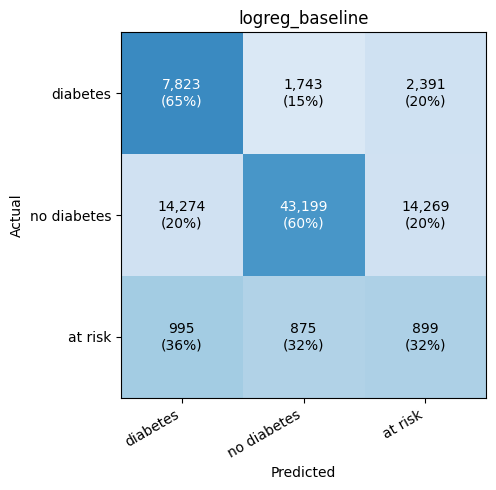

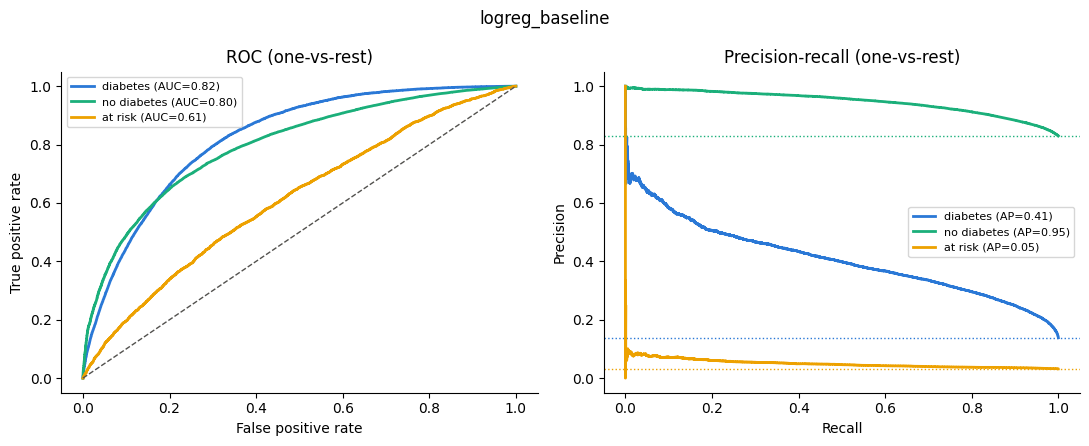

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['bmi', 'age', 'weight_kg',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_week',
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent...
                                                  ['general_health',
                                                   'age_group',
                                                   'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [54]:
baseline_pipeline = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        random_state=RANDOM_STATE)),
])

config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
          "solver": "lbfgs", "max_iter": 1000, "ordinal_encoding": "onehot"}

log_experiment("logreg_baseline", baseline_pipeline, config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


In [55]:
baseline_results = results_log[-1]   # most recent run

screening_summary = pd.DataFrame({
    "metric": [
        "Diabetes: predicted exactly as diabetes (recall)",
        "Diabetes: flagged as diabetes or at risk",
        "Diabetes: missed (predicted no diabetes)",
        "At risk: predicted exactly as at risk (recall)",
        "At risk: flagged as diabetes or at risk",
        "Screening sensitivity (diabetes + at risk combined)",
        "Screening precision (flagged people who truly need follow-up)",
        "Screening specificity (healthy people not flagged)",
        "Screening F2",
        "Screening F1",
        "People flagged (%)",
    ],
    "value": [
        baseline_results["val_recall/diabetes"],
        baseline_results["screen_sensitivity/diabetes"],
        baseline_results["missed/diabetes"],
        baseline_results["val_recall/at risk"],
        baseline_results["screen_sensitivity/at risk"],
        baseline_results["screen_sensitivity"],
        baseline_results["screen_precision"],
        baseline_results["screen_specificity"],
        baseline_results["screen_f2"],
        baseline_results["screen_f1"],
        baseline_results["pct_flagged"],
    ],
})
screening_summary


,metric,value
0,Diabetes: predicted exactly as diabetes (recall),0.6543
1,Diabetes: flagged as diabetes or at risk,0.8542
2,Diabetes: missed (predicted no diabetes),0.1458
3,At risk: predicted exactly as at risk (recall),0.3247
4,At risk: flagged as diabetes or at risk,0.6840
5,Screening sensitivity (diabetes + at risk comb...,0.8222
6,Screening precision (flagged people who truly ...,0.2979
7,Screening specificity (healthy people not flag...,0.6021
8,Screening F2,0.6081
9,Screening F1,0.4373


## Experiment 2: Apply downsampling the majority class, then upsampling the minority class, then reuse the same baseline logistic regression without class weight

[logreg_under_smotenc] SCREENING  sensitivity = 0.603 | precision = 0.364 | F2 = 0.533 | F1 = 0.454 | specificity = 0.784 | flagged = 28.2%
    flagged: diabetes = 0.641 | at risk = 0.436 | diabetics missed = 0.359
    OVERALL  ROC-AUC (OvR) = 0.7305 | macro F1 = 0.4535 | balanced acc = 0.4873 | accuracy = 0.7226
    CV  screening F2 = 0.5346 (+/- 0.0051) | sensitivity = 0.6040 (+/- 0.0063) | precision = 0.3664 (+/- 0.0029) | macro F1 = 0.4568 (+/- 0.0026)
              precision    recall  f1-score   support

    diabetes      0.398     0.473     0.432     11957
 no diabetes      0.906     0.784     0.841     71742
     at risk      0.056     0.205     0.088      2769

    accuracy                          0.723     86468
   macro avg      0.453     0.487     0.454     86468
weighted avg      0.808     0.723     0.760     86468



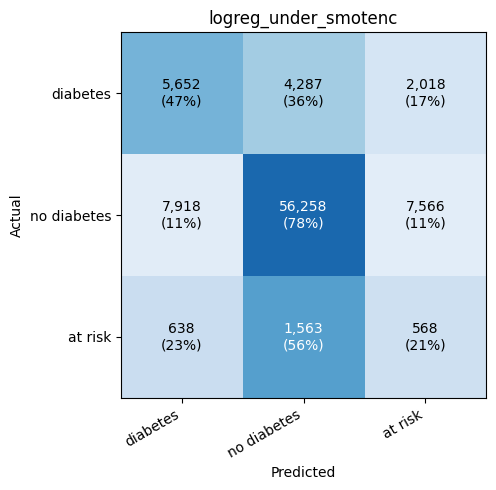

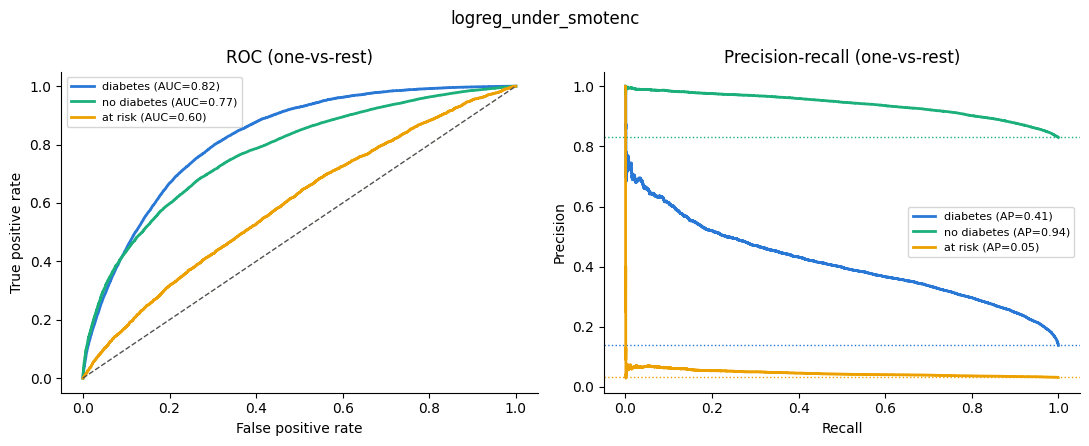

Pipeline(steps=[('impute',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['bmi', 'age', 'weight_kg',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_week',
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['general_health',
                                                   'age_group',
                                                   'smoking_status',
                                                   'cholesterol_check',
                                                   'high_chol...
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['general_health',
                                                   'age_group',
                                                   'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin', 'passthrough',
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [56]:
from collections import Counter
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC


def undersample_no_diabetes(class_labels):
    """Keep 'no diabetes' (3) at 3x the number of diabetes cases."""
    class_counts = Counter(class_labels)
    return {3: min(class_counts[3], 3 * class_counts[1])}


def oversample_minorities(class_labels):
    """Grow diabetes (1) and at risk (4) to half the size of the (undersampled) majority."""
    class_counts = Counter(class_labels)
    target_count = class_counts[3] // 2
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

resampled_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("undersample", RandomUnderSampler(sampling_strategy=undersample_no_diabetes,
                                       random_state=RANDOM_STATE)),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_minorities,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles the imbalance
])

resampled_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                    "resampling": "undersample 3x + SMOTENC to 1/2"}

log_experiment("logreg_under_smotenc", resampled_pipeline, resampled_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


## Experiment 3: Oversampling to the majority class only

[logreg_smotenc_1to1] SCREENING  sensitivity = 0.752 | precision = 0.282 | F2 = 0.564 | F1 = 0.410 | specificity = 0.606 | flagged = 45.5%
    flagged: diabetes = 0.782 | at risk = 0.622 | diabetics missed = 0.218
    OVERALL  ROC-AUC (OvR) = 0.7121 | macro F1 = 0.4146 | balanced acc = 0.4980 | accuracy = 0.5935
    CV  screening F2 = 0.5651 (+/- 0.0009) | sensitivity = 0.7507 (+/- 0.0040) | precision = 0.2842 (+/- 0.0015) | macro F1 = 0.4183 (+/- 0.0013)
              precision    recall  f1-score   support

    diabetes      0.347     0.585     0.436     11957
 no diabetes      0.923     0.606     0.732     71742
     at risk      0.044     0.303     0.076      2769

    accuracy                          0.594     86468
   macro avg      0.438     0.498     0.415     86468
weighted avg      0.815     0.594     0.670     86468



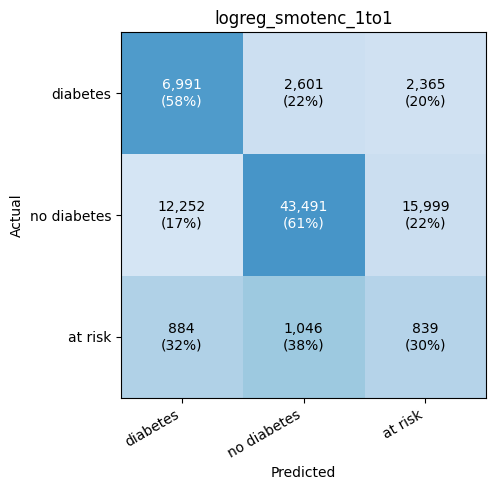

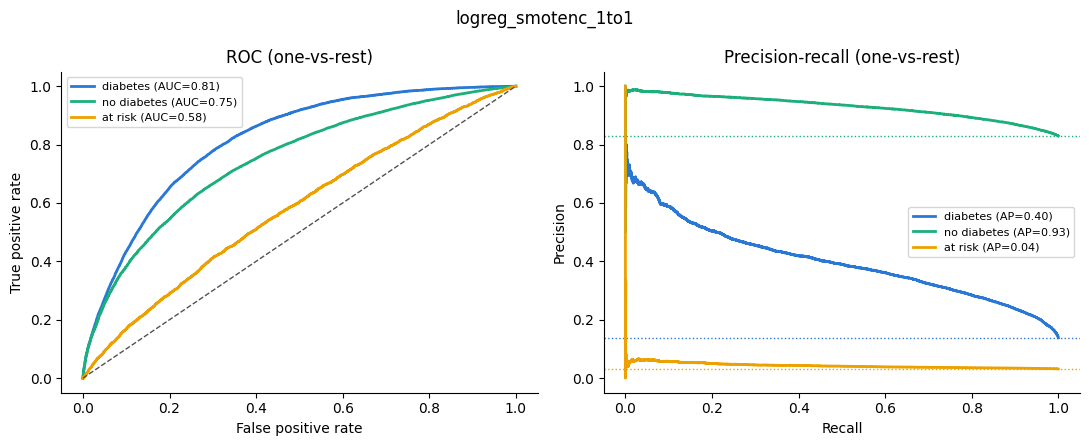

Pipeline(steps=[('impute',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['bmi', 'age', 'weight_kg',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_week',
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['general_health',
                                                   'age_group',
                                                   'smoking_status',
                                                   'cholesterol_check',
                                                   'high_chol...
                                                   'strength_training_per_week']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['general_health',
                                                   'age_group',
                                                   'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin', 'passthrough',
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [57]:
from collections import Counter
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC


def oversample_to_majority(class_labels, share_of_majority=1.0):
    """Grow diabetes (1) and at risk (4) to a share of the 'no diabetes' (3) count."""
    class_counts = Counter(class_labels)
    target_count = int(class_counts[3] * share_of_majority)
    return {1: max(class_counts[1], target_count), 4: max(class_counts[4], target_count)}


# Step 1: impute only (SMOTENC needs the original categories, before one-hot encoding)
impute_step = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_cols + binary_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

# Step 2: scale and one-hot encode, after resampling
encode_step = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", binary_cols),
])

oversample_pipeline = ImbPipeline([
    ("impute", impute_step),
    ("oversample", SMOTENC(categorical_features=cat_cols + binary_cols,
                           sampling_strategy=oversample_to_majority,
                           random_state=RANDOM_STATE)),
    ("encode", encode_step),
    ("clf", LogisticRegression(max_iter=1000, C=1.0, solver="lbfgs",
                               random_state=RANDOM_STATE)),   # no class_weight: resampling handles it
])

oversample_config = {"model": "LogisticRegression", "C": 1.0, "class_weight": "none",
                     "resampling": "SMOTENC to 1:1:1, no undersampling"}

log_experiment("logreg_smotenc_1to1", oversample_pipeline, oversample_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


## Training with Ensemble Model: Random Forest

[rf_depth6_leaf50_estimators_500] SCREENING  sensitivity = 0.820 | precision = 0.300 | F2 = 0.609 | F1 = 0.439 | specificity = 0.606 | flagged = 46.6%
    flagged: diabetes = 0.853 | at risk = 0.680 | diabetics missed = 0.147
    OVERALL  ROC-AUC (OvR) = 0.7455 | macro F1 = 0.4200 | balanced acc = 0.5255 | accuracy = 0.6133
    CV  screening F2 = 0.6105 (+/- 0.0015) | sensitivity = 0.8222 (+/- 0.0025) | precision = 0.3008 (+/- 0.0016) | macro F1 = 0.4230 (+/- 0.0019)
              precision    recall  f1-score   support

    diabetes      0.304     0.744     0.431     11957
 no diabetes      0.943     0.606     0.738     71742
     at risk      0.057     0.226     0.091      2769

    accuracy                          0.613     86468
   macro avg      0.434     0.525     0.420     86468
weighted avg      0.826     0.613     0.675     86468



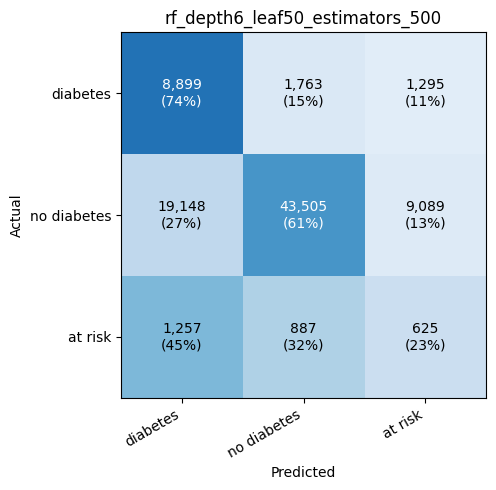

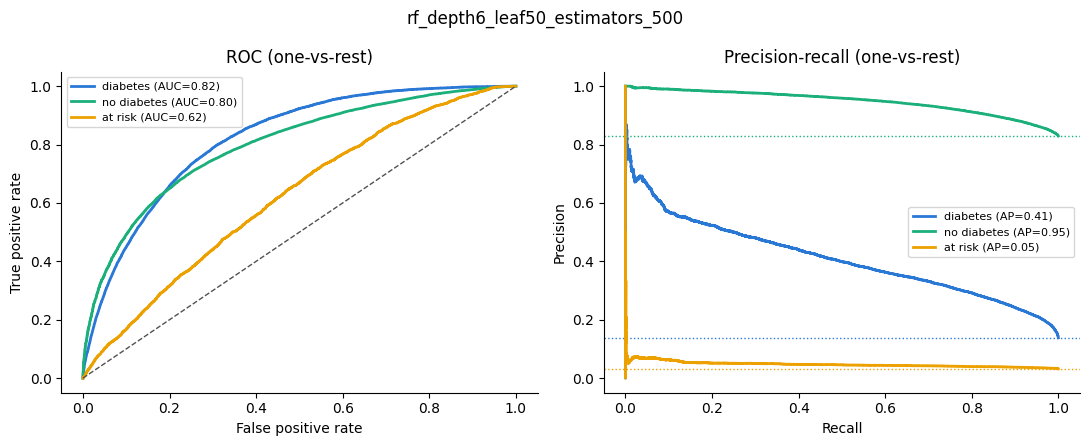

RandomForestClassifier(class_weight='balanced_subsample', max_depth=6,
                       min_samples_leaf=50, n_estimators=500, n_jobs=-1,
                       random_state=42)

In [58]:
forest_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced_subsample",
    max_depth=6,
    min_samples_leaf=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 500,
                 "class_weight": "balanced_subsample", "max_depth": 6,
                 "min_samples_leaf": 50, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth6_leaf50_estimators_500", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


[rf_depth12_leaf100_estimators_1000] SCREENING  sensitivity = 0.810 | precision = 0.309 | F2 = 0.611 | F1 = 0.447 | specificity = 0.627 | flagged = 44.7%
    flagged: diabetes = 0.845 | at risk = 0.662 | diabetics missed = 0.155
    OVERALL  ROC-AUC (OvR) = 0.7518 | macro F1 = 0.4284 | balanced acc = 0.5292 | accuracy = 0.6304
    CV  screening F2 = 0.6122 (+/- 0.0014) | sensitivity = 0.8106 (+/- 0.0027) | precision = 0.3094 (+/- 0.0023) | macro F1 = 0.4310 (+/- 0.0024)
              precision    recall  f1-score   support

    diabetes      0.312     0.746     0.440     11957
 no diabetes      0.942     0.627     0.753     71742
     at risk      0.059     0.214     0.092      2769

    accuracy                          0.630     86468
   macro avg      0.437     0.529     0.428     86468
weighted avg      0.826     0.630     0.688     86468



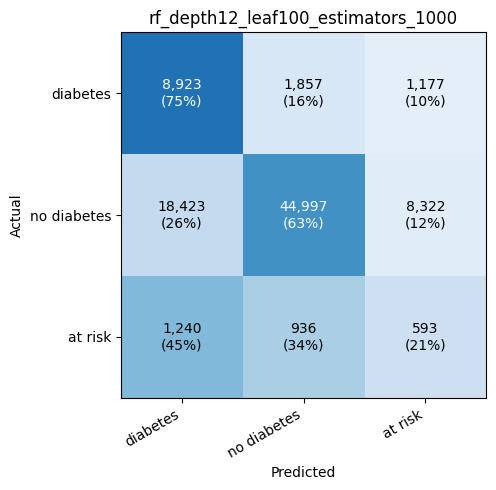

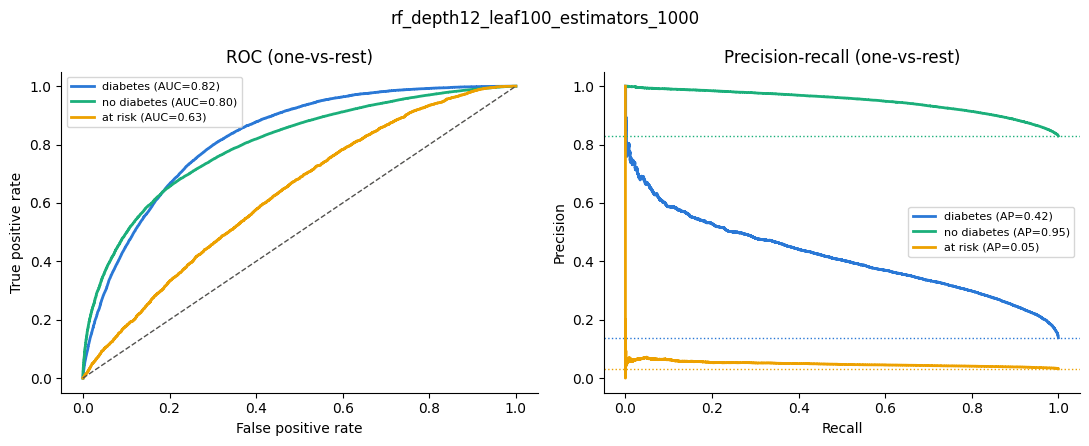

RandomForestClassifier(class_weight='balanced_subsample', max_depth=12,
                       min_samples_leaf=100, n_estimators=1000, n_jobs=-1,
                       random_state=42)

In [59]:
forest_model = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 1000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_1000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


In [ ]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 12,
                 "min_samples_leaf": 100, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth12_leaf100_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


[rf_depth18_leaf200_estimators_2000] SCREENING  sensitivity = 0.816 | precision = 0.304 | F2 = 0.611 | F1 = 0.443 | specificity = 0.617 | flagged = 45.7%
    flagged: diabetes = 0.849 | at risk = 0.675 | diabetics missed = 0.151
    OVERALL  ROC-AUC (OvR) = 0.7507 | macro F1 = 0.4262 | balanced acc = 0.5310 | accuracy = 0.6213
    CV  screening F2 = 0.6116 (+/- 0.0012) | sensitivity = 0.8175 (+/- 0.0024) | precision = 0.3046 (+/- 0.0020) | macro F1 = 0.4281 (+/- 0.0021)
              precision    recall  f1-score   support

    diabetes      0.313     0.737     0.439     11957
 no diabetes      0.942     0.617     0.746     71742
     at risk      0.058     0.239     0.094      2769

    accuracy                          0.621     86468
   macro avg      0.438     0.531     0.426     86468
weighted avg      0.827     0.621     0.682     86468



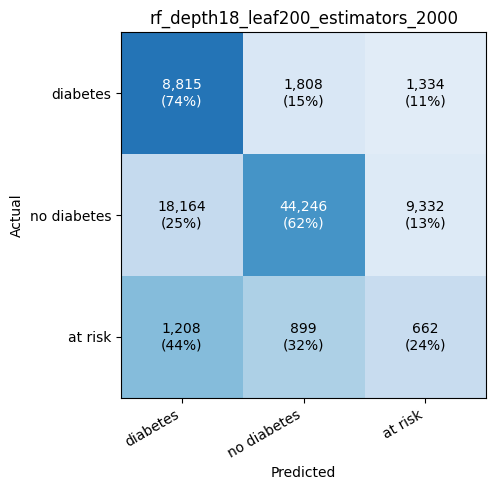

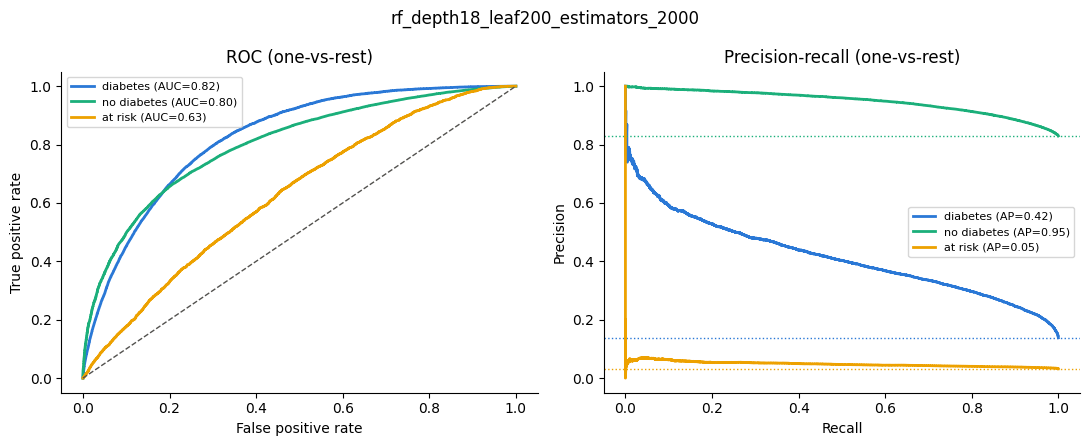

RandomForestClassifier(class_weight='balanced_subsample', max_depth=18,
                       min_samples_leaf=200, n_estimators=2000, n_jobs=-1,
                       random_state=42)

In [61]:
forest_model = RandomForestClassifier(
    n_estimators=2000,
    class_weight="balanced_subsample",
    max_depth=18,
    min_samples_leaf=200,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

forest_config = {"model": "RandomForest", "n_estimators": 2000,
                 "class_weight": "balanced_subsample", "max_depth": 18,
                 "min_samples_leaf": 200, "max_features": "sqrt",
                 "missing_values": "native"}

log_experiment("rf_depth18_leaf200_estimators_2000", forest_model, forest_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


## Notice
Across the random forest variants tested so far, none outperformed the logistic regression baseline on screening F2 (best = 0.61 for both). Since random forests can capture non-linear effects and interactions between features, this suggests that the relationship between the survey answers and diabetes status is largely additive, a pattern a linear model already captures well. It also suggests that several features add little information beyond others (for example, age_group repeats age, and bmi combines height_inches and weight_kg).

To quantify each feature's contribution, we run permutation importance on the baseline logistic regression model: each feature is shuffled in turn, and the resulting drop in screening F2 on the validation set measures how much the model relies on it.


In [62]:
fitted_baseline = baseline_pipeline   # already fitted by log_experiment

importance_result = permutation_importance(
    fitted_baseline, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": importance_result.importances_mean,
    "f2_drop_std": importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

feature_importance


,feature,f2_drop_mean,f2_drop_std
7,general_health,0.040852,0.001325
0,age,0.040331,0.000554
1,bmi,0.036615,0.000706
12,high_blood_pressure,0.022184,0.001284
9,high_cholesterol,0.016621,0.001111
3,drink_occasions_per_day,0.011818,0.000865
10,cholesterol_check,0.007197,0.000617
8,age_group,0.005043,0.001299
15,heart_disease,0.002904,0.000474
16,difficulty_walking,0.002004,0.000291


Attempt training baseline with 13 features

[logreg_13_features] SCREENING  sensitivity = 0.812 | precision = 0.305 | F2 = 0.609 | F1 = 0.444 | specificity = 0.621 | flagged = 45.3%
    flagged: diabetes = 0.846 | at risk = 0.666 | diabetics missed = 0.154
    OVERALL  ROC-AUC (OvR) = 0.7395 | macro F1 = 0.4261 | balanced acc = 0.5255 | accuracy = 0.6149
    CV  screening F2 = 0.6081 (+/- 0.0018) | sensitivity = 0.8096 (+/- 0.0038) | precision = 0.3048 (+/- 0.0012) | macro F1 = 0.4268 (+/- 0.0005)
              precision    recall  f1-score   support

    diabetes      0.330     0.652     0.438     11957
 no diabetes      0.941     0.621     0.748     71742
     at risk      0.054     0.303     0.092      2769

    accuracy                          0.615     86468
   macro avg      0.442     0.525     0.426     86468
weighted avg      0.828     0.615     0.684     86468



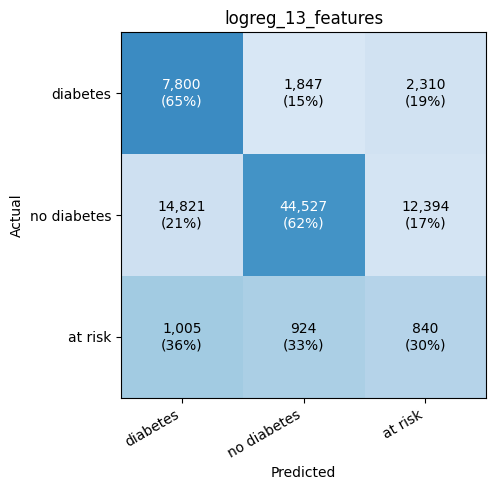

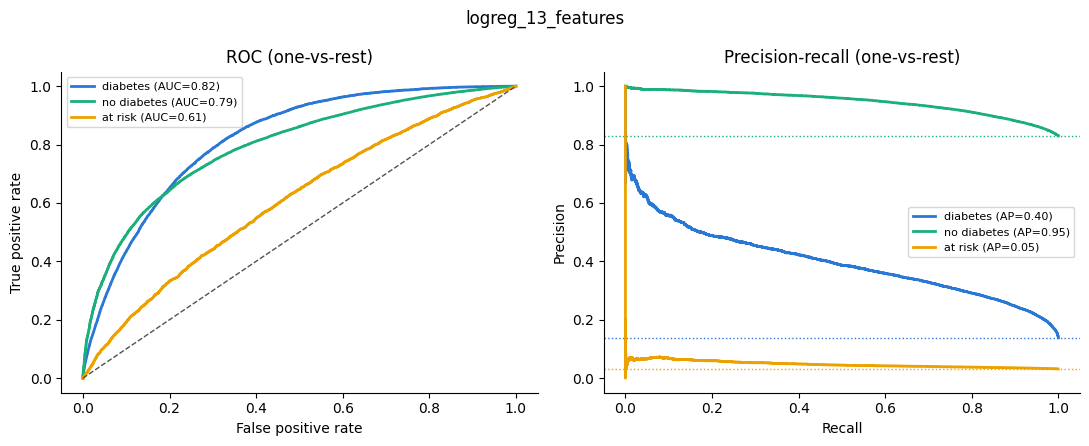

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['bmi', 'age', 'weight_kg',
                                                   'drink_occasions_per_day']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['general_health',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['high_blood_pressure',
                                                   'heart_disease',
                                                   'kidney_disease',
                                                   'difficulty_walking'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [63]:
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day",
    # ordinal / categorical
    "general_health", "cholesterol_check", "high_cholesterol", "education", "income",
    # binary
    "high_blood_pressure", "heart_disease", "kidney_disease", "difficulty_walking",
]
selected_features = [column for column in selected_features if column in SELECTED_FEATURES]   # only columns kept in this notebook

selected_numeric_cols = [column for column in numeric_cols if column in selected_features]
selected_cat_cols = [column for column in cat_cols if column in selected_features]
selected_binary_cols = [column for column in binary_cols if column in selected_features]

selected_preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), selected_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), selected_cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), selected_binary_cols),
])

selected_pipeline = Pipeline([
    ("prep", selected_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

selected_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                   "n_features": len(selected_features), "features": "top-13 by permutation F2"}

log_experiment("logreg_13_features", selected_pipeline, selected_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=True)


[lgbm_baseline] SCREENING  sensitivity = 0.803 | precision = 0.312 | F2 = 0.611 | F1 = 0.449 | specificity = 0.636 | flagged = 43.9%
    flagged: diabetes = 0.838 | at risk = 0.655 | diabetics missed = 0.162
    OVERALL  ROC-AUC (OvR) = 0.7496 | macro F1 = 0.4312 | balanced acc = 0.5276 | accuracy = 0.6342
    CV  screening F2 = 0.6082 (+/- 0.0019) | sensitivity = 0.7917 (+/- 0.0044) | precision = 0.3156 (+/- 0.0010) | macro F1 = 0.4343 (+/- 0.0014)
              precision    recall  f1-score   support

    diabetes      0.322     0.718     0.445     11957
 no diabetes      0.940     0.636     0.759     71742
     at risk      0.056     0.229     0.090      2769

    accuracy                          0.634     86468
   macro avg      0.440     0.528     0.431     86468
weighted avg      0.826     0.634     0.694     86468



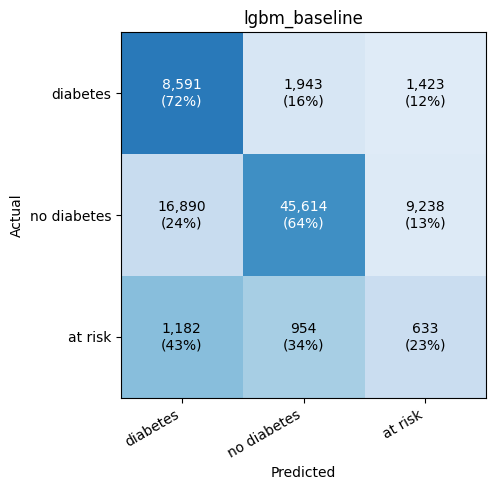

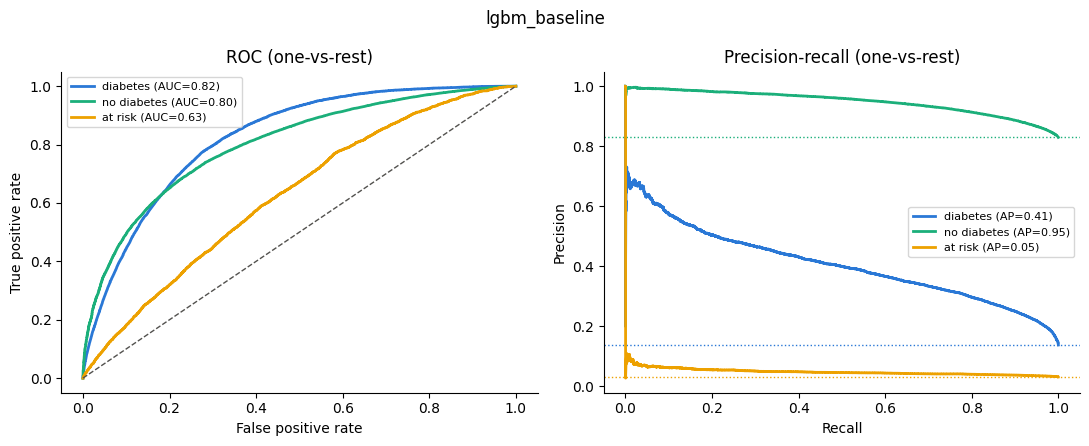

LGBMClassifier(class_weight='balanced', colsample_bytree=0.8,
               learning_rate=0.05, min_child_samples=50, n_estimators=1000,
               n_jobs=-1, random_state=42, subsample=0.8, subsample_freq=1,
               verbose=-1)

In [64]:
from lightgbm import LGBMClassifier

lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,      # like min_samples_leaf in the forest: lets the class weights work
    subsample=0.8,             # each tree sees 80% of the rows...
    subsample_freq=1,          # ...re-drawn for every tree
    colsample_bytree=0.8,      # each tree sees 80% of the features
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,                # hide LightGBM's training messages
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

log_experiment("lgbm_baseline", lightgbm_model, lightgbm_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


In [65]:
fitted_lightgbm = lightgbm_model   # already fitted by log_experiment

lightgbm_importance_result = permutation_importance(
    fitted_lightgbm, X_val, Y_val,
    scoring=make_scorer(screen_f2),
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=2,
)

lightgbm_feature_importance = pd.DataFrame({
    "feature": X_val.columns,
    "f2_drop_mean": lightgbm_importance_result.importances_mean,
    "f2_drop_std": lightgbm_importance_result.importances_std,
}).sort_values("f2_drop_mean", ascending=False)

lightgbm_feature_importance


,feature,f2_drop_mean,f2_drop_std
7,general_health,0.031837,0.001252
0,age,0.027852,0.001773
1,bmi,0.022415,0.001124
12,high_blood_pressure,0.020884,0.001617
9,high_cholesterol,0.014335,0.000510
3,drink_occasions_per_day,0.011642,0.001112
10,cholesterol_check,0.010833,0.000981
8,age_group,0.007617,0.000842
13,sex,0.004170,0.000680
4,drinks_per_week,0.004132,0.000928


[lgbm_18_clinical_original] SCREENING  sensitivity = 0.804 | precision = 0.309 | F2 = 0.609 | F1 = 0.447 | specificity = 0.632 | flagged = 44.3%
    flagged: diabetes = 0.839 | at risk = 0.653 | diabetics missed = 0.161
    OVERALL  ROC-AUC (OvR) = 0.7494 | macro F1 = 0.4300 | balanced acc = 0.5275 | accuracy = 0.6304
    CV  screening F2 = 0.6092 (+/- 0.0014) | sensitivity = 0.7966 (+/- 0.0030) | precision = 0.3138 (+/- 0.0012) | macro F1 = 0.4333 (+/- 0.0018)
              precision    recall  f1-score   support

    diabetes      0.323     0.715     0.445     11957
 no diabetes      0.940     0.632     0.756     71742
     at risk      0.055     0.236     0.090      2769

    accuracy                          0.630     86468
   macro avg      0.439     0.527     0.430     86468
weighted avg      0.826     0.630     0.691     86468



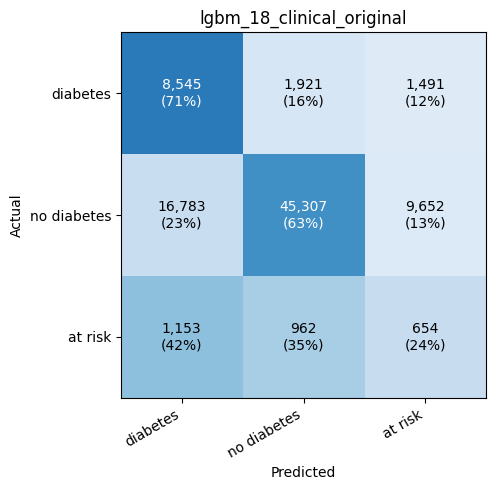

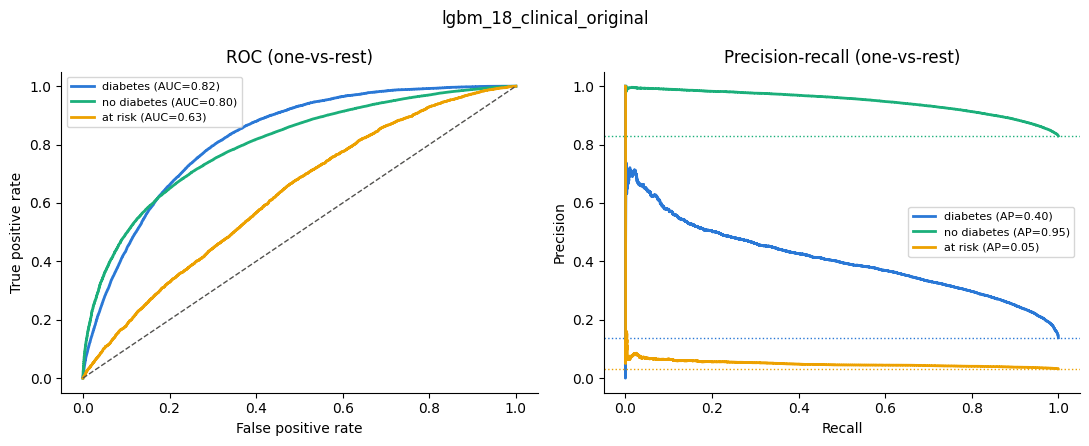

LGBMClassifier(class_weight='balanced', colsample_bytree=0.8,
               learning_rate=0.05, min_child_samples=50, n_estimators=1000,
               n_jobs=-1, random_state=42, subsample=0.8, subsample_freq=1,
               verbose=-1)

In [66]:
# train with selected value
selected_features = [
    # numeric
    "age", "bmi", "weight_kg", "drink_occasions_per_day", "drinks_per_week",
    "exercise_minutes_per_week",
    # ordinal / categorical
    "general_health", "high_cholesterol", "cholesterol_check", "smoking_status",
    # binary
    "high_blood_pressure", "sex", "kidney_disease", "heart_disease",
    "difficulty_walking", "physical_activity", "stroke", "heavy_drinker", 
]
selected_features = [column for column in selected_features if column in SELECTED_FEATURES]   # only columns kept in this notebook

lightgbm_model = LGBMClassifier(
    class_weight="balanced",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,      # like min_samples_leaf in the forest: lets the class weights work
    subsample=0.8,             # each tree sees 80% of the rows...
    subsample_freq=1,          # ...re-drawn for every tree
    colsample_bytree=0.8,      # each tree sees 80% of the features
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,                # hide LightGBM's training messages
)

lightgbm_config = {"model": "LightGBM", "class_weight": "balanced", "n_estimators": 1000,
                   "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
                   "subsample": 0.8, "colsample_bytree": 0.8, "categorical": "ordinal as numbers"}

lightgbm_reduced_config = {**lightgbm_config, "n_features": len(selected_features),
                           "features": "18: permutation F2 + clinical risk factors"}

log_experiment("lgbm_18_clinical_original", lightgbm_model, lightgbm_reduced_config,
               X_train[selected_features], Y_train, X_val[selected_features], Y_val, do_cv=True)


[logreg_splines_age_bmi] SCREENING  sensitivity = 0.822 | precision = 0.297 | F2 = 0.608 | F1 = 0.437 | specificity = 0.601 | flagged = 47.1%
    flagged: diabetes = 0.854 | at risk = 0.684 | diabetics missed = 0.146
    OVERALL  ROC-AUC (OvR) = 0.7436 | macro F1 = 0.4232 | balanced acc = 0.5272 | accuracy = 0.5997
    CV  screening F2 = 0.6072 (+/- 0.0016) | sensitivity = 0.8215 (+/- 0.0039) | precision = 0.2971 (+/- 0.0014) | macro F1 = 0.4246 (+/- 0.0022)
              precision    recall  f1-score   support

    diabetes      0.339     0.654     0.447     11957
 no diabetes      0.943     0.601     0.734     71742
     at risk      0.051     0.327     0.088      2769

    accuracy                          0.600     86468
   macro avg      0.444     0.527     0.423     86468
weighted avg      0.831     0.600     0.674     86468



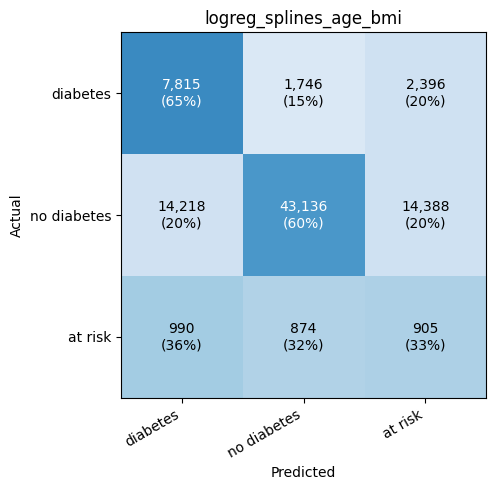

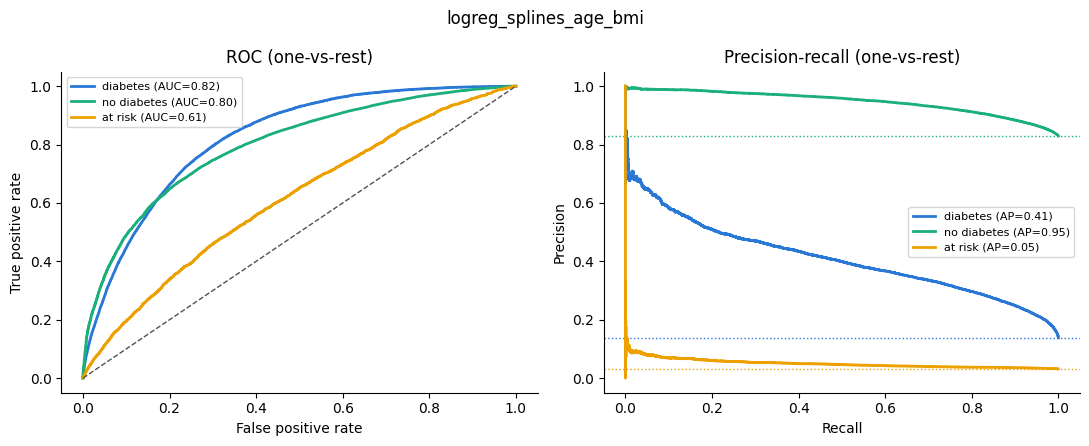

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('spline',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('spline',
                                                                   SplineTransformer())]),
                                                  ['age', 'bmi']),
                                                 ('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['weight_kg',
                                                   'drinks_per_week',
                                                   'drink_occasions_per_day',
                                                   'exercise_minutes_per_w...
                                                  ['general_health',
                                                   'age_group',
                                                   'smoking_status',
                                                   'cholesterol_check',
                                                   'high_cholesterol']),
                                                 ('bin',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['high_blood_pressure',
                                                   'stroke', 'heart_disease',
                                                   'kidney_disease',
                                                   'physical_activity',
                                                   'heavy_drinker',
                                                   'difficulty_walking',
                                                   'sex'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [67]:
from sklearn.preprocessing import SplineTransformer

spline_cols = ["age", "bmi"]
other_numeric_cols = [column for column in numeric_cols if column not in spline_cols]

spline_preprocess = ColumnTransformer([
    ("spline", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("spline", SplineTransformer(n_knots=5, degree=3)),
    ]), spline_cols),
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), other_numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])

spline_pipeline = Pipeline([
    ("prep", spline_preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0,
                               solver="lbfgs", random_state=RANDOM_STATE)),
])

spline_config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
                 "splines": "age, bmi (5 knots, cubic)"}

log_experiment("logreg_splines_age_bmi", spline_pipeline, spline_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 380, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 90, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/

[xgb_depth4_lr0.05_trees500] SCREENING  sensitivity = 0.834 | precision = 0.295 | F2 = 0.611 | F1 = 0.436 | specificity = 0.591 | flagged = 48.1%
    flagged: diabetes = 0.862 | at risk = 0.714 | diabetics missed = 0.138
    OVERALL  ROC-AUC (OvR) = 0.7524 | macro F1 = 0.4227 | balanced acc = 0.5369 | accuracy = 0.5982
    CV  screening F2 = 0.6098 (+/- 0.0009) | sensitivity = 0.8303 (+/- 0.0026) | precision = 0.2957 (+/- 0.0011) | macro F1 = 0.4242 (+/- 0.0014)
              precision    recall  f1-score   support

    diabetes      0.327     0.706     0.447     11957
 no diabetes      0.946     0.591     0.728     71742
     at risk      0.055     0.313     0.093      2769

    accuracy                          0.598     86468
   macro avg      0.443     0.537     0.423     86468
weighted avg      0.832     0.598     0.668     86468



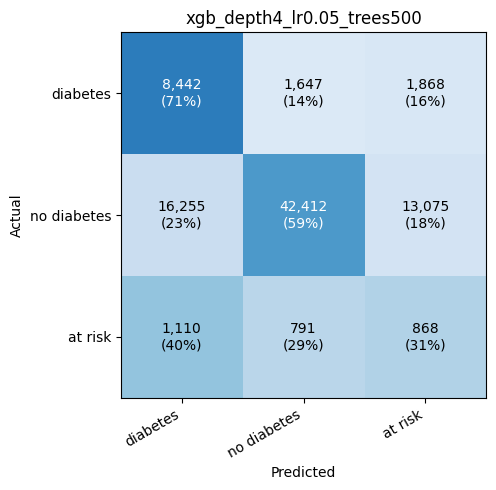

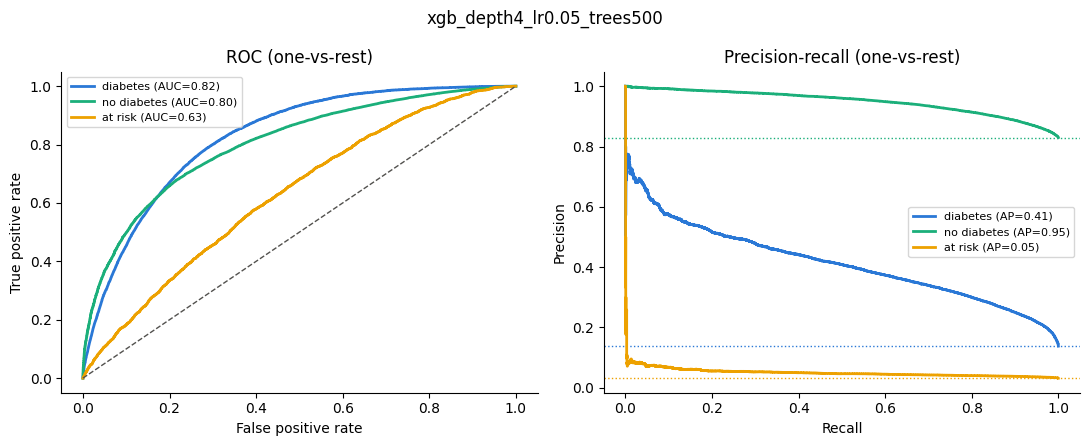

BalancedXGBClassifier(xgb_params={'colsample_bytree': 0.8,
                                  'learning_rate': 0.05, 'max_depth': 4,
                                  'min_child_weight': 5, 'n_estimators': 500,
                                  'n_jobs': -1, 'random_state': 42,
                                  'subsample': 0.8, 'tree_method': 'hist'})

In [68]:
from xgboost import XGBClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.class_weight import compute_sample_weight


class BalancedXGBClassifier(BaseEstimator, ClassifierMixin):
    """XGBoost with labels 1/3/4 and balanced class weights.
    XGBoost needs labels 0..K-1 and has no class_weight option for multiclass,
    so labels are encoded and balanced sample weights are passed in fit()."""

    def __init__(self, use_class_weights=True, xgb_params=None):
        self.use_class_weights = use_class_weights
        self.xgb_params = xgb_params

    def fit(self, X, y):
        self.classes_ = np.sort(np.unique(y))
        class_to_index = {class_code: class_index for class_index, class_code in enumerate(self.classes_)}
        encoded_labels = np.asarray(pd.Series(np.asarray(y)).map(class_to_index), dtype=int)
        sample_weight = compute_sample_weight("balanced", encoded_labels) if self.use_class_weights else None
        self.booster_model_ = XGBClassifier(**(self.xgb_params or {}))
        self.booster_model_.fit(X, encoded_labels, sample_weight=sample_weight)
        return self

    def predict_proba(self, X):
        return self.booster_model_.predict_proba(X)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

xgb_params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 4,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

xgboost_model = BalancedXGBClassifier(xgb_params=xgb_params)

xgboost_config = {"model": "XGBoost", "class_weight": "balanced (sample weights)", **xgb_params}

log_experiment("xgb_depth4_lr0.05_trees500", xgboost_model, xgboost_config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


## Deep Neurone Network

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight

In [70]:
network_preprocess = clone(preprocess)
prepared_train = network_preprocess.fit_transform(X_train)
prepared_val = network_preprocess.transform(X_val)
prepared_test = network_preprocess.transform(X_test)

In [71]:
def to_dense_float32(prepared_matrix):
    if hasattr(prepared_matrix, "toarray"):      # sparse -> dense
        prepared_matrix = prepared_matrix.toarray()
    return np.asarray(prepared_matrix, dtype="float32")

prepared_train = to_dense_float32(prepared_train)
prepared_val = to_dense_float32(prepared_val)
prepared_test = to_dense_float32(prepared_test)

In [72]:
def plot_training_curves(training_history, run_name, metric_names=None, columns_per_row=4):
    """Training vs validation curve for every metric, one small chart per metric.
    The dashed line marks the epoch with the lowest validation loss."""
    if metric_names is None:
        metric_names = [name for name in training_history if not name.startswith("val_")
                        and f"val_{name}" in training_history]
    epochs = np.arange(1, len(training_history["loss"]) + 1)
    best_epoch = int(np.argmin(training_history["val_loss"])) + 1

    row_count = int(np.ceil(len(metric_names) / columns_per_row))
    figure, axes_grid = plt.subplots(row_count, columns_per_row,
                                     figsize=(4 * columns_per_row, 3.2 * row_count), squeeze=False)
    for chart_axis, metric_name in zip(axes_grid.flat, metric_names):
        chart_axis.plot(epochs, training_history[metric_name], color="#2a78d6", linewidth=2, label="training")
        chart_axis.plot(epochs, training_history[f"val_{metric_name}"], color="#eb6834", linewidth=2, label="validation")
        chart_axis.axvline(best_epoch, color="#52514e", linewidth=1, linestyle="--")
        chart_axis.set_title(metric_name.replace("_", " "), fontsize=10)
        chart_axis.set_xlabel("epoch", fontsize=8)
        chart_axis.tick_params(labelsize=8)
        chart_axis.grid(axis="y", color="#e5e5e3", linewidth=0.8)
        chart_axis.set_axisbelow(True)
        for side in ["top", "right"]:
            chart_axis.spines[side].set_visible(False)
    for unused_axis in list(axes_grid.flat)[len(metric_names):]:
        unused_axis.set_visible(False)

    legend_handles, legend_labels = axes_grid.flat[0].get_legend_handles_labels()
    figure.legend(legend_handles + [plt.Line2D([], [], color="#52514e", linestyle="--")],
                  legend_labels + [f"lowest validation loss (epoch {best_epoch})"],
                  loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
    figure.suptitle(f"{run_name}: training vs validation per epoch", y=1.04, fontsize=12)
    figure.tight_layout()
    plt.show()
    return figure

In [73]:
label_to_index = {1: 0, 3: 1, 4: 2}
index_to_label = np.array([1, 3, 4])            # to convert predictions back to the original classes

train_label_indices = Y_train.map(label_to_index).values
val_label_indices = Y_val.map(label_to_index).values

train_labels_one_hot = keras.utils.to_categorical(train_label_indices, num_classes=3)
val_labels_one_hot = keras.utils.to_categorical(val_label_indices, num_classes=3)

In [74]:
train_dataset = (tf.data.Dataset.from_tensor_slices((prepared_train, train_labels_one_hot))
                 .shuffle(buffer_size=len(prepared_train), seed=RANDOM_STATE)
                 .batch(512)
                 .prefetch(tf.data.AUTOTUNE))

# no shuffle: predictions must stay in the same order as Y_val
val_dataset = (tf.data.Dataset.from_tensor_slices((prepared_val, val_labels_one_hot))
               .batch(512)
               .prefetch(tf.data.AUTOTUNE))

I0000 00:00:1792160793.742595      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13552 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792160793.745701      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [75]:
def build_network(
        n_features=prepared_train.shape[1],
        hidden_units=(256, 128, 64, 64),
        dropout_rate=0.0,
        l2=0.0,
        learning_rate=1e-3,
        ):
    """Builds a dense network for the 3-class target (softmax output) and its Adam optimizer.
    hidden_units sets the capacity: one Dense layer per entry, the entry is the layer width."""

    weight_regularizer = keras.regularizers.l2(l2) if l2 > 0 else None
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate)
    inputs = keras.Input(shape=(n_features,), name="Features")
    x = inputs

    for layer_number, layer_width in enumerate(hidden_units, start=1):
        x = layers.Dense(
            layer_width,
            kernel_regularizer=weight_regularizer,
            activation="relu",
            use_bias=True,
            name=f"dense_{layer_number}",
        )(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate, name=f"dropout_{layer_number}")(x)

    outputs = layers.Dense(3, activation="softmax", name="output")(x)

    model = keras.Model(inputs, outputs, name="tabular_net")
    return model, optimizer

In [76]:
def keras_metrics():
    metric_list = [
        "accuracy",
        keras.metrics.AUC(name="auc", multi_label=True, num_labels=3),        # one-vs-rest AUC, averaged
        keras.metrics.AUC(name="pr_auc", curve="PR", multi_label=True, num_labels=3),
        keras.metrics.F1Score(name="f1_macro", average="macro"),
        keras.metrics.FBetaScore(name="f2_macro", beta=2.0, average="macro")
        ]

    class_index_names = {0: "diabetes", 1: "no_diabetes", 2: "at_risk"}
    

    for class_index, class_name in class_index_names.items():
        metric_list.append(keras.metrics.Precision(class_id=class_index, top_k=1, name=f"precision_{class_name}"))   # top_k=1: highest-probability class, as in the classical models
        metric_list.append(keras.metrics.Recall(class_id=class_index, top_k=1, name=f"recall_{class_name}"))
    return metric_list


In [77]:
def compiled_network(network_model, metrics):
    net_model, optimizer = network_model
    model = net_model
    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=metrics)
    return model

# test model
model = compiled_network(network_model=build_network(), metrics=keras_metrics())
model.summary()

Model: "tabular_net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Features (InputLayer)           │ (None, 43)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        11,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,771 (221.76 KB)

 Trainable params: 56,771 (221.76 KB)

 Non-trainable params: 0 (0.00 B)

In [78]:
# Balanced class weights, the same imbalance handling as the classical models
class_weight_values = compute_class_weight("balanced", classes=np.arange(3), y=train_label_indices)
class_weight = {class_index: float(weight) for class_index, weight in enumerate(class_weight_values)}
print("class weights:", class_weight)


def train_network(network, run_name, epochs=30, extra_callbacks=None):
    """Trains a freshly built network and logs it to its own TensorBoard folder.
    Always pass a newly built model: calling fit on the same model again continues from its old weights."""
    tensorboard_callback = keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, run_name))
    return network.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=[tensorboard_callback] + list(extra_callbacks or []),
        verbose=2,                      # one line per epoch
    )

class weights: {0: 2.410450118941421, 1: 0.4017584861593169, 2: 10.40775958915102}


In [79]:
from sklearn.base import BaseEstimator, ClassifierMixin


class TrainedNetworkAdapter(BaseEstimator, ClassifierMixin):
    """Wraps an already trained Keras network so log_experiment can evaluate it like the classical models.
    fit() does nothing (the network is already trained); predictions use the highest-probability class.
    Use with do_cv=False: there is nothing to cross-validate because fit() does not train."""

    def __init__(self, network):
        self.network = network

    def fit(self, X, y):
        self.classes_ = index_to_label                      # [1, 3, 4], the original class codes
        return self

    def predict_proba(self, X):
        prepared_features = to_dense_float32(network_preprocess.transform(X))
        return self.network.predict(prepared_features, batch_size=512, verbose=0)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

In [80]:
# Baseline: no early stopping and no learning-rate schedule, to see whether it overfits
history = train_network(model, run_name="baseline_neurone_network", epochs=30)

Epoch 1/30


I0000 00:00:1792160803.326606     846 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


507/507 - 19s - 37ms/step - accuracy: 0.5838 - auc: 0.7444 - f1_macro: 0.4149 - f2_macro: 0.4502 - loss: 0.9511 - pr_auc: 0.4668 - precision_at_risk: 0.0531 - precision_diabetes: 0.3190 - precision_no_diabetes: 0.9451 - recall_at_risk: 0.3142 - recall_diabetes: 0.7091 - recall_no_diabetes: 0.5733 - val_accuracy: 0.6216 - val_auc: 0.7487 - val_f1_macro: 0.4276 - val_f2_macro: 0.4635 - val_loss: 0.8649 - val_pr_auc: 0.4722 - val_precision_at_risk: 0.0558 - val_precision_diabetes: 0.3210 - val_precision_no_diabetes: 0.9407 - val_recall_at_risk: 0.2463 - val_recall_diabetes: 0.7270 - val_recall_no_diabetes: 0.6185
Epoch 2/30
507/507 - 5s - 10ms/step - accuracy: 0.5904 - auc: 0.7550 - f1_macro: 0.4193 - f2_macro: 0.4567 - loss: 0.9377 - pr_auc: 0.4717 - precision_at_risk: 0.0562 - precision_diabetes: 0.3208 - precision_no_diabetes: 0.9452 - recall_at_risk: 0.3160 - recall_diabetes: 0.7240 - recall_no_diabetes: 0.5787 - val_accuracy: 0.6327 - val_auc: 0.7507 - val_f1_macro: 0.4297 - val_f2_m

In [81]:
model.evaluate(val_dataset)

169/169 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5856 - auc: 0.7103 - f1_macro: 0.4067 - f2_macro: 0.4340 - loss: 0.8787 - pr_auc: 0.4484 - precision_at_risk: 0.0456 - precision_diabetes: 0.3111 - precision_no_diabetes: 0.9368 - recall_at_risk: 0.2759 - recall_diabetes: 0.6416 - recall_no_diabetes: 0.5883


[0.8786886930465698,
 0.5856386423110962,
 0.7102580070495605,
 0.4484049379825592,
 0.4066687822341919,
 0.4339941442012787,
 0.31112372875213623,
 0.6416324973106384,
 0.9368451237678528,
 0.5882607102394104,
 0.04558200761675835,
 0.2759118676185608]

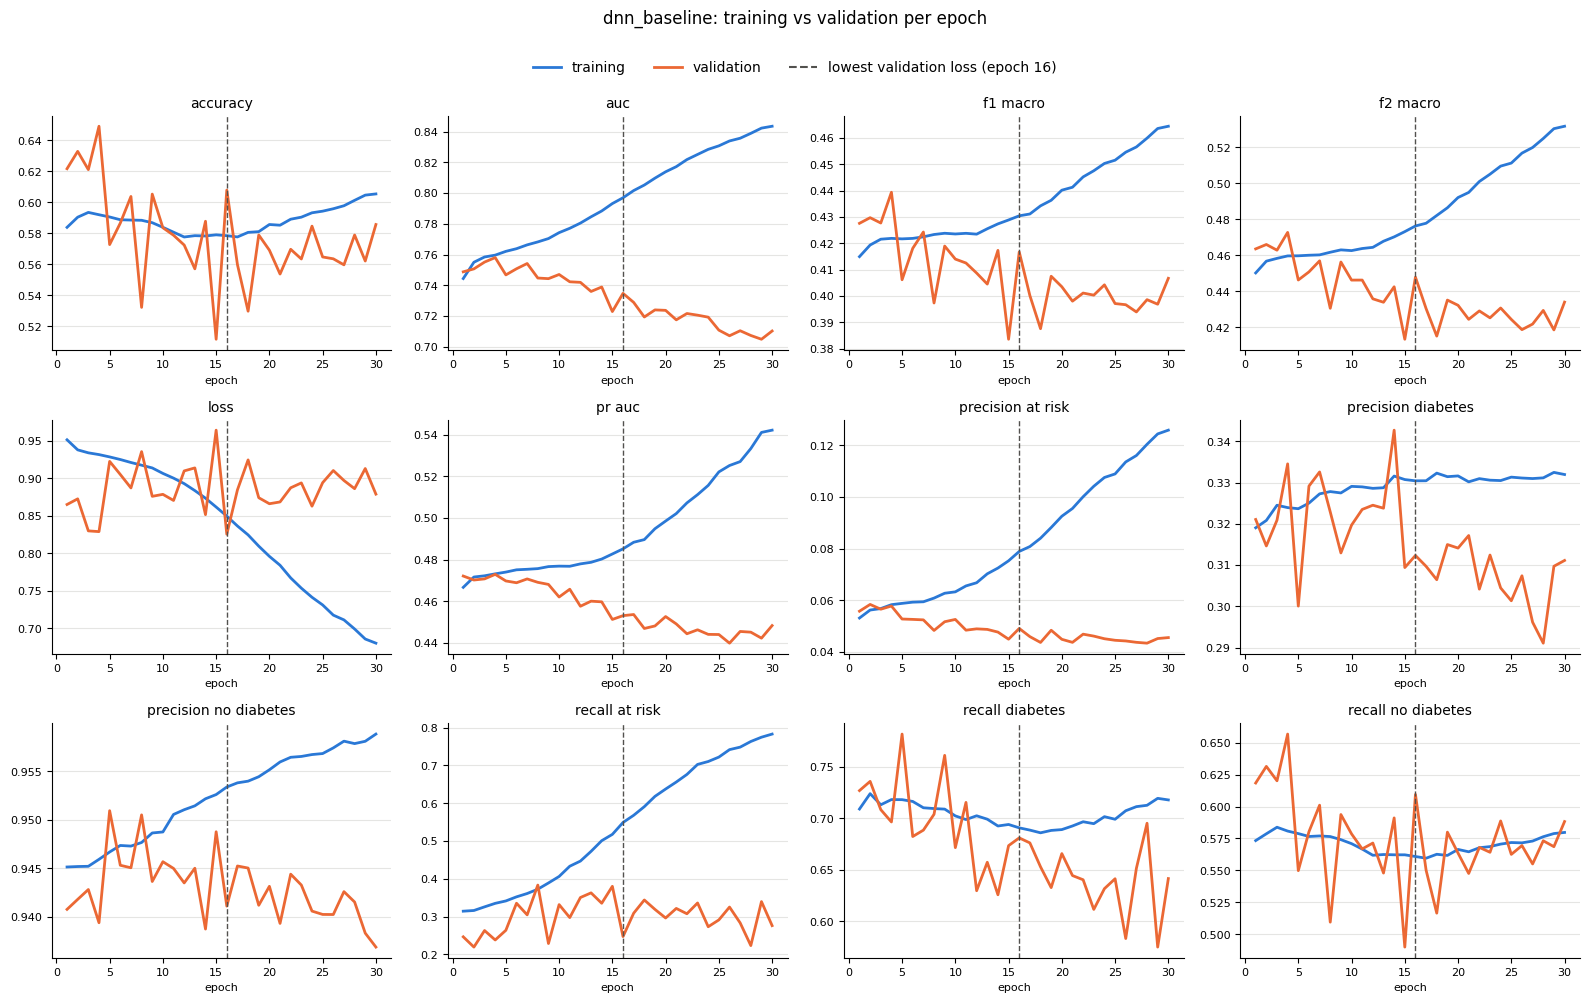

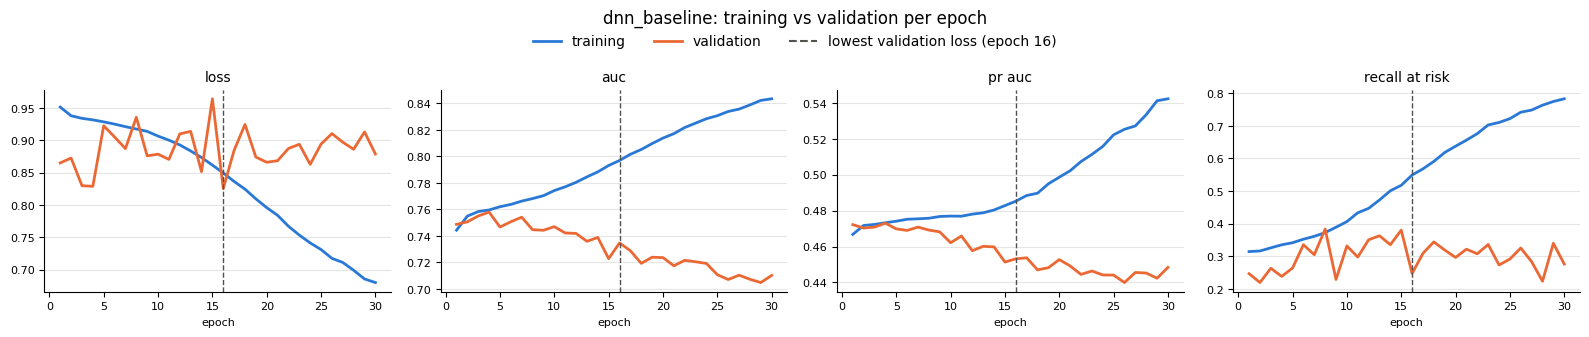

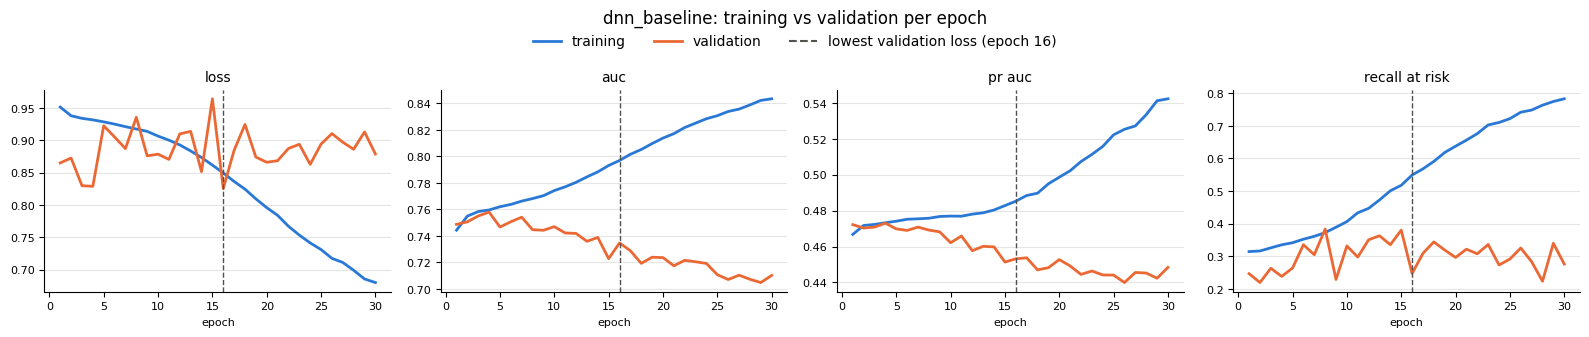

In [82]:
plot_training_curves(history.history, "dnn_baseline")
plot_training_curves(history.history, "dnn_baseline",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])


[baseline_neurone_network] SCREENING  sensitivity = 0.807 | precision = 0.287 | F2 = 0.592 | F1 = 0.423 | specificity = 0.588 | flagged = 47.9%
    flagged: diabetes = 0.842 | at risk = 0.655 | diabetics missed = 0.158
    OVERALL  ROC-AUC (OvR) = 0.7117 | macro F1 = 0.4067 | balanced acc = 0.5019 | accuracy = 0.5856
              precision    recall  f1-score   support

    diabetes      0.311     0.642     0.419     11957
 no diabetes      0.937     0.588     0.723     71742
     at risk      0.046     0.276     0.078      2769

    accuracy                          0.586     86468
   macro avg      0.431     0.502     0.407     86468
weighted avg      0.822     0.586     0.660     86468



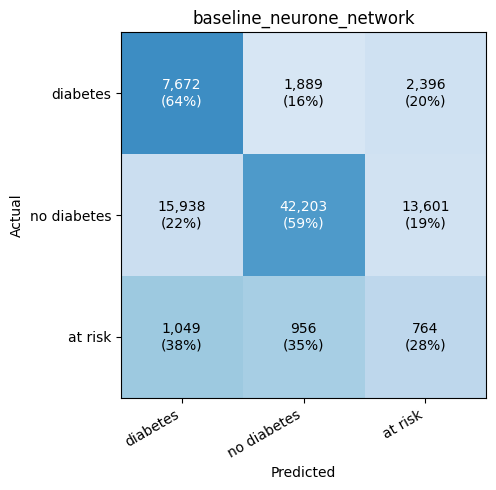

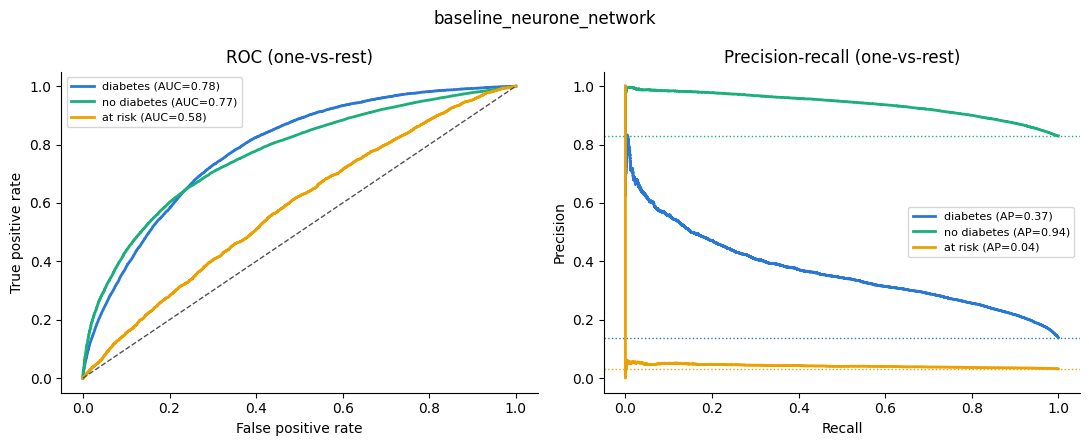

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [83]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.0,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced", "scheduler": "none"}

log_experiment("baseline_neurone_network", TrainedNetworkAdapter(model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

The previous run shows many signs of overfitting. The training metrics keep improving for all 30 epochs. For example, loss started at 0.95 and ended at 0.54, and AUC started at 0.75 and ended at 0.87, while the validation metrics peak at epoch 4, and then get worse- validation loss rises from 0.81 to 0.91, AUC falls from 0.757 to 0.704. The other sign can be seen between training recall on at risk (0.88), and validation recall at risk 0.1380 at epoch 30. The gap between them keeps widening. So the network is memorizing the training data instead of learning patterns that generalize.

## Add regularization:Dropout and L2

In [84]:
dropout_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())
dropout_history = train_network(dropout_model, run_name="dnn_dropout0.3", epochs=30)

Epoch 1/30
507/507 - 19s - 37ms/step - accuracy: 0.5769 - auc: 0.7169 - f1_macro: 0.4025 - f2_macro: 0.4349 - loss: 0.9831 - pr_auc: 0.4506 - precision_at_risk: 0.0461 - precision_diabetes: 0.3009 - precision_no_diabetes: 0.9399 - recall_at_risk: 0.2528 - recall_diabetes: 0.7014 - recall_no_diabetes: 0.5686 - val_accuracy: 0.6290 - val_auc: 0.7525 - val_f1_macro: 0.4269 - val_f2_macro: 0.4640 - val_loss: 0.8688 - val_pr_auc: 0.4722 - val_precision_at_risk: 0.0575 - val_precision_diabetes: 0.3097 - val_precision_no_diabetes: 0.9436 - val_recall_at_risk: 0.2019 - val_recall_diabetes: 0.7595 - val_recall_no_diabetes: 0.6238
Epoch 2/30
507/507 - 5s - 10ms/step - accuracy: 0.5871 - auc: 0.7406 - f1_macro: 0.4130 - f2_macro: 0.4501 - loss: 0.9591 - pr_auc: 0.4616 - precision_at_risk: 0.0528 - precision_diabetes: 0.3103 - precision_no_diabetes: 0.9427 - recall_at_risk: 0.2732 - recall_diabetes: 0.7385 - recall_no_diabetes: 0.5739 - val_accuracy: 0.5888 - val_auc: 0.7458 - val_f1_macro: 0.4130

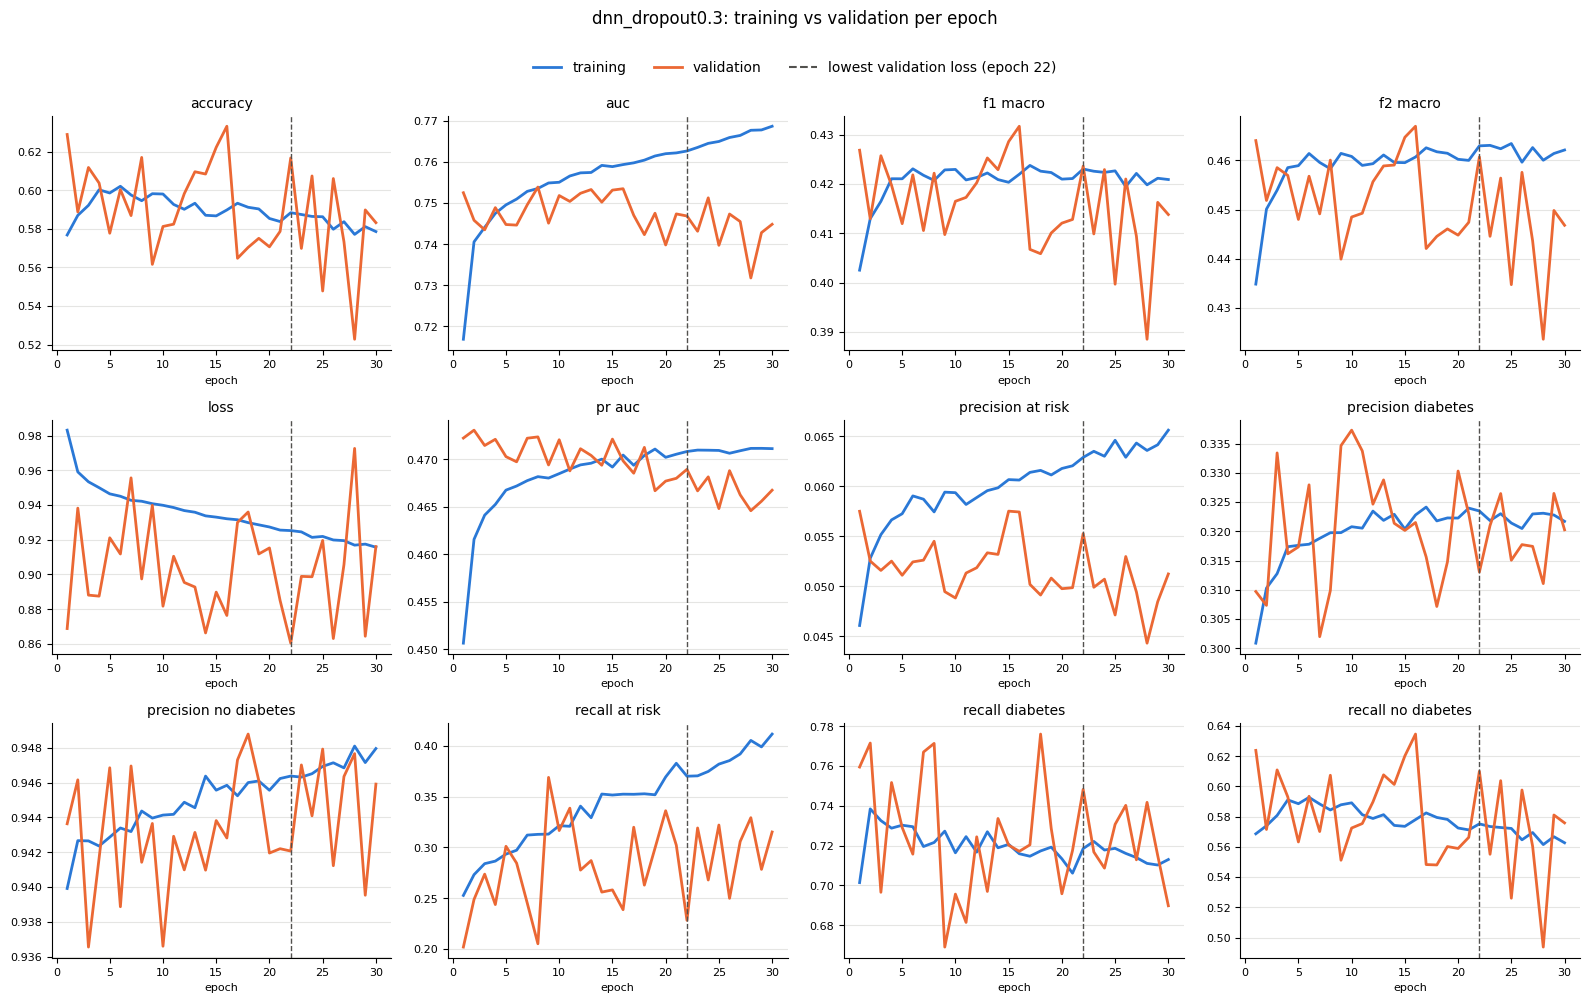

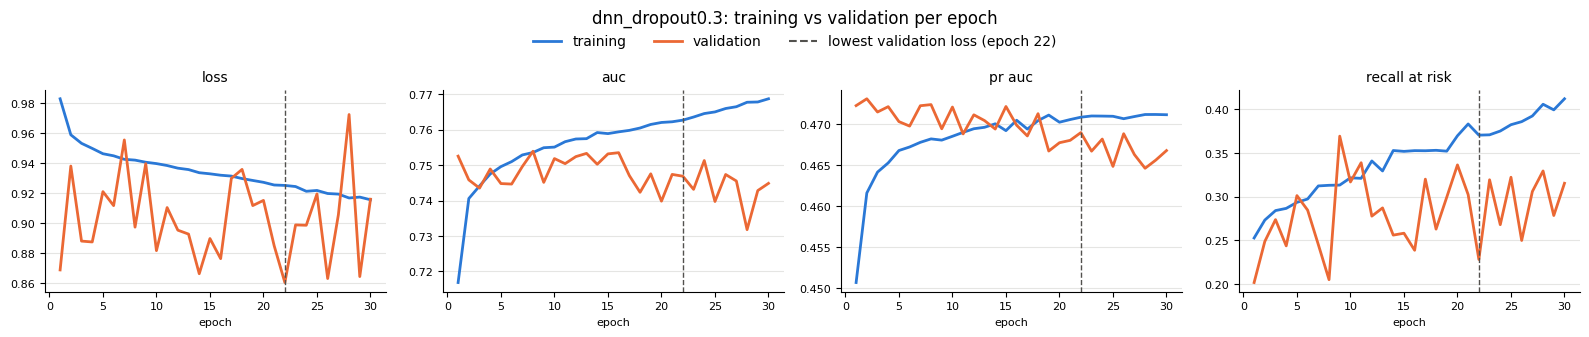

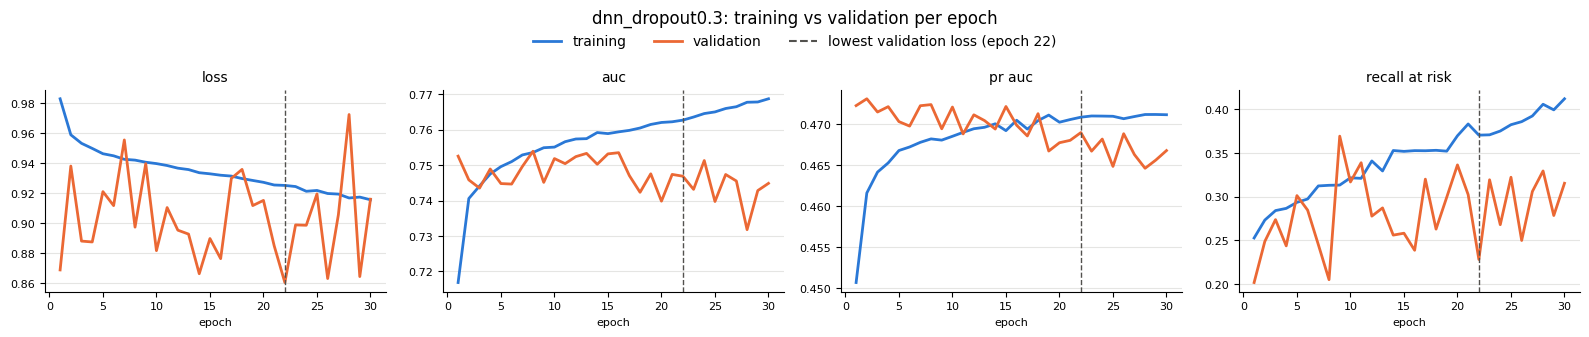

In [85]:
plot_training_curves(dropout_history.history, "dnn_dropout0.3")
plot_training_curves(dropout_history.history, "dnn_dropout0.3",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])


[dnn_dropout0.3] SCREENING  sensitivity = 0.840 | precision = 0.289 | F2 = 0.608 | F1 = 0.430 | specificity = 0.576 | flagged = 49.5%
    flagged: diabetes = 0.869 | at risk = 0.714 | diabetics missed = 0.131
    OVERALL  ROC-AUC (OvR) = 0.7449 | macro F1 = 0.4138 | balanced acc = 0.5270 | accuracy = 0.5833
              precision    recall  f1-score   support

    diabetes      0.320     0.690     0.437     11957
 no diabetes      0.946     0.576     0.716     71742
     at risk      0.051     0.315     0.088      2769

    accuracy                          0.583     86468
   macro avg      0.439     0.527     0.414     86468
weighted avg      0.831     0.583     0.657     86468



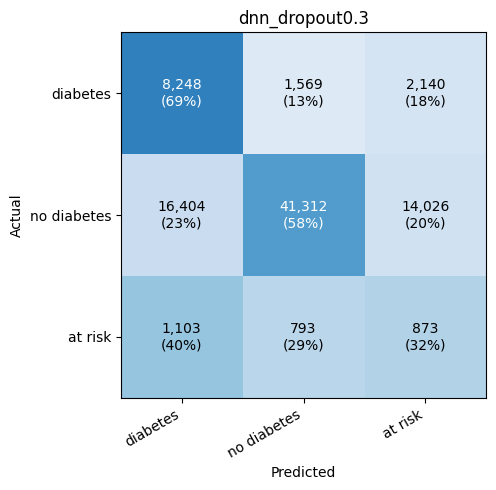

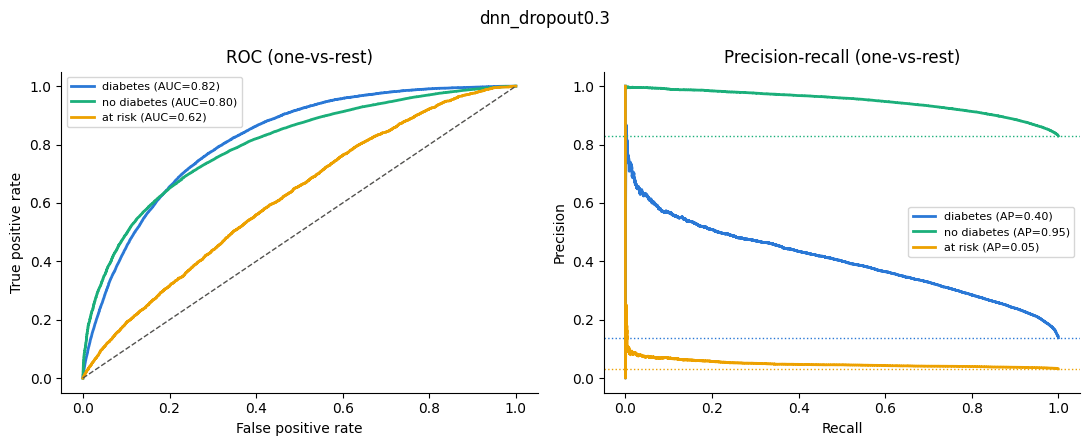

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [86]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced", "scheduler": "none"}

log_experiment("dnn_dropout0.3", TrainedNetworkAdapter(dropout_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

The dropout helped reduce some overfitting noticed in experiment 1. However,the loss on validation set shows various instabilities, suggesting that the same learning rate used from start to finish might be higher after a number of epoch. The next run will introduce ReduceLROnPlateau to halve the learning rate when the validation loss stops improving

In [87]:
dropout_scheduler_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
dropout_scheduler_history = train_network(dropout_scheduler_model, run_name="dnn_dropout0.3_reduce_lr",
                                          epochs=30, extra_callbacks=[reduce_learning_rate])

Epoch 1/30
507/507 - 19s - 37ms/step - accuracy: 0.5672 - auc: 0.7169 - f1_macro: 0.3995 - f2_macro: 0.4308 - loss: 0.9857 - pr_auc: 0.4500 - precision_at_risk: 0.0456 - precision_diabetes: 0.3019 - precision_no_diabetes: 0.9405 - recall_at_risk: 0.2737 - recall_diabetes: 0.6881 - recall_no_diabetes: 0.5583 - val_accuracy: 0.6043 - val_auc: 0.7475 - val_f1_macro: 0.4173 - val_f2_macro: 0.4551 - val_loss: 0.8972 - val_pr_auc: 0.4720 - val_precision_at_risk: 0.0510 - val_precision_diabetes: 0.3091 - val_precision_no_diabetes: 0.9466 - val_recall_at_risk: 0.2160 - val_recall_diabetes: 0.7742 - val_recall_no_diabetes: 0.5910 - learning_rate: 0.0010
Epoch 2/30
507/507 - 5s - 10ms/step - accuracy: 0.5821 - auc: 0.7399 - f1_macro: 0.4105 - f2_macro: 0.4477 - loss: 0.9592 - pr_auc: 0.4617 - precision_at_risk: 0.0531 - precision_diabetes: 0.3066 - precision_no_diabetes: 0.9447 - recall_at_risk: 0.2805 - recall_diabetes: 0.7356 - recall_no_diabetes: 0.5682 - val_accuracy: 0.6147 - val_auc: 0.745

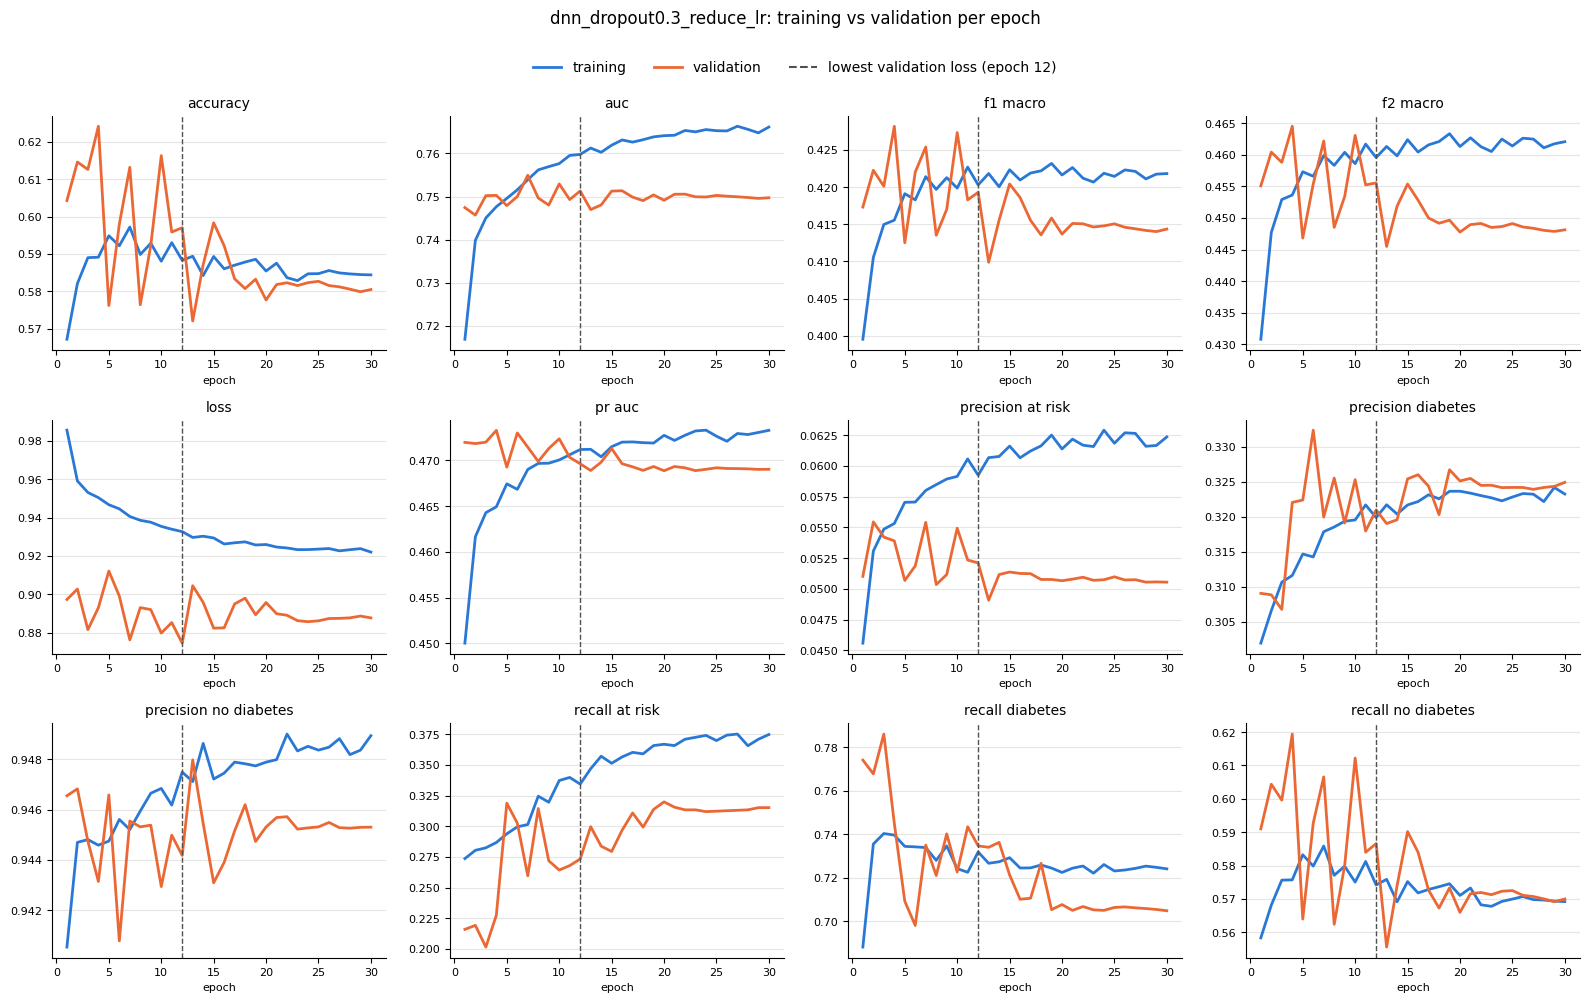

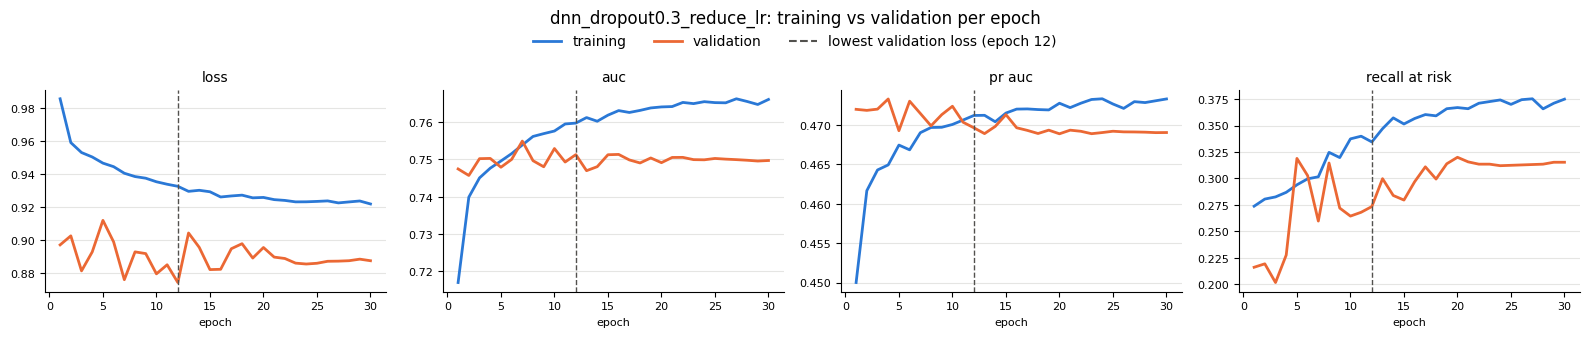

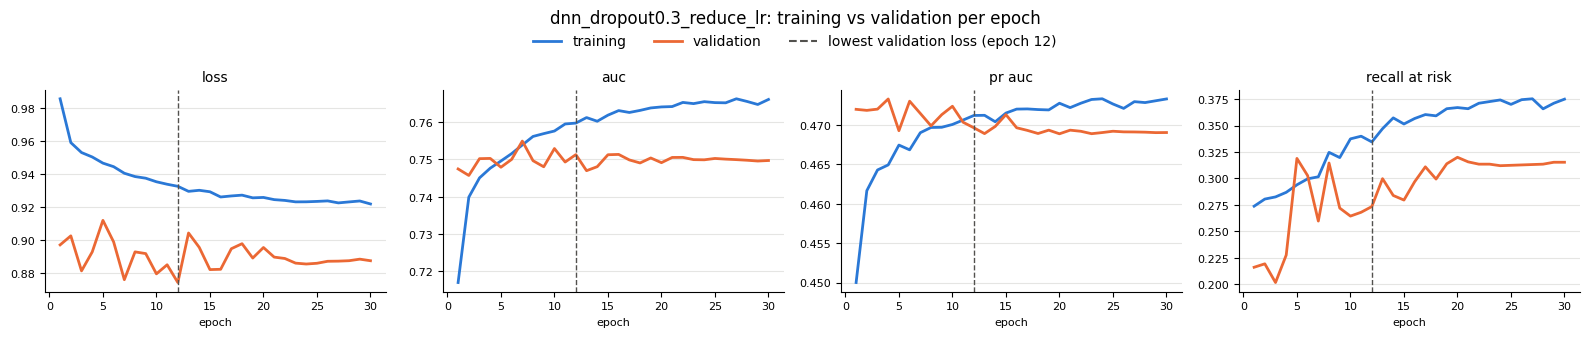

In [88]:
plot_training_curves(dropout_scheduler_history.history, "dnn_dropout0.3_reduce_lr")
plot_training_curves(dropout_scheduler_history.history, "dnn_dropout0.3_reduce_lr",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])


[dnn_dropout0.3_reduce_lr] SCREENING  sensitivity = 0.839 | precision = 0.286 | F2 = 0.605 | F1 = 0.427 | specificity = 0.570 | flagged = 50.0%
    flagged: diabetes = 0.867 | at risk = 0.720 | diabetics missed = 0.133
    OVERALL  ROC-AUC (OvR) = 0.7497 | macro F1 = 0.4144 | balanced acc = 0.5300 | accuracy = 0.5805
              precision    recall  f1-score   support

    diabetes      0.325     0.705     0.445     11957
 no diabetes      0.945     0.570     0.711     71742
     at risk      0.051     0.315     0.087      2769

    accuracy                          0.580     86468
   macro avg      0.440     0.530     0.414     86468
weighted avg      0.831     0.580     0.654     86468



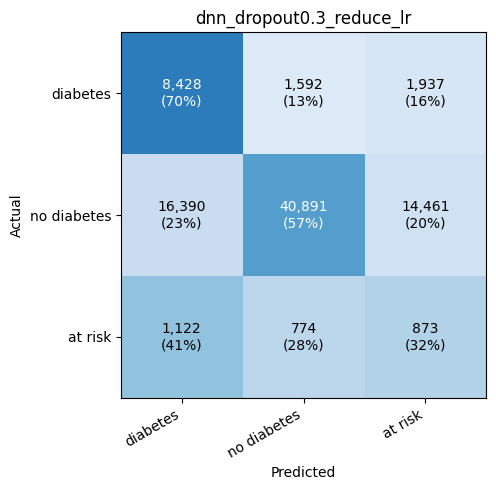

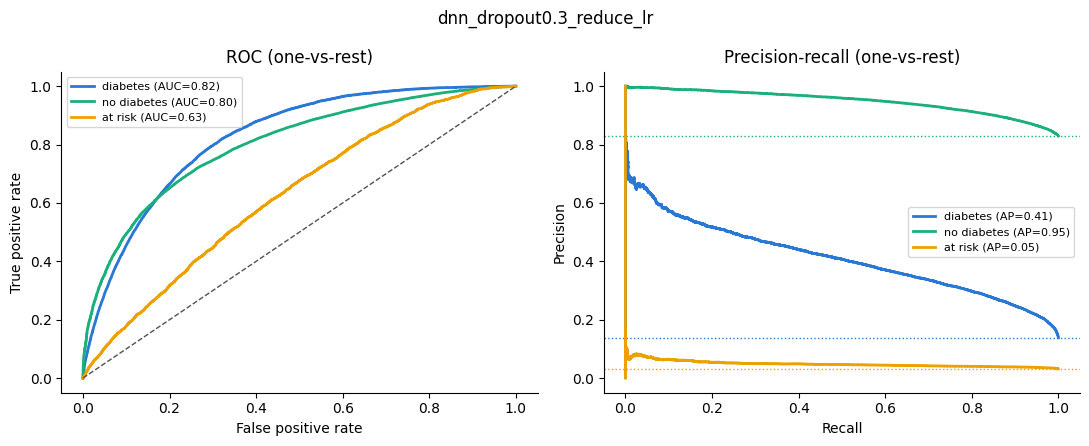

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [89]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)"}

log_experiment("dnn_dropout0.3_reduce_lr", TrainedNetworkAdapter(dropout_scheduler_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

In [90]:
dropout_scheduler_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_pr_auc",
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
dropout_scheduler_history = train_network(dropout_scheduler_model, run_name="dnn_dropout0.3_reduce_lr_val_pr_auc",
                                          epochs=30, extra_callbacks=[reduce_learning_rate])


Epoch 1/30
507/507 - 19s - 38ms/step - accuracy: 0.5511 - auc: 0.7126 - f1_macro: 0.3919 - f2_macro: 0.4224 - loss: 0.9857 - pr_auc: 0.4477 - precision_at_risk: 0.0435 - precision_diabetes: 0.2983 - precision_no_diabetes: 0.9387 - recall_at_risk: 0.2805 - recall_diabetes: 0.6835 - recall_no_diabetes: 0.5394 - val_accuracy: 0.6376 - val_auc: 0.7576 - val_f1_macro: 0.4319 - val_f2_macro: 0.4678 - val_loss: 0.8506 - val_pr_auc: 0.4712 - val_precision_at_risk: 0.0573 - val_precision_diabetes: 0.3192 - val_precision_no_diabetes: 0.9410 - val_recall_at_risk: 0.2127 - val_recall_diabetes: 0.7364 - val_recall_no_diabetes: 0.6376 - learning_rate: 0.0010
Epoch 2/30
507/507 - 5s - 9ms/step - accuracy: 0.5799 - auc: 0.7408 - f1_macro: 0.4112 - f2_macro: 0.4475 - loss: 0.9577 - pr_auc: 0.4617 - precision_at_risk: 0.0527 - precision_diabetes: 0.3118 - precision_no_diabetes: 0.9439 - recall_at_risk: 0.2977 - recall_diabetes: 0.7228 - recall_no_diabetes: 0.5670 - val_accuracy: 0.5827 - val_auc: 0.7455

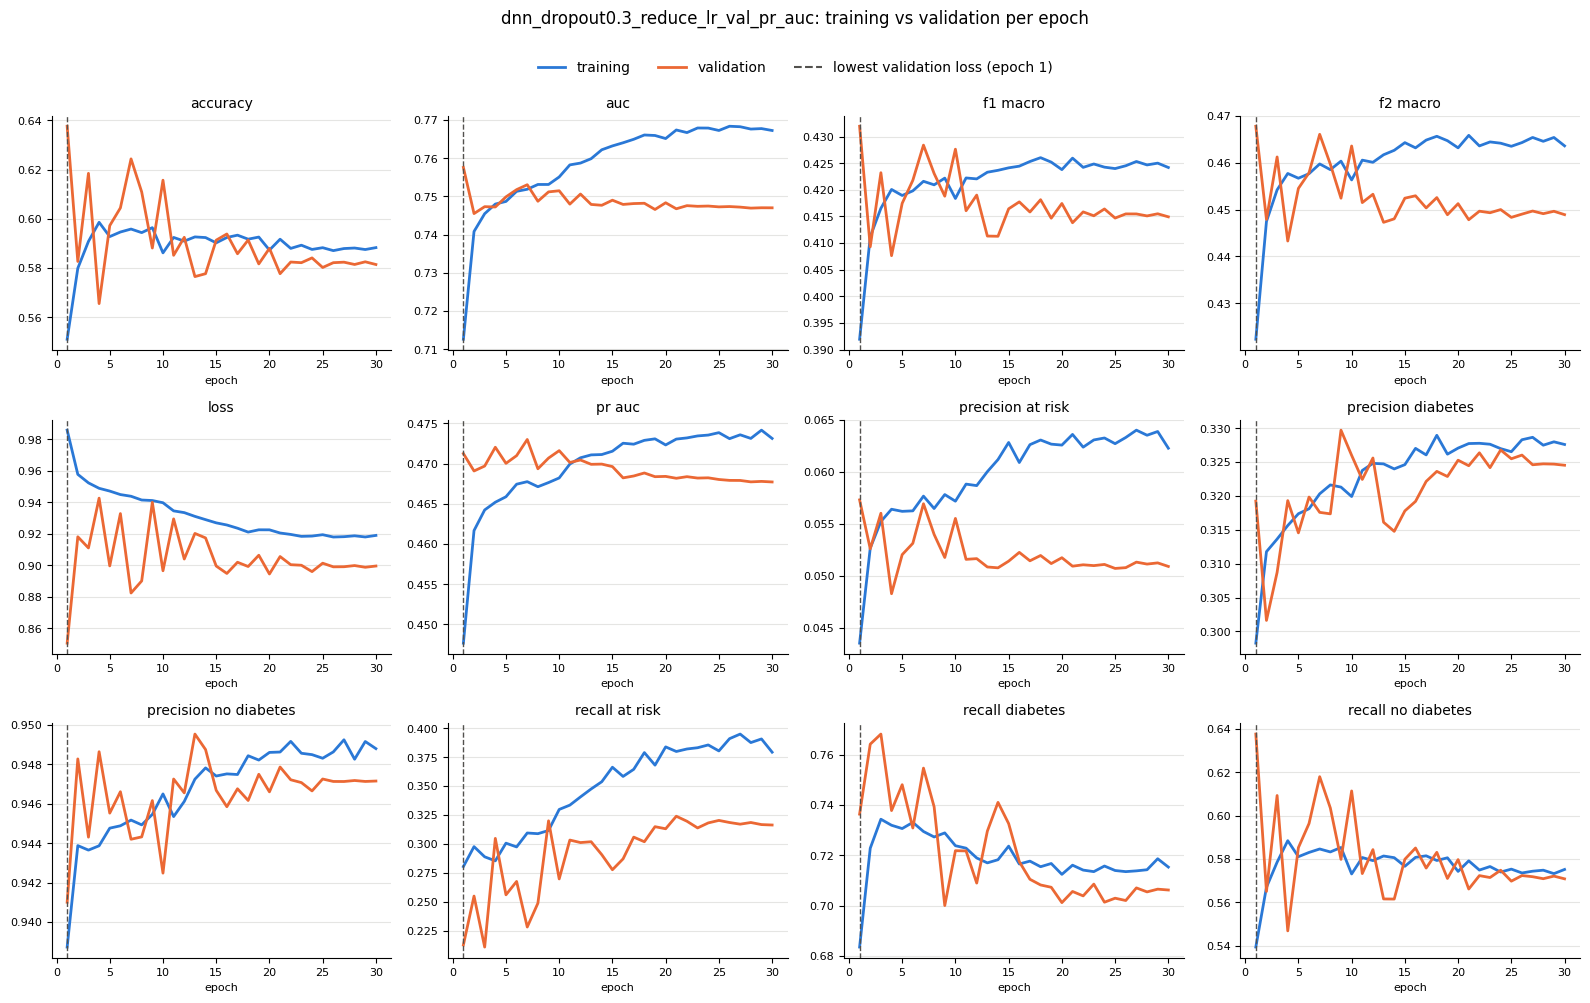

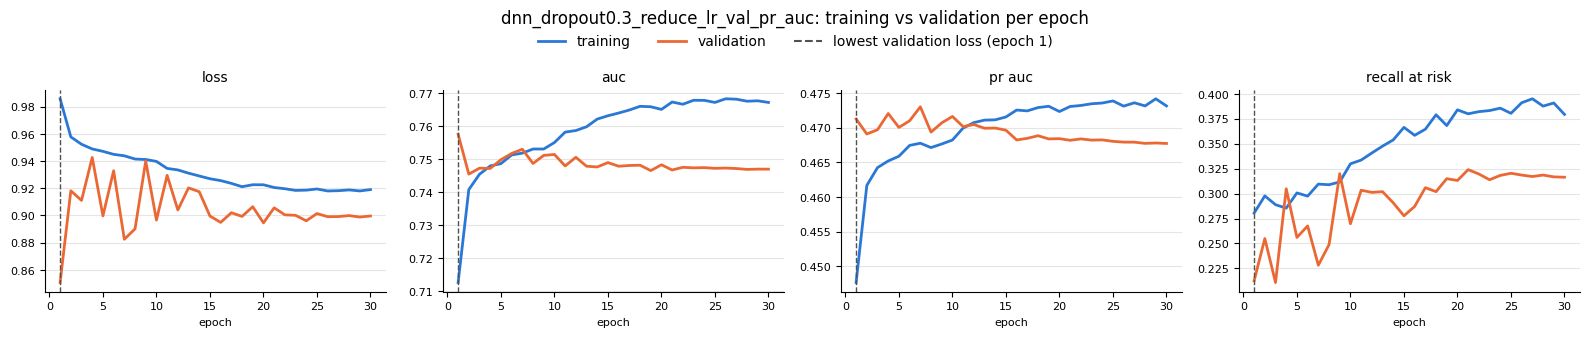

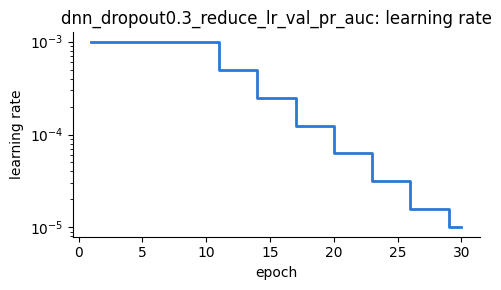

In [91]:
pr_auc_scheduler_history = dropout_scheduler_history   # the val_pr_auc run was stored under this name

plot_training_curves(pr_auc_scheduler_history.history, "dnn_dropout0.3_reduce_lr_val_pr_auc")
plot_training_curves(pr_auc_scheduler_history.history, "dnn_dropout0.3_reduce_lr_val_pr_auc",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

learning_rate_values = pr_auc_scheduler_history.history["learning_rate"]
learning_rate_figure, learning_rate_axis = plt.subplots(figsize=(5, 3))
learning_rate_axis.plot(range(1, len(learning_rate_values) + 1), learning_rate_values,
                        color="#2a78d6", linewidth=2, drawstyle="steps-post")
learning_rate_axis.set(xlabel="epoch", ylabel="learning rate",
                       title="dnn_dropout0.3_reduce_lr_val_pr_auc: learning rate")
learning_rate_axis.set_yscale("log")
for side in ["top", "right"]:
    learning_rate_axis.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


[dnn_dropout0.3_reduce_lr_val_pr_auc] SCREENING  sensitivity = 0.845 | precision = 0.288 | F2 = 0.609 | F1 = 0.429 | specificity = 0.571 | flagged = 50.0%
    flagged: diabetes = 0.874 | at risk = 0.717 | diabetics missed = 0.126
    OVERALL  ROC-AUC (OvR) = 0.7471 | macro F1 = 0.4149 | balanced acc = 0.5311 | accuracy = 0.5814
              precision    recall  f1-score   support

    diabetes      0.325     0.706     0.445     11957
 no diabetes      0.947     0.571     0.712     71742
     at risk      0.051     0.316     0.088      2769

    accuracy                          0.581     86468
   macro avg      0.441     0.531     0.415     86468
weighted avg      0.832     0.581     0.655     86468



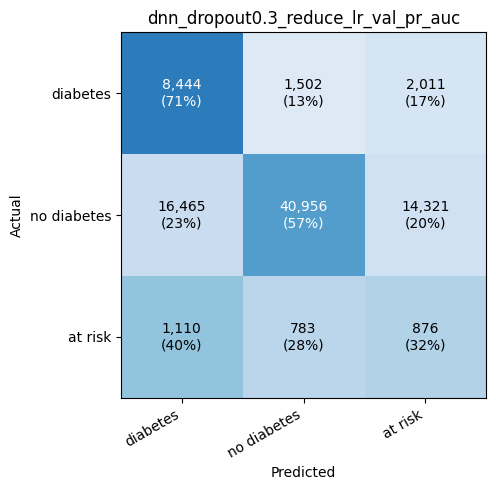

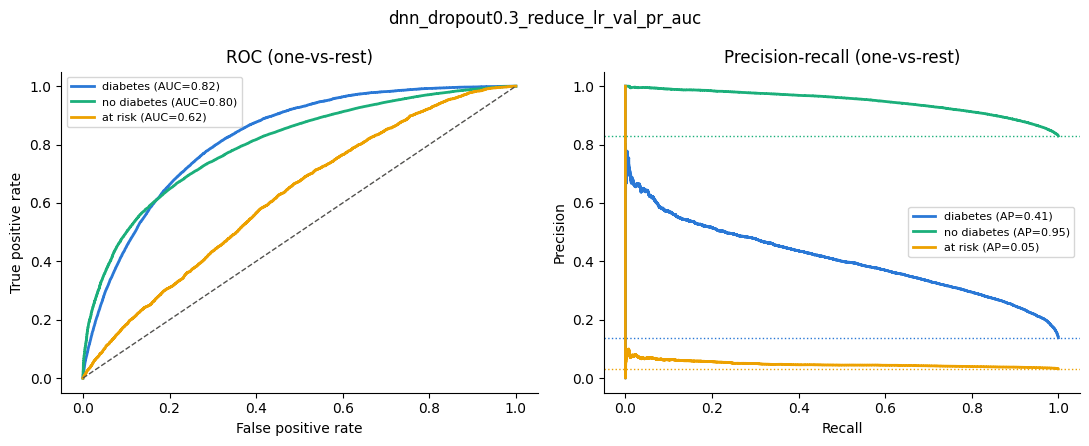

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [92]:
# Same metrics, plots, TensorBoard logging and results-table row as the classical models
dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "epochs": 30, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_pr_auc, max, factor 0.5, patience 3, min_lr 1e-5)"}

log_experiment("dnn_dropout0.3_reduce_lr_val_pr_auc", TrainedNetworkAdapter(dropout_scheduler_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)

Add Early stopping on the best performing NN model so far

In [93]:
early_stopping_model = compiled_network(network_model=build_network(dropout_rate=0.3), metrics=keras_metrics())

reduce_learning_rate = ReduceLROnPlateau(          # same scheduler as dnn_dropout0.3_reduce_lr
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(                    # the only change
    monitor="val_pr_auc",
    mode="max",
    patience=10,                                    # more patient than the scheduler (3)
    restore_best_weights=True,
    verbose=1,
)
early_stopping_history = train_network(early_stopping_model, run_name="dnn_dropout0.3_reduce_lr_early_stopping",
                                       epochs=60, extra_callbacks=[reduce_learning_rate, early_stopping])


Epoch 1/60
507/507 - 19s - 38ms/step - accuracy: 0.5672 - auc: 0.7165 - f1_macro: 0.3990 - f2_macro: 0.4307 - loss: 0.9852 - pr_auc: 0.4480 - precision_at_risk: 0.0456 - precision_diabetes: 0.3004 - precision_no_diabetes: 0.9391 - recall_at_risk: 0.2673 - recall_diabetes: 0.6939 - recall_no_diabetes: 0.5576 - val_accuracy: 0.5569 - val_auc: 0.7435 - val_f1_macro: 0.3987 - val_f2_macro: 0.4381 - val_loss: 0.9604 - val_pr_auc: 0.4667 - val_precision_at_risk: 0.0486 - val_precision_diabetes: 0.2984 - val_precision_no_diabetes: 0.9530 - val_recall_at_risk: 0.2640 - val_recall_diabetes: 0.7871 - val_recall_no_diabetes: 0.5299 - learning_rate: 0.0010
Epoch 2/60
507/507 - 5s - 10ms/step - accuracy: 0.5837 - auc: 0.7403 - f1_macro: 0.4116 - f2_macro: 0.4478 - loss: 0.9585 - pr_auc: 0.4609 - precision_at_risk: 0.0522 - precision_diabetes: 0.3101 - precision_no_diabetes: 0.9440 - recall_at_risk: 0.2831 - recall_diabetes: 0.7268 - recall_no_diabetes: 0.5715 - val_accuracy: 0.5575 - val_auc: 0.741

stopped after 19 epochs | restored epoch 9
[dnn_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.822 | precision = 0.286 | F2 = 0.598 | F1 = 0.424 | specificity = 0.578 | flagged = 49.0%
    flagged: diabetes = 0.847 | at risk = 0.716 | diabetics missed = 0.153
    OVERALL  ROC-AUC (OvR) = 0.7496 | macro F1 = 0.4176 | balanced acc = 0.5317 | accuracy = 0.5896
              precision    recall  f1-score   support

    diabetes      0.325     0.727     0.449     11957
 no diabetes      0.941     0.578     0.716     71742
     at risk      0.051     0.290     0.087      2769

    accuracy                          0.590     86468
   macro avg      0.439     0.532     0.418     86468
weighted avg      0.827     0.590     0.659     86468



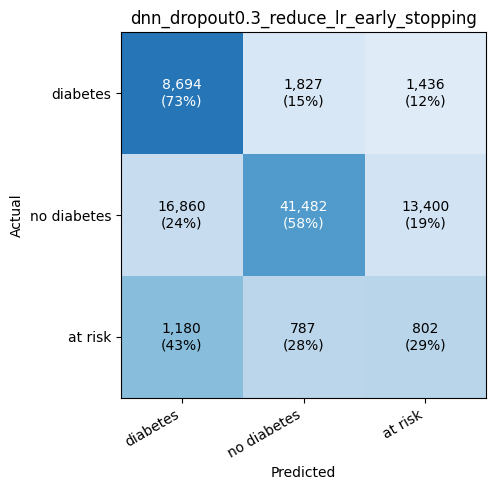

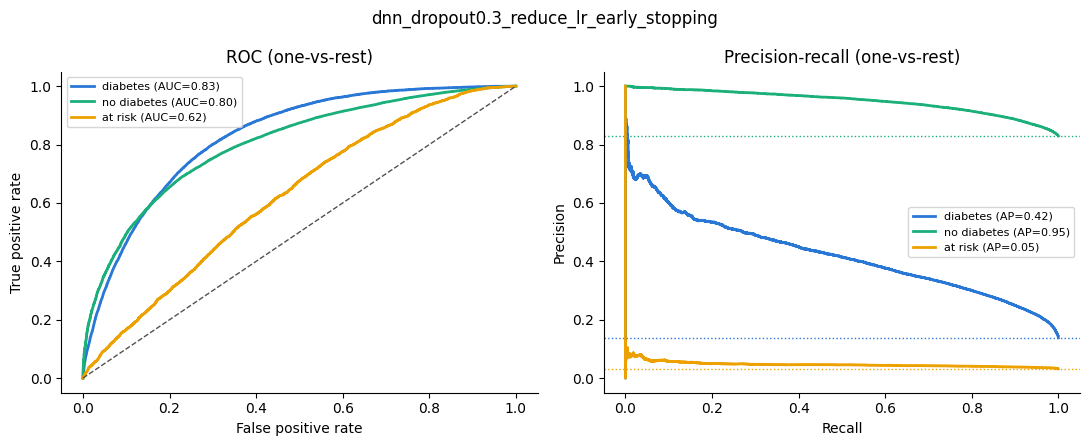

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [94]:
best_epoch = int(np.argmax(early_stopping_history.history["val_pr_auc"])) + 1
print("stopped after", len(early_stopping_history.history["loss"]), "epochs | restored epoch", best_epoch)

dnn_config = {"model": "Keras MLP", "hidden_units": "256-128-64-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 7, restore best weights"}
log_experiment("dnn_dropout0.3_reduce_lr_early_stopping", TrainedNetworkAdapter(early_stopping_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [95]:
small_combined_model = compiled_network(
    network_model=build_network(hidden_units=(64, 32), dropout_rate=0.3),
    metrics=keras_metrics(),
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)
small_combined_history = train_network(small_combined_model, run_name="dnn_64_32_dropout0.3_reduce_lr_early_stopping",
                                       epochs=50, extra_callbacks=[reduce_learning_rate, early_stopping])

best_epoch = int(np.argmax(small_combined_history.history["val_pr_auc"])) + 1
print("stopped after", len(small_combined_history.history["loss"]), "epochs | restored epoch", best_epoch)


Epoch 1/50
507/507 - 17s - 34ms/step - accuracy: 0.5622 - auc: 0.7067 - f1_macro: 0.3936 - f2_macro: 0.4234 - loss: 0.9945 - pr_auc: 0.4422 - precision_at_risk: 0.0446 - precision_diabetes: 0.2932 - precision_no_diabetes: 0.9342 - recall_at_risk: 0.2664 - recall_diabetes: 0.6670 - recall_no_diabetes: 0.5562 - val_accuracy: 0.5769 - val_auc: 0.7420 - val_f1_macro: 0.4083 - val_f2_macro: 0.4460 - val_loss: 0.9417 - val_pr_auc: 0.4663 - val_precision_at_risk: 0.0501 - val_precision_diabetes: 0.3066 - val_precision_no_diabetes: 0.9512 - val_recall_at_risk: 0.2662 - val_recall_diabetes: 0.7597 - val_recall_no_diabetes: 0.5584 - learning_rate: 0.0010
Epoch 2/50
507/507 - 5s - 10ms/step - accuracy: 0.5794 - auc: 0.7366 - f1_macro: 0.4102 - f2_macro: 0.4450 - loss: 0.9623 - pr_auc: 0.4593 - precision_at_risk: 0.0507 - precision_diabetes: 0.3126 - precision_no_diabetes: 0.9444 - recall_at_risk: 0.2930 - recall_diabetes: 0.7137 - recall_no_diabetes: 0.5680 - val_accuracy: 0.5913 - val_auc: 0.746

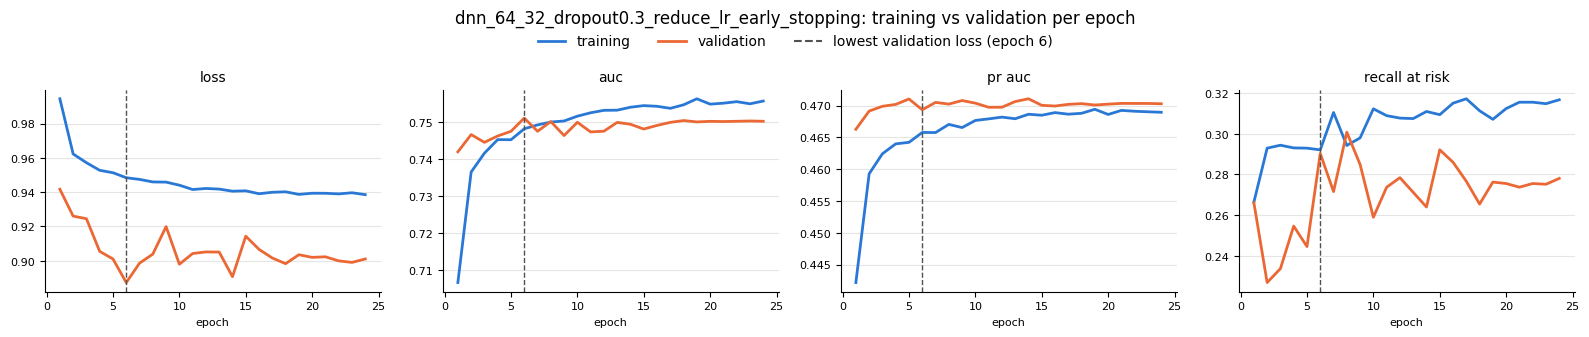

[dnn_64_32_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.828 | precision = 0.294 | F2 = 0.607 | F1 = 0.434 | specificity = 0.592 | flagged = 47.9%
    flagged: diabetes = 0.857 | at risk = 0.700 | diabetics missed = 0.143
    OVERALL  ROC-AUC (OvR) = 0.7495 | macro F1 = 0.4204 | balanced acc = 0.5315 | accuracy = 0.6018
              precision    recall  f1-score   support

    diabetes      0.318     0.738     0.445     11957
 no diabetes      0.944     0.592     0.728     71742
     at risk      0.053     0.264     0.089      2769

    accuracy                          0.602     86468
   macro avg      0.438     0.531     0.420     86468
weighted avg      0.829     0.602     0.668     86468



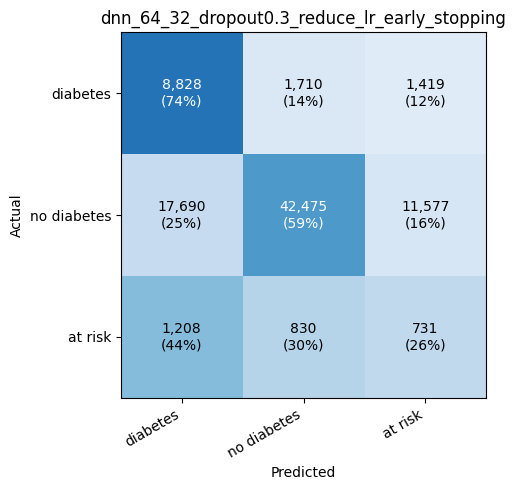

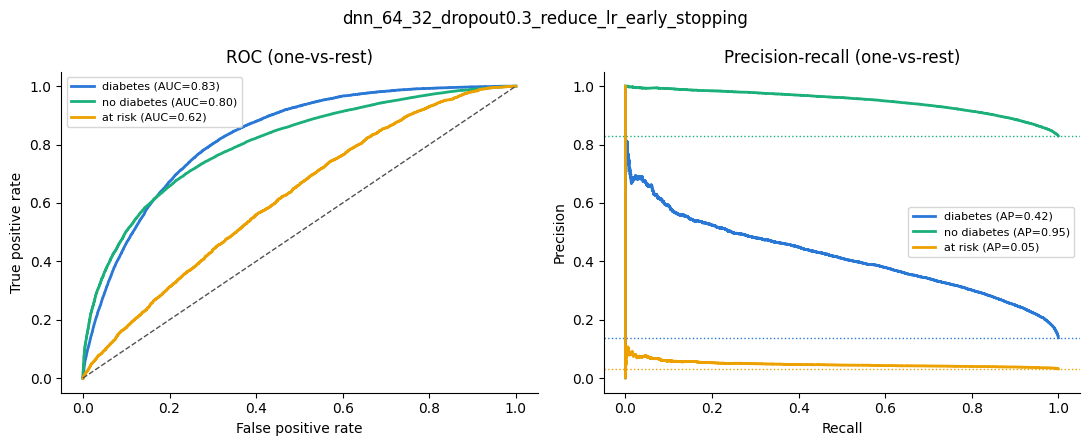

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [96]:
plot_training_curves(small_combined_history.history, "dnn_64_32_dropout0.3_reduce_lr_early_stopping",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

dnn_config = {"model": "Keras MLP", "hidden_units": "64-32", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 10, restore best weights"}
log_experiment("dnn_64_32_dropout0.3_reduce_lr_early_stopping", TrainedNetworkAdapter(small_combined_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [97]:
doubled_combined_model = compiled_network(
    network_model=build_network(hidden_units=(128, 64), dropout_rate=0.3),
    metrics=keras_metrics(),
)

reduce_learning_rate = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1,
)
early_stopping = EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1,
)
doubled_combined_history = train_network(doubled_combined_model, run_name="dnn_64_32_dropout0.3_reduce_lr_early_stopping",
                                       epochs=50, extra_callbacks=[reduce_learning_rate, early_stopping])

best_epoch = int(np.argmax(doubled_combined_history.history["val_pr_auc"])) + 1
print("stopped after", len(doubled_combined_history.history["loss"]), "epochs | restored epoch", best_epoch)


Epoch 1/50
507/507 - 16s - 32ms/step - accuracy: 0.5706 - auc: 0.7205 - f1_macro: 0.4024 - f2_macro: 0.4321 - loss: 0.9818 - pr_auc: 0.4482 - precision_at_risk: 0.0476 - precision_diabetes: 0.3069 - precision_no_diabetes: 0.9383 - recall_at_risk: 0.3018 - recall_diabetes: 0.6572 - recall_no_diabetes: 0.5666 - val_accuracy: 0.5748 - val_auc: 0.7517 - val_f1_macro: 0.4161 - val_f2_macro: 0.4387 - val_loss: 0.9035 - val_pr_auc: 0.4699 - val_precision_at_risk: 0.0501 - val_precision_diabetes: 0.3516 - val_precision_no_diabetes: 0.9455 - val_recall_at_risk: 0.4052 - val_recall_diabetes: 0.5932 - val_recall_no_diabetes: 0.5783 - learning_rate: 0.0010
Epoch 2/50
507/507 - 5s - 9ms/step - accuracy: 0.5750 - auc: 0.7434 - f1_macro: 0.4108 - f2_macro: 0.4452 - loss: 0.9537 - pr_auc: 0.4634 - precision_at_risk: 0.0519 - precision_diabetes: 0.3173 - precision_no_diabetes: 0.9448 - recall_at_risk: 0.3238 - recall_diabetes: 0.7004 - recall_no_diabetes: 0.5638 - val_accuracy: 0.5855 - val_auc: 0.7459

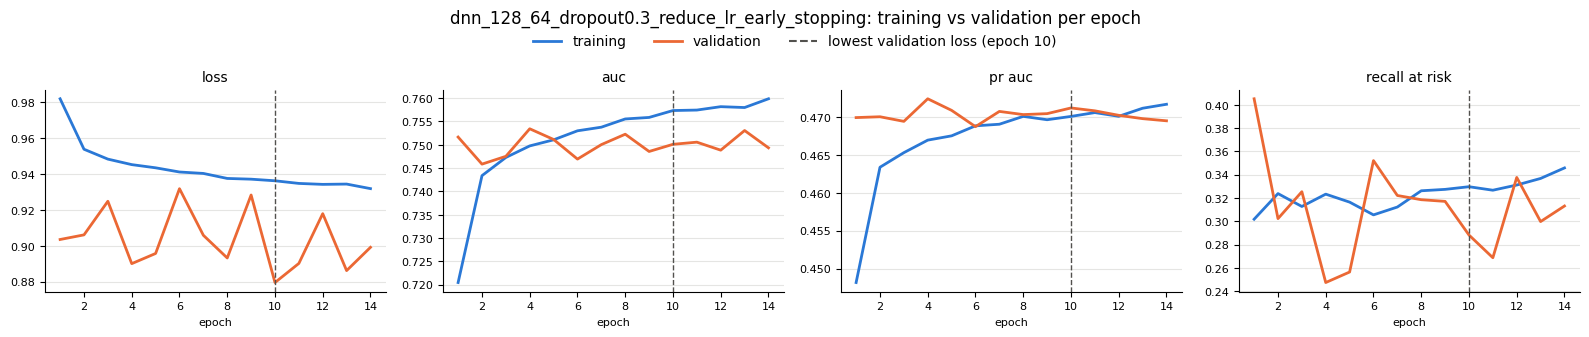

[dnn_128_64_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.830 | precision = 0.299 | F2 = 0.612 | F1 = 0.439 | specificity = 0.600 | flagged = 47.3%
    flagged: diabetes = 0.861 | at risk = 0.694 | diabetics missed = 0.139
    OVERALL  ROC-AUC (OvR) = 0.7534 | macro F1 = 0.4227 | balanced acc = 0.5324 | accuracy = 0.6095
              precision    recall  f1-score   support

    diabetes      0.316     0.750     0.445     11957
 no diabetes      0.945     0.600     0.734     71742
     at risk      0.055     0.247     0.089      2769

    accuracy                          0.609     86468
   macro avg      0.439     0.532     0.423     86468
weighted avg      0.829     0.609     0.673     86468



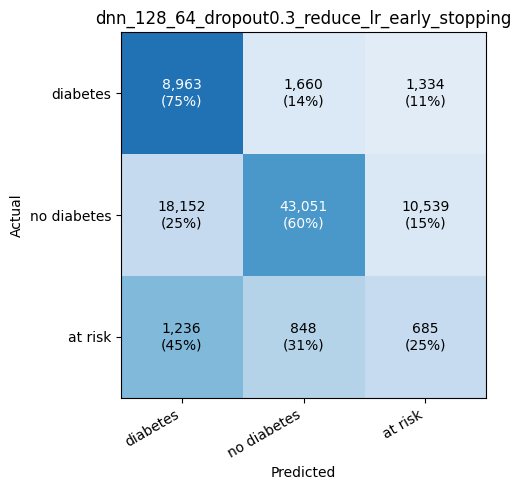

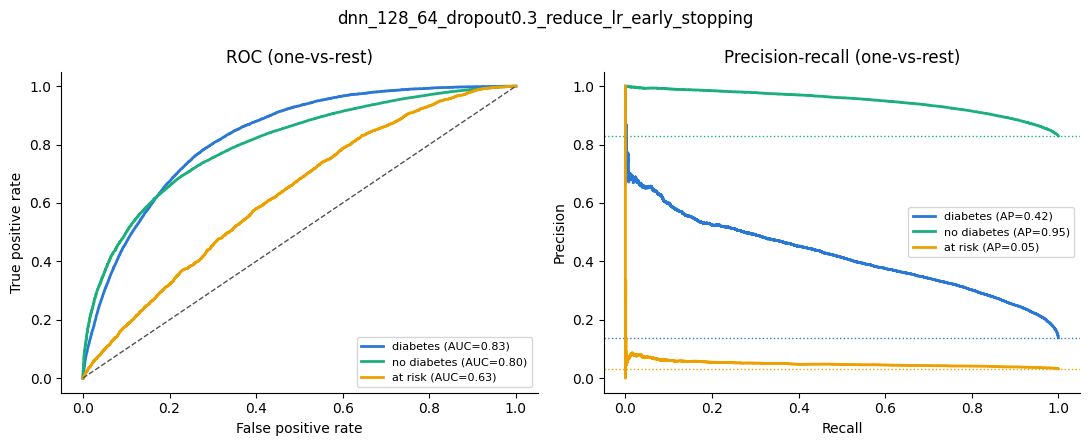

TrainedNetworkAdapter(network=<Functional name=tabular_net, built=True>)

In [98]:
plot_training_curves(doubled_combined_history.history, "dnn_128_64_dropout0.3_reduce_lr_early_stopping",
                     metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

dnn_config = {"model": "Keras MLP", "hidden_units": "128-64", "dropout_rate": 0.3,
              "learning_rate": 1e-3, "max_epochs": 50, "class_weight": "balanced",
              "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
              "early_stopping": "val_pr_auc, max, patience 10, restore best weights"}
log_experiment("dnn_128_64_dropout0.3_reduce_lr_early_stopping", TrainedNetworkAdapter(doubled_combined_model), dnn_config,
               X_train, Y_train, X_val, Y_val, do_cv=False)


In [100]:
def run_network_experiment(hidden_units, dropout_rate=0.3, learning_rate=1e-3, max_epochs=50):
    """Builds, trains, plots and evaluates one network with the best setup so far:
    dropout + ReduceLROnPlateau(val_loss) + EarlyStopping(val_pr_auc, restore best weights)."""
    size_label = "_".join(str(layer_width) for layer_width in hidden_units)
    run_name = f"dnn_{size_label}_dropout{dropout_rate}_reduce_lr_early_stopping"

    network = compiled_network(
        network_model=build_network(hidden_units=hidden_units, dropout_rate=dropout_rate,
                                    learning_rate=learning_rate),
        metrics=keras_metrics(),
    )
    # fresh callbacks for every run (they keep internal state)
    reduce_learning_rate = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                             min_lr=1e-5, verbose=1)
    early_stopping = EarlyStopping(monitor="val_pr_auc", mode="max", patience=10,
                                   restore_best_weights=True, verbose=1)

    training_history = train_network(network, run_name=run_name, epochs=max_epochs,
                                     extra_callbacks=[reduce_learning_rate, early_stopping])
    restored_epoch = int(np.argmax(training_history.history["val_pr_auc"])) + 1
    epochs_run = len(training_history.history["loss"])
    print(f"{run_name}: stopped after {epochs_run} epochs | restored epoch {restored_epoch}")

    plot_training_curves(training_history.history, run_name,
                         metric_names=["loss", "auc", "pr_auc", "recall_at_risk"])

    network_config = {"model": "Keras MLP", "hidden_units": "-".join(str(layer_width) for layer_width in hidden_units),
                      "dropout_rate": dropout_rate, "learning_rate": learning_rate, "max_epochs": max_epochs,
                      "epochs_run": epochs_run, "restored_epoch": restored_epoch,
                      "class_weight": "balanced", "loss": "categorical cross-entropy",
                      "scheduler": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-5)",
                      "early_stopping": "val_pr_auc, max, patience 10, restore best weights"}
    log_experiment(run_name, TrainedNetworkAdapter(network), network_config,
                   X_train, Y_train, X_val, Y_val, do_cv=False)
    return network, training_history


ERROR! Session/line number was not unique in database. History logging moved to new session 30


Epoch 1/50
507/507 - 17s - 33ms/step - accuracy: 0.5273 - auc: 0.6978 - f1_macro: 0.3793 - f2_macro: 0.4047 - loss: 1.0058 - pr_auc: 0.4379 - precision_at_risk: 0.0409 - precision_diabetes: 0.2920 - precision_no_diabetes: 0.9325 - recall_at_risk: 0.3065 - recall_diabetes: 0.6297 - recall_no_diabetes: 0.5188 - val_accuracy: 0.5821 - val_auc: 0.7378 - val_f1_macro: 0.4122 - val_f2_macro: 0.4482 - val_loss: 0.9391 - val_pr_auc: 0.4684 - val_precision_at_risk: 0.0492 - val_precision_diabetes: 0.3155 - val_precision_no_diabetes: 0.9501 - val_recall_at_risk: 0.2759 - val_recall_diabetes: 0.7417 - val_recall_no_diabetes: 0.5674 - learning_rate: 0.0010
Epoch 2/50
507/507 - 5s - 10ms/step - accuracy: 0.5777 - auc: 0.7288 - f1_macro: 0.4075 - f2_macro: 0.4419 - loss: 0.9707 - pr_auc: 0.4556 - precision_at_risk: 0.0501 - precision_diabetes: 0.3078 - precision_no_diabetes: 0.9425 - recall_at_risk: 0.2843 - recall_diabetes: 0.7099 - recall_no_diabetes: 0.5670 - val_accuracy: 0.5863 - val_auc: 0.749

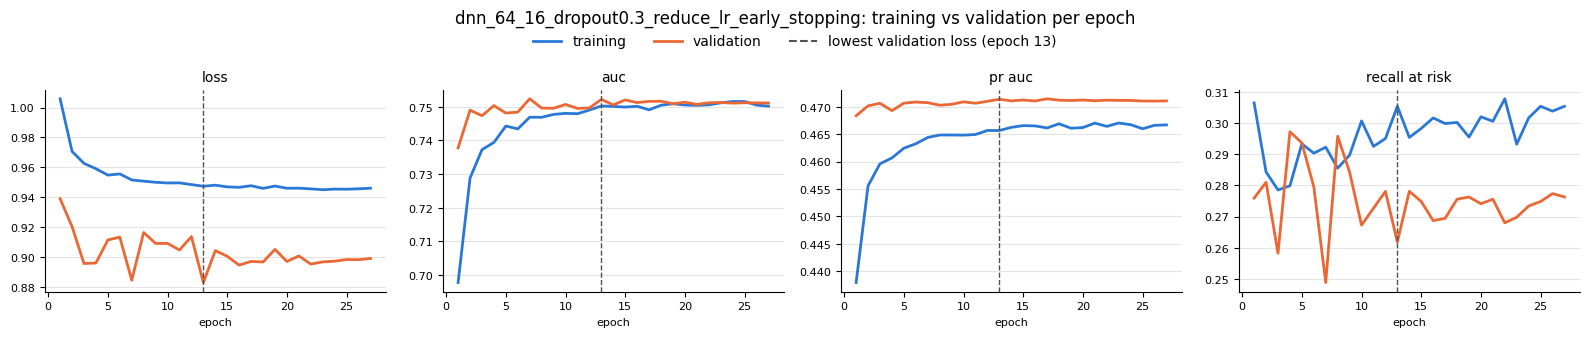

[dnn_64_16_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.835 | precision = 0.294 | F2 = 0.611 | F1 = 0.435 | specificity = 0.589 | flagged = 48.3%
    flagged: diabetes = 0.866 | at risk = 0.705 | diabetics missed = 0.134
    OVERALL  ROC-AUC (OvR) = 0.7517 | macro F1 = 0.4199 | balanced acc = 0.5323 | accuracy = 0.5995
              precision    recall  f1-score   support

    diabetes      0.318     0.738     0.445     11957
 no diabetes      0.946     0.589     0.726     71742
     at risk      0.053     0.269     0.089      2769

    accuracy                          0.600     86468
   macro avg      0.439     0.532     0.420     86468
weighted avg      0.830     0.600     0.667     86468



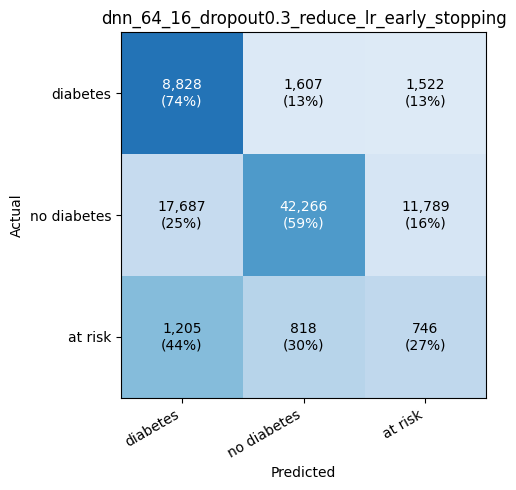

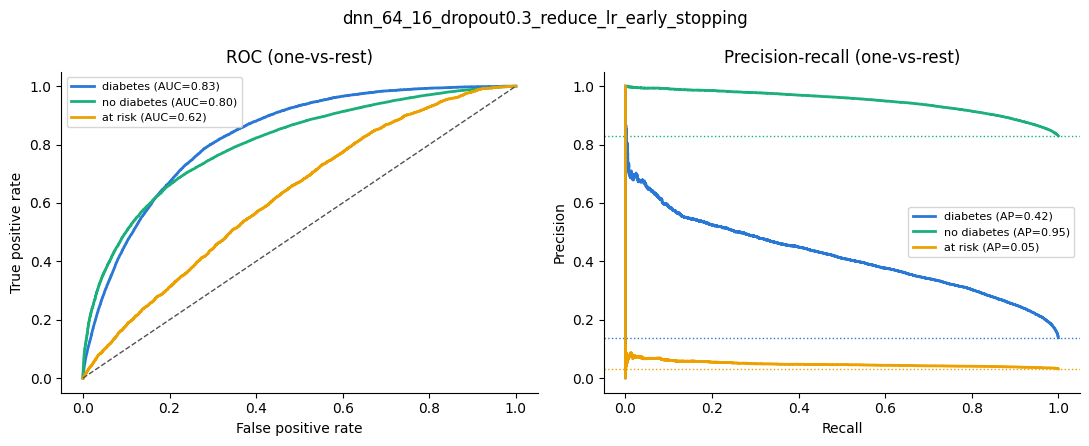

In [101]:
network_64_16, history_64_16 = run_network_experiment(hidden_units=(64, 16))

Epoch 1/50
507/507 - 17s - 34ms/step - accuracy: 0.5671 - auc: 0.6748 - f1_macro: 0.3825 - f2_macro: 0.3934 - loss: 1.0391 - pr_auc: 0.4247 - precision_at_risk: 0.0382 - precision_diabetes: 0.2942 - precision_no_diabetes: 0.9109 - recall_at_risk: 0.2855 - recall_diabetes: 0.4647 - recall_no_diabetes: 0.5951 - val_accuracy: 0.6138 - val_auc: 0.7492 - val_f1_macro: 0.4294 - val_f2_macro: 0.4472 - val_loss: 0.9047 - val_pr_auc: 0.4699 - val_precision_at_risk: 0.0457 - val_precision_diabetes: 0.3717 - val_precision_no_diabetes: 0.9431 - val_recall_at_risk: 0.3290 - val_recall_diabetes: 0.5760 - val_recall_no_diabetes: 0.6311 - learning_rate: 0.0010
Epoch 2/50
507/507 - 5s - 9ms/step - accuracy: 0.5217 - auc: 0.7073 - f1_macro: 0.3861 - f2_macro: 0.4027 - loss: 1.0020 - pr_auc: 0.4459 - precision_at_risk: 0.0396 - precision_diabetes: 0.3269 - precision_no_diabetes: 0.9464 - recall_at_risk: 0.3745 - recall_diabetes: 0.5740 - recall_no_diabetes: 0.5187 - val_accuracy: 0.5868 - val_auc: 0.7485

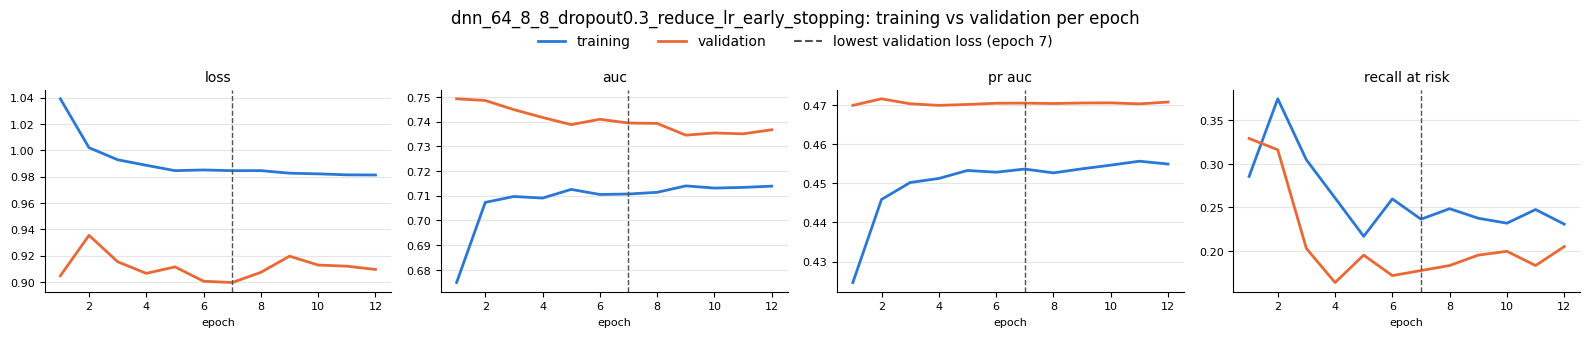

[dnn_64_8_8_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.853 | precision = 0.296 | F2 = 0.620 | F1 = 0.440 | specificity = 0.584 | flagged = 49.0%
    flagged: diabetes = 0.892 | at risk = 0.686 | diabetics missed = 0.108
    OVERALL  ROC-AUC (OvR) = 0.7486 | macro F1 = 0.4209 | balanced acc = 0.5216 | accuracy = 0.5868
              precision    recall  f1-score   support

    diabetes      0.354     0.665     0.462     11957
 no diabetes      0.951     0.584     0.724     71742
     at risk      0.044     0.316     0.077      2769

    accuracy                          0.587     86468
   macro avg      0.450     0.522     0.421     86468
weighted avg      0.839     0.587     0.667     86468



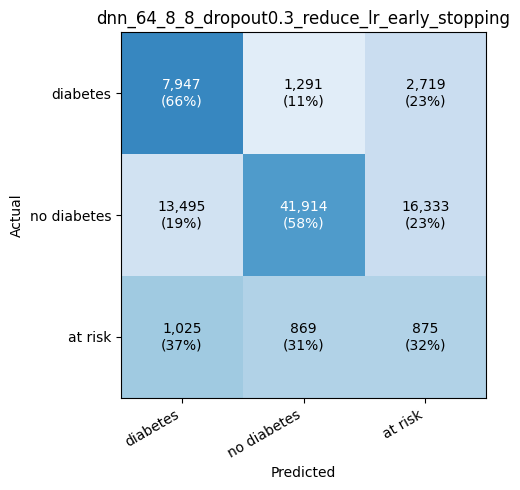

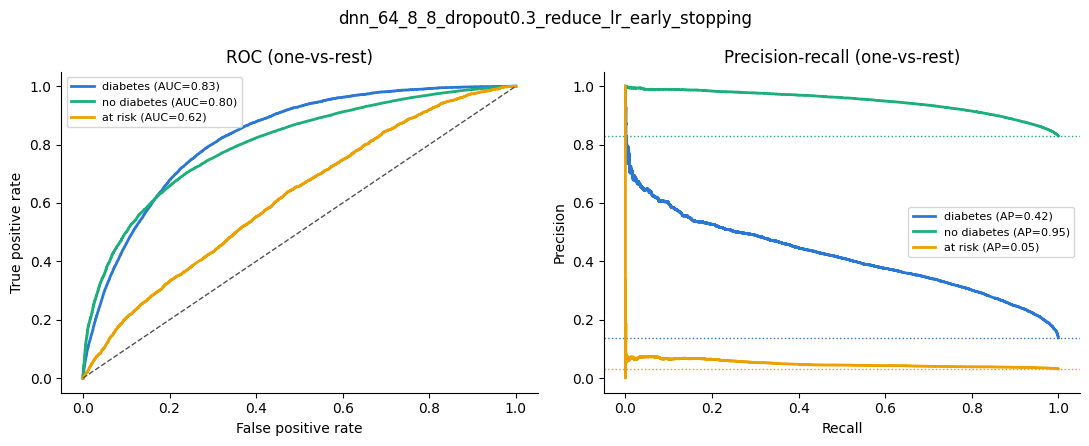

In [102]:
network_64_8_8, history_64_8_8 = run_network_experiment(hidden_units=(64, 8, 8))


Epoch 1/50
507/507 - 16s - 32ms/step - accuracy: 0.5566 - auc: 0.7074 - f1_macro: 0.3912 - f2_macro: 0.4183 - loss: 0.9944 - pr_auc: 0.4427 - precision_at_risk: 0.0430 - precision_diabetes: 0.2952 - precision_no_diabetes: 0.9346 - recall_at_risk: 0.2797 - recall_diabetes: 0.6413 - recall_no_diabetes: 0.5531 - val_accuracy: 0.5886 - val_auc: 0.7447 - val_f1_macro: 0.4124 - val_f2_macro: 0.4492 - val_loss: 0.9364 - val_pr_auc: 0.4679 - val_precision_at_risk: 0.0512 - val_precision_diabetes: 0.3074 - val_precision_no_diabetes: 0.9495 - val_recall_at_risk: 0.2589 - val_recall_diabetes: 0.7461 - val_recall_no_diabetes: 0.5751 - learning_rate: 0.0010
Epoch 2/50
507/507 - 4s - 9ms/step - accuracy: 0.5811 - auc: 0.7378 - f1_macro: 0.4109 - f2_macro: 0.4458 - loss: 0.9607 - pr_auc: 0.4598 - precision_at_risk: 0.0518 - precision_diabetes: 0.3118 - precision_no_diabetes: 0.9438 - recall_at_risk: 0.2973 - recall_diabetes: 0.7088 - recall_no_diabetes: 0.5707 - val_accuracy: 0.5929 - val_auc: 0.7480

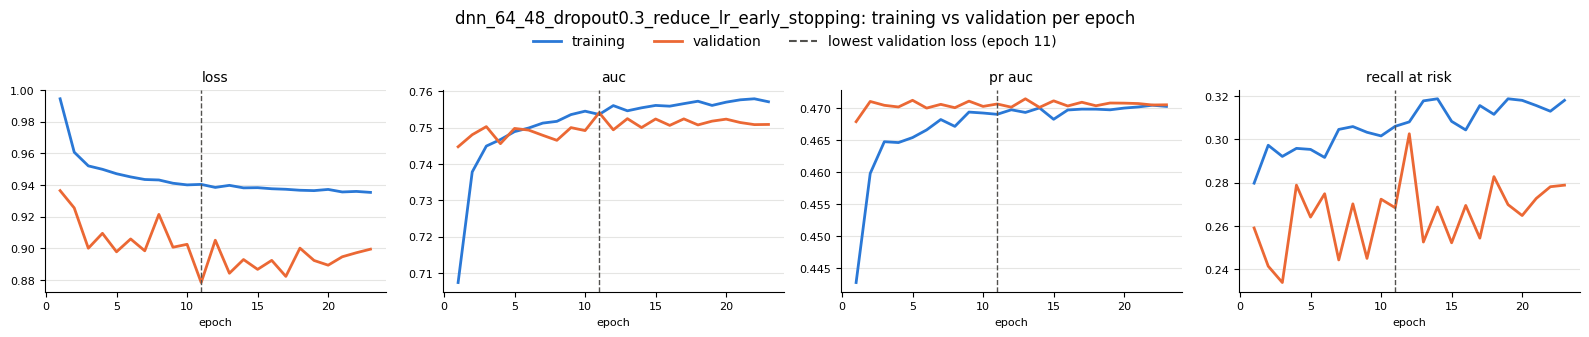

[dnn_64_48_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.829 | precision = 0.299 | F2 = 0.612 | F1 = 0.440 | specificity = 0.602 | flagged = 47.2%
    flagged: diabetes = 0.860 | at risk = 0.694 | diabetics missed = 0.140
    OVERALL  ROC-AUC (OvR) = 0.7524 | macro F1 = 0.4232 | balanced acc = 0.5331 | accuracy = 0.6104
              precision    recall  f1-score   support

    diabetes      0.315     0.745     0.443     11957
 no diabetes      0.945     0.602     0.735     71742
     at risk      0.056     0.252     0.092      2769

    accuracy                          0.610     86468
   macro avg      0.439     0.533     0.423     86468
weighted avg      0.829     0.610     0.674     86468



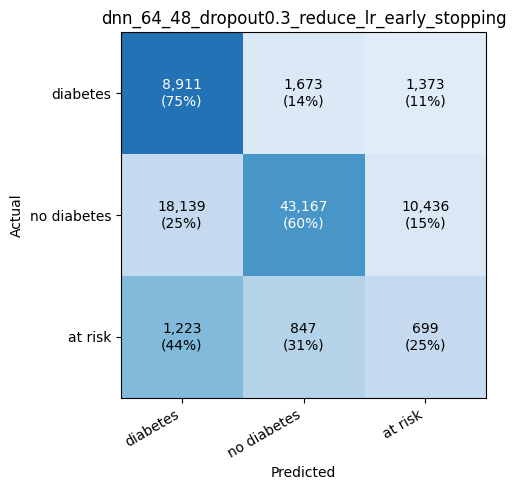

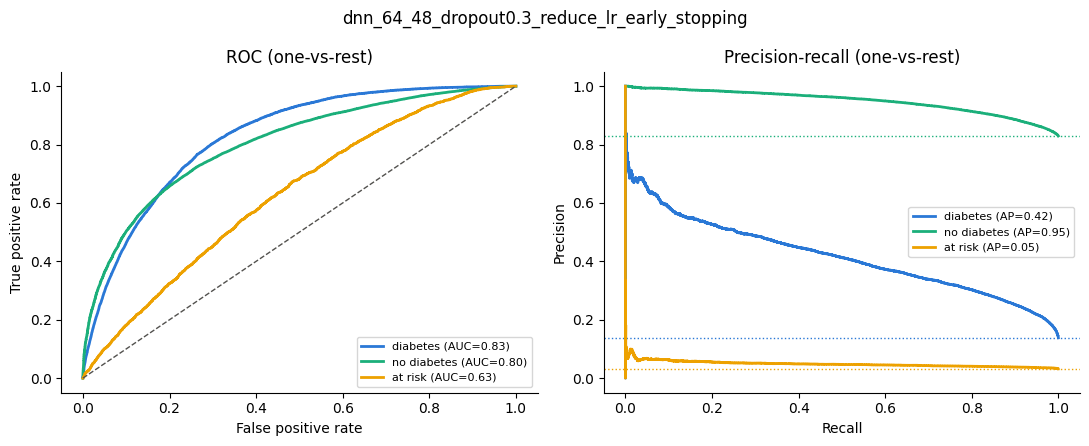

In [103]:
network_64_48, history_64_48 = run_network_experiment(hidden_units=(64, 48))


Epoch 1/50
507/507 - 17s - 34ms/step - accuracy: 0.5420 - auc: 0.6813 - f1_macro: 0.3753 - f2_macro: 0.4002 - loss: 1.0220 - pr_auc: 0.4273 - precision_at_risk: 0.0373 - precision_diabetes: 0.2725 - precision_no_diabetes: 0.9247 - recall_at_risk: 0.2279 - recall_diabetes: 0.6311 - recall_no_diabetes: 0.5393 - val_accuracy: 0.6188 - val_auc: 0.7224 - val_f1_macro: 0.4227 - val_f2_macro: 0.4581 - val_loss: 0.9458 - val_pr_auc: 0.4658 - val_precision_at_risk: 0.0491 - val_precision_diabetes: 0.3159 - val_precision_no_diabetes: 0.9466 - val_recall_at_risk: 0.2044 - val_recall_diabetes: 0.7542 - val_recall_no_diabetes: 0.6122 - learning_rate: 0.0010
Epoch 2/50
507/507 - 5s - 9ms/step - accuracy: 0.5880 - auc: 0.7158 - f1_macro: 0.4014 - f2_macro: 0.4360 - loss: 0.9886 - pr_auc: 0.4478 - precision_at_risk: 0.0451 - precision_diabetes: 0.2885 - precision_no_diabetes: 0.9408 - recall_at_risk: 0.1850 - recall_diabetes: 0.7523 - recall_no_diabetes: 0.5762 - val_accuracy: 0.6271 - val_auc: 0.7450

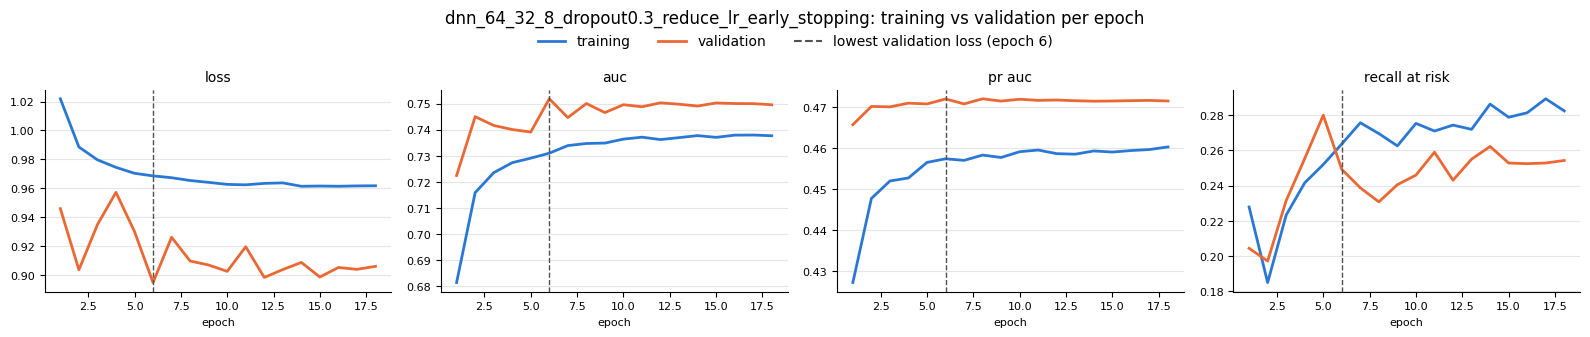

[dnn_64_32_8_dropout0.3_reduce_lr_early_stopping] SCREENING  sensitivity = 0.840 | precision = 0.297 | F2 = 0.615 | F1 = 0.438 | specificity = 0.591 | flagged = 48.2%
    flagged: diabetes = 0.871 | at risk = 0.706 | diabetics missed = 0.129
    OVERALL  ROC-AUC (OvR) = 0.7500 | macro F1 = 0.4191 | balanced acc = 0.5315 | accuracy = 0.6049
              precision    recall  f1-score   support

    diabetes      0.309     0.773     0.441     11957
 no diabetes      0.947     0.591     0.728     71742
     at risk      0.054     0.231     0.088      2769

    accuracy                          0.605     86468
   macro avg      0.437     0.532     0.419     86468
weighted avg      0.830     0.605     0.668     86468



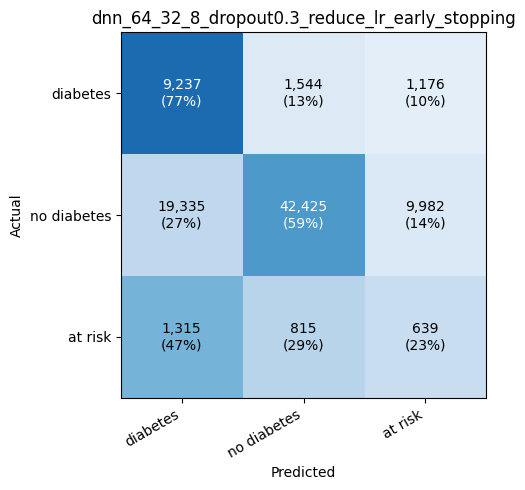

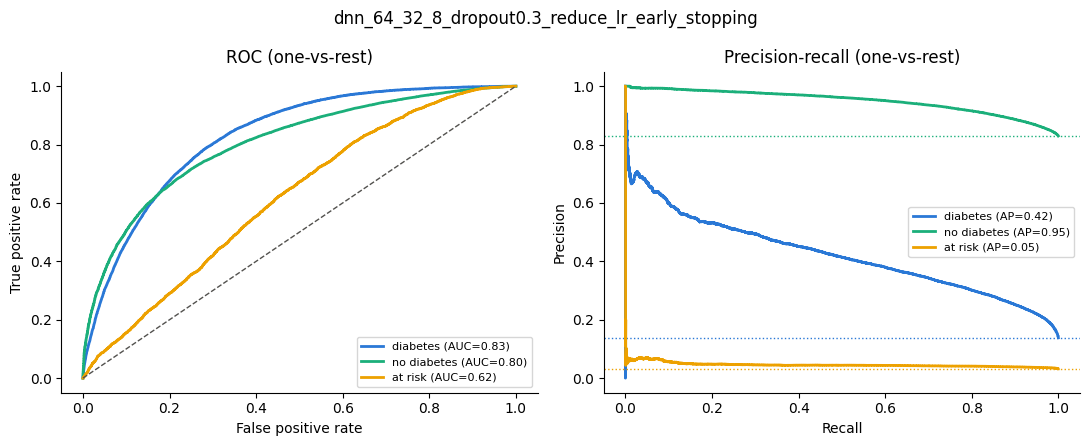

In [104]:
network_64_32_8, history_64_32_8 = run_network_experiment(hidden_units=(64, 32, 8))


In [105]:
comparison_columns = [
    "run_name",
    "screen_f2", "screen_f1", "screen_sensitivity", "screen_precision", "screen_specificity",
    "screen_sensitivity/diabetes", "screen_sensitivity/at risk", "missed/diabetes", "pct_flagged",
    "val_recall/diabetes", "val_recall/at risk", "val_precision/diabetes", "val_precision/at risk",
    "val_pr_auc/diabetes", "val_pr_auc/at risk", "val_roc_auc_ovr", "val_f1_macro",
]
results_table = pd.DataFrame(results_log)
results_table[[column for column in comparison_columns if column in results_table.columns]] \
    .sort_values("screen_f2", ascending=False)


,run_name,screen_f2,screen_f1,screen_sensitivity,screen_precision,screen_specificity,screen_sensitivity/diabetes,screen_sensitivity/at risk,missed/diabetes,pct_flagged,val_recall/diabetes,val_recall/at risk,val_precision/diabetes,val_precision/at risk,val_pr_auc/diabetes,val_pr_auc/at risk,val_roc_auc_ovr,val_f1_macro
20,dnn_64_8_8_dropout0.3_reduce_lr_early_stopping,0.6202,0.4400,0.8533,0.2964,0.5842,0.8920,0.6862,0.1080,49.0285,0.6646,0.3160,0.3537,0.0439,0.4174,0.0492,0.7486,0.4209
22,dnn_64_32_8_dropout0.3_reduce_lr_early_stopping,0.6147,0.4385,0.8398,0.2967,0.5914,0.8709,0.7057,0.1291,48.2074,0.7725,0.2308,0.3091,0.0542,0.4214,0.0459,0.7500,0.4191
21,dnn_64_48_dropout0.3_reduce_lr_early_stopping,0.6122,0.4398,0.8289,0.2993,0.6017,0.8601,0.6941,0.1399,47.1631,0.7453,0.2524,0.3152,0.0559,0.4172,0.0486,0.7524,0.4232
18,dnn_128_64_dropout0.3_reduce_lr_early_stopping,0.6120,0.4392,0.8297,0.2987,0.6001,0.8612,0.6938,0.1388,47.3111,0.7496,0.2474,0.3161,0.0545,0.4195,0.0488,0.7534,0.4227
4,rf_depth12_leaf100_estimators_1000,0.6114,0.4469,0.8103,0.3085,0.6272,0.8447,0.6620,0.1553,44.7310,0.7463,0.2142,0.3121,0.0588,0.4163,0.0484,0.7518,0.4284
5,rf_depth12_leaf100_estimators_2000,0.6113,0.4470,0.8095,0.3088,0.6280,0.8445,0.6584,0.1555,44.6489,0.7463,0.2134,0.3122,0.0589,0.4164,0.0485,0.7519,0.4287
11,xgb_depth4_lr0.05_trees500,0.6112,0.4362,0.8344,0.2953,0.5912,0.8623,0.7143,0.1377,48.1311,0.7060,0.3135,0.3271,0.0549,0.4135,0.0508,0.7524,0.4227
19,dnn_64_16_dropout0.3_reduce_lr_early_stopping,0.6109,0.4354,0.8353,0.2944,0.5891,0.8656,0.7046,0.1344,48.3150,0.7383,0.2694,0.3185,0.0531,0.4177,0.0480,0.7517,0.4199
6,rf_depth18_leaf200_estimators_2000,0.6106,0.4432,0.8162,0.3042,0.6167,0.8488,0.6753,0.1512,45.6990,0.7372,0.2391,0.3127,0.0584,0.4156,0.0482,0.7507,0.4262
8,lgbm_baseline,0.6106,0.4491,0.8033,0.3116,0.6358,0.8375,0.6555,0.1625,43.8972,0.7185,0.2286,0.3222,0.0560,0.4060,0.0491,0.7496,0.4312


In [106]:
comparison_metrics = {
    "screen_f2": "F2",
    "screen_sensitivity": "recall",
    "screen_precision": "precision",
    "screen_f1": "F1",
    "val_roc_auc_ovr": "ROC-AUC",
    "val_pr_auc/diabetes": "PR-AUC diabetes",
    "val_pr_auc/at risk": "PR-AUC at risk",
}
results_table = pd.DataFrame(results_log)
model_comparison = (results_table[["run_name"] + list(comparison_metrics)]
                    .rename(columns=comparison_metrics)
                    .set_index("run_name"))
model_comparison["PR-AUC mean (flag classes)"] = model_comparison[["PR-AUC diabetes", "PR-AUC at risk"]].mean(axis=1)
model_comparison.round(4)


,F2,recall,precision,F1,ROC-AUC,PR-AUC diabetes,PR-AUC at risk,PR-AUC mean (flag classes)
run_name,,,,,,,,
logreg_baseline,0.6081,0.8222,0.2979,0.4373,0.7431,0.4077,0.0499,0.2288
logreg_under_smotenc,0.5330,0.6027,0.3644,0.4542,0.7305,0.4122,0.0463,0.2292
logreg_smotenc_1to1,0.5639,0.7523,0.2817,0.4099,0.7121,0.3996,0.0431,0.2214
rf_depth6_leaf50_estimators_500,0.6086,0.8200,0.2996,0.4388,0.7455,0.4099,0.0476,0.2288
rf_depth12_leaf100_estimators_1000,0.6114,0.8103,0.3085,0.4469,0.7518,0.4163,0.0484,0.2324
rf_depth12_leaf100_estimators_2000,0.6113,0.8095,0.3088,0.4470,0.7519,0.4164,0.0485,0.2324
rf_depth18_leaf200_estimators_2000,0.6106,0.8162,0.3042,0.4432,0.7507,0.4156,0.0482,0.2319
logreg_13_features,0.6095,0.8118,0.3052,0.4436,0.7395,0.3972,0.0476,0.2224
lgbm_baseline,0.6106,0.8033,0.3116,0.4491,0.7496,0.4060,0.0491,0.2276


## Testing on unseen data

In [110]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             fbeta_score, precision_score, recall_score, classification_report)
from sklearn.preprocessing import label_binarize

# Rebuild the depth-12 forest (its variable was overwritten by later runs); same settings, same seed
forest_depth12 = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    max_depth=12,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
).fit(X_train, Y_train)

finalist_models = {
    "Random forest d12 leaf100 1000": forest_depth12,
    "Network 64-8-8": TrainedNetworkAdapter(network_64_8_8).fit(X_train, Y_train),   # fit() only sets the classes
}


def evaluate_on_test(model, model_name):
    """Six comparison metrics (+ missed diabetics and NPV) on the untouched test set."""
    test_probabilities = model.predict_proba(X_test)
    test_predictions = model.predict(X_test)
    true_labels = np.asarray(Y_test)
    model_classes = list(model.classes_)
    true_binarized = label_binarize(true_labels, classes=model_classes)

    actually_flagged = is_flagged(true_labels)
    predicted_flagged = is_flagged(test_predictions)
    print(f"\n===== {model_name} (test set) =====")
    print(classification_report(true_labels, test_predictions, labels=model_classes,
                                target_names=[CLASS_NAMES[int(class_code)] for class_code in model_classes],
                                digits=3, zero_division=0))
    return {
        "F2": fbeta_score(actually_flagged, predicted_flagged, beta=2),
        "recall": recall_score(actually_flagged, predicted_flagged),
        "precision": precision_score(actually_flagged, predicted_flagged),
        "F1": f1_score(actually_flagged, predicted_flagged),
        "ROC-AUC": roc_auc_score(true_labels, test_probabilities, multi_class="ovr", average="macro"),
        "PR-AUC diabetes": average_precision_score(true_binarized[:, model_classes.index(1)],
                                                   test_probabilities[:, model_classes.index(1)]),
        "PR-AUC at risk": average_precision_score(true_binarized[:, model_classes.index(4)],
                                                  test_probabilities[:, model_classes.index(4)]),
        "diabetics missed": (test_predictions[true_labels == 1] == 3).mean(),
        "NPV": (~actually_flagged[~predicted_flagged]).mean(),     # "no follow-up needed" that is correct
        "flagged %": predicted_flagged.mean() * 100,
    }


test_results = pd.DataFrame({model_name: evaluate_on_test(model, model_name)
                             for model_name, model in finalist_models.items()}).T
test_results.round(4)



===== Random forest d12 leaf100 1000 (test set) =====
              precision    recall  f1-score   support

    diabetes      0.311     0.749     0.440     11957
 no diabetes      0.943     0.625     0.752     71741
     at risk      0.061     0.222     0.095      2770

    accuracy                          0.629     86468
   macro avg      0.438     0.532     0.429     86468
weighted avg      0.827     0.629     0.688     86468


===== Network 64-8-8 (test set) =====
              precision    recall  f1-score   support

    diabetes      0.353     0.663     0.461     11957
 no diabetes      0.951     0.583     0.723     71741
     at risk      0.042     0.303     0.074      2770

    accuracy                          0.585     86468
   macro avg      0.449     0.516     0.419     86468
weighted avg      0.839     0.585     0.666     86468



,F2,recall,precision,F1,ROC-AUC,PR-AUC diabetes,PR-AUC at risk,diabetics missed,NPV,flagged %
Random forest d12 leaf100 1000,0.6138,0.8154,0.3086,0.4478,0.7557,0.4107,0.0529,0.1529,0.9428,45.0005
Network 64-8-8,0.6195,0.8531,0.2956,0.4391,0.7489,0.4128,0.0517,0.1078,0.9508,49.1546


## Ensemble Models

In [114]:
from sklearn.metrics import fbeta_score, recall_score, precision_score, f1_score, roc_auc_score

network_member = TrainedNetworkAdapter(network_64_8_8).fit(X_train, Y_train)   # fit() only sets the classes

averaged_val_probabilities = (forest_depth12.predict_proba(X_val) + network_member.predict_proba(X_val)) / 2
averaged_val_predictions = forest_depth12.classes_[np.argmax(averaged_val_probabilities, axis=1)]

actually_flagged = is_flagged(Y_val)
predicted_flagged = is_flagged(averaged_val_predictions)
print("VALIDATION  F2:", round(fbeta_score(actually_flagged, predicted_flagged, beta=2), 4),
      "| recall:", round(recall_score(actually_flagged, predicted_flagged), 4),
      "| precision:", round(precision_score(actually_flagged, predicted_flagged), 4),
      "| F1:", round(f1_score(actually_flagged, predicted_flagged), 4),
      "| ROC-AUC:", round(roc_auc_score(Y_val, averaged_val_probabilities, multi_class="ovr"), 4))


VALIDATION  F2: 0.6183 | recall: 0.82 | precision: 0.3117 | F1: 0.4517 | ROC-AUC: 0.7558


In [116]:
from sklearn.base import BaseEstimator, ClassifierMixin


class AveragedProbabilityEnsemble(BaseEstimator, ClassifierMixin):
    """Soft-voting ensemble of already trained models: weighted average of their class probabilities,
    then the highest-probability class. fit() does not retrain the members; it only checks their classes."""

    def __init__(self, member_models, member_weights=None):
        self.member_models = member_models
        self.member_weights = member_weights

    def fit(self, X, y):
        member_classes = [np.asarray(member.classes_, dtype=float) for member in self.member_models]
        if not all(np.array_equal(member_classes[0], classes) for classes in member_classes):
            raise ValueError(f"members predict different classes: {member_classes}")
        self.classes_ = member_classes[0]
        return self

    def predict_proba(self, X):
        weights = self.member_weights or [1.0] * len(self.member_models)
        weighted_sum = sum(weight * member.predict_proba(X) for weight, member in zip(weights, self.member_models))
        return weighted_sum / sum(weights)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


In [117]:
ensemble_model = AveragedProbabilityEnsemble(member_models=[forest_depth12, network_member]).fit(X_train, Y_train)

ensemble_test_results = pd.DataFrame({"Ensemble RF12 + DNN 64-8-8": evaluate_on_test(ensemble_model, "Ensemble RF12 + DNN 64-8-8")}).T
pd.concat([test_results, ensemble_test_results]).round(4)



===== Ensemble RF12 + DNN 64-8-8 (test set) =====
              precision    recall  f1-score   support

    diabetes      0.316     0.742     0.443     11957
 no diabetes      0.944     0.628     0.754     71741
     at risk      0.058     0.225     0.092      2770

    accuracy                          0.631     86468
   macro avg      0.440     0.531     0.430     86468
weighted avg      0.829     0.631     0.690     86468



,F2,recall,precision,F1,ROC-AUC,PR-AUC diabetes,PR-AUC at risk,diabetics missed,NPV,flagged %
Random forest d12 leaf100 1000,0.6138,0.8154,0.3086,0.4478,0.7557,0.4107,0.0529,0.1529,0.9428,45.0005
Network 64-8-8,0.6195,0.8531,0.2956,0.4391,0.7489,0.4128,0.0517,0.1078,0.9508,49.1546
Ensemble RF12 + DNN 64-8-8,0.6180,0.8199,0.3113,0.4513,0.7590,0.4154,0.0541,0.1449,0.9444,44.8594


In [118]:
xgboost_depth4 = BalancedXGBClassifier(xgb_params={
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 4,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}).fit(X_train, Y_train)


In [119]:
three_model_ensemble = AveragedProbabilityEnsemble(
    member_models=[forest_depth12, network_member, xgboost_depth4],     # equal weights: 1/3 each
).fit(X_train, Y_train)

three_val_probabilities = three_model_ensemble.predict_proba(X_val)
three_val_predictions = three_model_ensemble.predict(X_val)

actually_flagged = is_flagged(Y_val)
predicted_flagged = is_flagged(three_val_predictions)
print("VALIDATION  F2:", round(fbeta_score(actually_flagged, predicted_flagged, beta=2), 4),
      "| recall:", round(recall_score(actually_flagged, predicted_flagged), 4),
      "| precision:", round(precision_score(actually_flagged, predicted_flagged), 4),
      "| F1:", round(f1_score(actually_flagged, predicted_flagged), 4),
      "| ROC-AUC:", round(roc_auc_score(Y_val, three_val_probabilities, multi_class="ovr"), 4))


VALIDATION  F2: 0.6169 | recall: 0.8262 | precision: 0.3064 | F1: 0.447 | ROC-AUC: 0.7561


In [120]:
three_model_test_results = pd.DataFrame(
    {"Ensemble RF12 + DNN 64-8-8 + XGB d4": evaluate_on_test(three_model_ensemble, "Ensemble RF12 + DNN 64-8-8 + XGB d4")}
).T
pd.concat([test_results, ensemble_test_results, three_model_test_results]).round(4)



===== Ensemble RF12 + DNN 64-8-8 + XGB d4 (test set) =====
              precision    recall  f1-score   support

    diabetes      0.321     0.731     0.446     11957
 no diabetes      0.945     0.616     0.746     71741
     at risk      0.059     0.266     0.096      2770

    accuracy                          0.620     86468
   macro avg      0.442     0.537     0.429     86468
weighted avg      0.830     0.620     0.683     86468



,F2,recall,precision,F1,ROC-AUC,PR-AUC diabetes,PR-AUC at risk,diabetics missed,NPV,flagged %
Random forest d12 leaf100 1000,0.6138,0.8154,0.3086,0.4478,0.7557,0.4107,0.0529,0.1529,0.9428,45.0005
Network 64-8-8,0.6195,0.8531,0.2956,0.4391,0.7489,0.4128,0.0517,0.1078,0.9508,49.1546
Ensemble RF12 + DNN 64-8-8,0.6180,0.8199,0.3113,0.4513,0.7590,0.4154,0.0541,0.1449,0.9444,44.8594
Ensemble RF12 + DNN 64-8-8 + XGB d4,0.6163,0.8256,0.3060,0.4465,0.7598,0.4156,0.0547,0.1434,0.9450,45.9557


In [121]:
from sklearn.metrics import precision_recall_curve, fbeta_score, recall_score, precision_score, f1_score

model_classes = np.asarray(ensemble_model.classes_)             # [1, 3, 4]
diabetes_column = list(model_classes).index(1)
at_risk_column = list(model_classes).index(4)


def flag_probability(class_probabilities):
    """Probability of needing follow-up: P(diabetes) + P(at risk)."""
    return class_probabilities[:, diabetes_column] + class_probabilities[:, at_risk_column]


def predict_with_threshold(class_probabilities, threshold):
    """Flag when P(diabetes) + P(at risk) >= threshold; flagged people get the more likely of the two classes."""
    flagged = flag_probability(class_probabilities) >= threshold
    flagged_class = np.where(class_probabilities[:, diabetes_column] >= class_probabilities[:, at_risk_column], 1, 4)
    return np.where(flagged, flagged_class, 3)


def screening_metrics(true_labels, predicted_labels):
    true_labels = np.asarray(true_labels)
    actually_flagged, predicted_flagged = is_flagged(true_labels), is_flagged(predicted_labels)
    return {
        "F2": fbeta_score(actually_flagged, predicted_flagged, beta=2),
        "recall": recall_score(actually_flagged, predicted_flagged),
        "precision": precision_score(actually_flagged, predicted_flagged),
        "F1": f1_score(actually_flagged, predicted_flagged),
        "diabetics missed": (predicted_labels[true_labels == 1] == 3).mean(),
        "NPV": (~actually_flagged[~predicted_flagged]).mean(),
        "flagged %": predicted_flagged.mean() * 100,
    }


# ---- 1. Choose both thresholds on the VALIDATION set ----
val_probabilities = ensemble_model.predict_proba(X_val)
val_precision_values, val_recall_values, candidate_thresholds = precision_recall_curve(
    is_flagged(Y_val), flag_probability(val_probabilities))
val_precision_values, val_recall_values = val_precision_values[:-1], val_recall_values[:-1]   # align with thresholds

# Rule A: maximize F2
val_f2_values = 5 * val_precision_values * val_recall_values / np.maximum(4 * val_precision_values + val_recall_values, 1e-12)
threshold_max_f2 = candidate_thresholds[np.argmax(val_f2_values)]

# Rule B: recall >= 0.85, then the best precision
meets_recall_target = val_recall_values >= 0.85
threshold_recall_085 = candidate_thresholds[np.argmax(np.where(meets_recall_target, val_precision_values, -1))]

chosen_thresholds = {"max F2": threshold_max_f2, "recall >= 0.85, best precision": threshold_recall_085}
validation_comparison = pd.DataFrame(
    {"default (most likely class)": screening_metrics(Y_val, ensemble_model.predict(X_val)),
     **{f"{rule_name} (threshold {threshold:.3f})": screening_metrics(Y_val, predict_with_threshold(val_probabilities, threshold))
        for rule_name, threshold in chosen_thresholds.items()}}).T
print("VALIDATION")
validation_comparison.round(4)


VALIDATION


,F2,recall,precision,F1,diabetics missed,NPV,flagged %
default (most likely class),0.6183,0.8200,0.3117,0.4517,0.1440,0.9445,44.8120
max F2 (threshold 0.623),0.6248,0.8399,0.3087,0.4514,0.1209,0.9492,46.3432
"recall >= 0.85, best precision (threshold 0.613)",0.6239,0.8501,0.3022,0.4459,0.1121,0.9510,47.9021


In [122]:
# ---- 2. Test once, with the thresholds fixed on validation ----
test_probabilities = ensemble_model.predict_proba(X_test)
test_comparison = pd.DataFrame(
    {"default (most likely class)": screening_metrics(Y_test, ensemble_model.predict(X_test)),
     **{f"{rule_name} (threshold {threshold:.3f})": screening_metrics(Y_test, predict_with_threshold(test_probabilities, threshold))
        for rule_name, threshold in chosen_thresholds.items()},
     "Network 64-8-8 (for reference)": screening_metrics(Y_test, network_member.predict(X_test))}).T
print("TEST")
test_comparison.round(4)


TEST


,F2,recall,precision,F1,diabetics missed,NPV,flagged %
default (most likely class),0.6180,0.8199,0.3113,0.4513,0.1449,0.9444,44.8594
max F2 (threshold 0.623),0.6229,0.8387,0.3069,0.4494,0.1217,0.9486,46.5467
"recall >= 0.85, best precision (threshold 0.613)",0.6224,0.8500,0.3006,0.4441,0.1118,0.9507,48.1670
Network 64-8-8 (for reference),0.6195,0.8531,0.2956,0.4391,0.1078,0.9508,49.1546


In [124]:
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, fbeta_score, recall_score,
                             precision_score, f1_score)
from sklearn.preprocessing import label_binarize


def final_evaluation_report(class_probabilities, true_labels, threshold, model_name, figure_prefix=None):
    """Full evaluation of a thresholded model: metrics, 3-class and screening confusion matrices,
    ROC and precision-recall curves (per class and for the follow-up flag)."""
    true_labels = np.asarray(true_labels)
    model_classes = [1, 3, 4]
    class_display_names = [CLASS_NAMES[class_code] for class_code in model_classes]
    true_binarized = label_binarize(true_labels, classes=model_classes)
    predicted_labels = predict_with_threshold(class_probabilities, threshold)
    follow_up_probability = flag_probability(class_probabilities)
    actually_flagged, predicted_flagged = is_flagged(true_labels), is_flagged(predicted_labels)

    # ---------- Metrics ----------
    report_metrics = {
        "threshold": threshold,
        "F2": fbeta_score(actually_flagged, predicted_flagged, beta=2),
        "recall (sensitivity)": recall_score(actually_flagged, predicted_flagged),
        "precision (PPV)": precision_score(actually_flagged, predicted_flagged),
        "F1": f1_score(actually_flagged, predicted_flagged),
        "specificity": (~predicted_flagged[~actually_flagged]).mean(),
        "NPV": (~actually_flagged[~predicted_flagged]).mean(),
        "diabetics missed": (predicted_labels[true_labels == 1] == 3).mean(),
        "flagged %": predicted_flagged.mean() * 100,
        "ROC-AUC (3-class, one-vs-rest)": roc_auc_score(true_labels, class_probabilities, multi_class="ovr", average="macro"),
        "PR-AUC diabetes": average_precision_score(true_binarized[:, 0], class_probabilities[:, 0]),
        "PR-AUC at risk": average_precision_score(true_binarized[:, 2], class_probabilities[:, 2]),
        "flag ROC-AUC (follow-up vs not)": roc_auc_score(actually_flagged, follow_up_probability),
        "flag PR-AUC (follow-up vs not)": average_precision_score(actually_flagged, follow_up_probability),
    }
    print(f"===== {model_name} =====")
    print(pd.Series(report_metrics).round(4).to_string())
    print("\n" + classification_report(true_labels, predicted_labels, labels=model_classes,
                                       target_names=class_display_names, digits=3, zero_division=0))

    # ---------- Confusion matrices: 3 classes, and screening (follow-up vs not) ----------
    fig_matrices, (class_axis, screening_axis) = plt.subplots(1, 2, figsize=(12, 5))
    matrix_specs = [
        (class_axis, confusion_matrix(true_labels, predicted_labels, labels=model_classes),
         class_display_names, "3 classes"),
        (screening_axis, confusion_matrix(actually_flagged, predicted_flagged, labels=[True, False]),
         ["needs follow-up", "no follow-up"], "Screening decision"),
    ]
    for matrix_axis, matrix_counts, tick_names, matrix_title in matrix_specs:
        row_share = matrix_counts / matrix_counts.sum(axis=1, keepdims=True)
        matrix_axis.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
        for row_index in range(len(tick_names)):
            for col_index in range(len(tick_names)):
                cell_share = row_share[row_index, col_index]
                matrix_axis.text(col_index, row_index, f"{matrix_counts[row_index, col_index]:,}\n({cell_share:.0%})",
                                 ha="center", va="center", color="white" if cell_share > 0.5 else "black")
        matrix_axis.set_xticks(range(len(tick_names)), tick_names, rotation=20, ha="right")
        matrix_axis.set_yticks(range(len(tick_names)), tick_names)
        matrix_axis.set(xlabel="Predicted", ylabel="Actual", title=matrix_title)
    fig_matrices.suptitle(f"{model_name}: confusion matrices (threshold {threshold:.3f})")
    fig_matrices.tight_layout()

    # ---------- ROC and precision-recall curves: per class + follow-up flag ----------
    fig_curves, (roc_axis, pr_axis) = plt.subplots(1, 2, figsize=(12, 5))
    for class_index, class_code in enumerate(model_classes):
        color = CLASS_COLORS.get(class_code, "#52514e")
        false_positive_rate, true_positive_rate, _ = roc_curve(true_binarized[:, class_index], class_probabilities[:, class_index])
        roc_axis.plot(false_positive_rate, true_positive_rate, color=color, linewidth=1.5,
                      label=f"{CLASS_NAMES[class_code]} (AUC={roc_auc_score(true_binarized[:, class_index], class_probabilities[:, class_index]):.3f})")
        precision_values, recall_values, _ = precision_recall_curve(true_binarized[:, class_index], class_probabilities[:, class_index])
        pr_axis.plot(recall_values, precision_values, color=color, linewidth=1.5,
                     label=f"{CLASS_NAMES[class_code]} (AP={average_precision_score(true_binarized[:, class_index], class_probabilities[:, class_index]):.3f})")
        pr_axis.axhline(true_binarized[:, class_index].mean(), color=color, linewidth=1, linestyle=":")

    flag_false_positive_rate, flag_true_positive_rate, _ = roc_curve(actually_flagged, follow_up_probability)
    roc_axis.plot(flag_false_positive_rate, flag_true_positive_rate, color="#0b0b0b", linewidth=2.5,
                  label=f"follow-up flag (AUC={report_metrics['flag ROC-AUC (follow-up vs not)']:.3f})")
    flag_precision_values, flag_recall_values, _ = precision_recall_curve(actually_flagged, follow_up_probability)
    pr_axis.plot(flag_recall_values, flag_precision_values, color="#0b0b0b", linewidth=2.5,
                 label=f"follow-up flag (AP={report_metrics['flag PR-AUC (follow-up vs not)']:.3f})")
    pr_axis.axhline(actually_flagged.mean(), color="#0b0b0b", linewidth=1, linestyle=":")

    # mark the chosen operating point on the flag curves
    roc_axis.plot(1 - report_metrics["specificity"], report_metrics["recall (sensitivity)"], "o",
                  color="#e34948", markersize=9, label=f"chosen threshold {threshold:.3f}")
    pr_axis.plot(report_metrics["recall (sensitivity)"], report_metrics["precision (PPV)"], "o",
                 color="#e34948", markersize=9, label=f"chosen threshold {threshold:.3f}")

    roc_axis.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--")
    roc_axis.set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (sensitivity)", title="ROC curves")
    pr_axis.set(xlabel="Recall (sensitivity)", ylabel="Precision (PPV)", title="Precision-recall curves (dotted = random)")
    for curve_axis in (roc_axis, pr_axis):
        curve_axis.legend(fontsize=8)
        for side in ["top", "right"]:
            curve_axis.spines[side].set_visible(False)
    fig_curves.suptitle(f"{model_name}: ROC and precision-recall")
    fig_curves.tight_layout()

    if figure_prefix:
        fig_matrices.savefig(os.path.join(OUTPUT_DIR, f"{figure_prefix}_confusion_matrices.png"), dpi=150, bbox_inches="tight")
        fig_curves.savefig(os.path.join(OUTPUT_DIR, f"{figure_prefix}_roc_pr_curves.png"), dpi=150, bbox_inches="tight")
    plt.show()
    return report_metrics


===== Final model: RF d12 + DNN 64-8-8 ensemble (test set) =====
threshold                           0.6233
F2                                  0.6229
recall (sensitivity)                0.8387
precision (PPV)                     0.3069
F1                                  0.4494
specificity                         0.6112
NPV                                 0.9486
diabetics missed                    0.1217
flagged %                          46.5467
ROC-AUC (3-class, one-vs-rest)      0.7590
PR-AUC diabetes                     0.4154
PR-AUC at risk                      0.0541
flag ROC-AUC (follow-up vs not)     0.8043
flag PR-AUC (follow-up vs not)      0.4580

              precision    recall  f1-score   support

    diabetes      0.310     0.751     0.439     11957
 no diabetes      0.949     0.611     0.743     71741
     at risk      0.053     0.214     0.084      2770

    accuracy                          0.618     86468
   macro avg      0.437     0.526     0.422     86468
weight

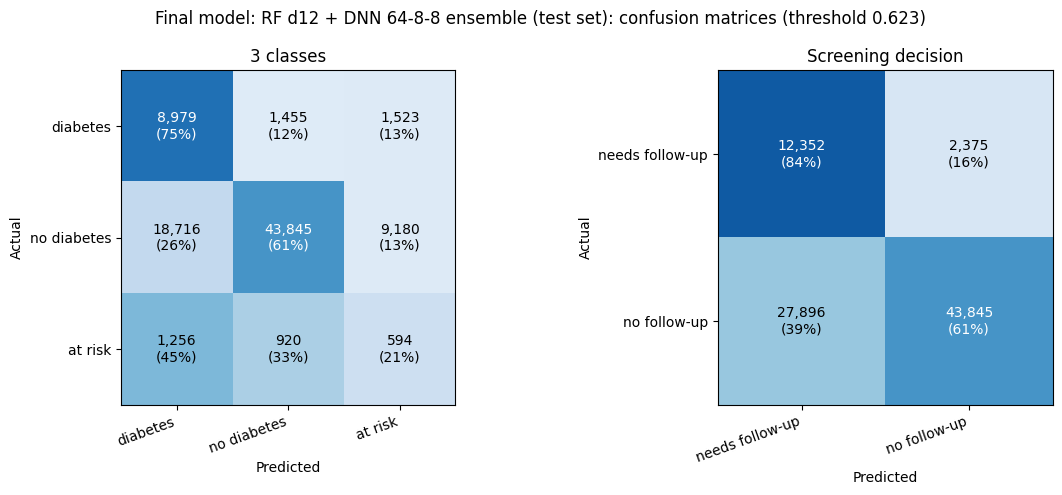

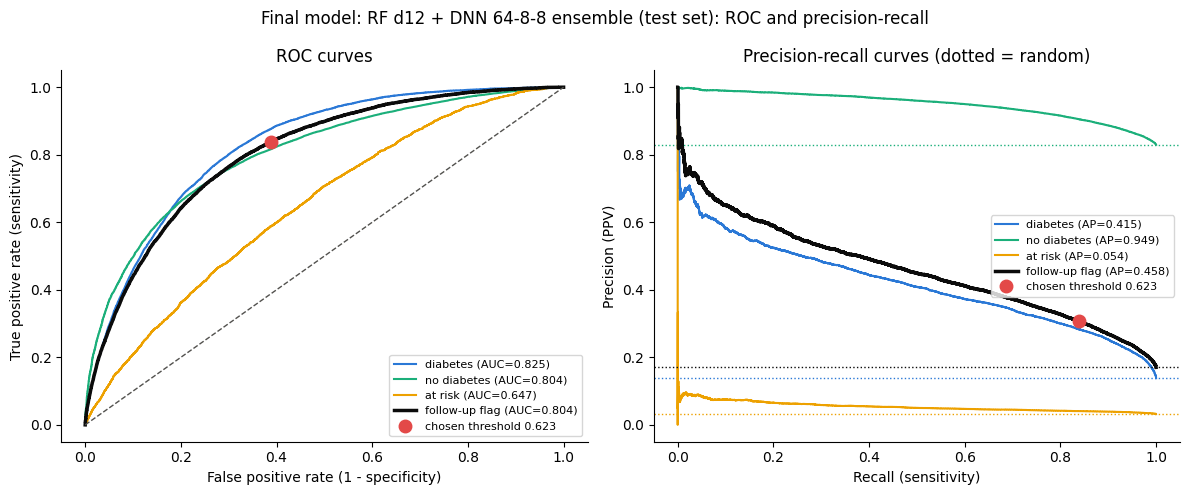

In [125]:
final_test_metrics = final_evaluation_report(
    class_probabilities=ensemble_model.predict_proba(X_test),
    true_labels=Y_test,
    threshold=threshold_max_f2,
    model_name="Final model: RF d12 + DNN 64-8-8 ensemble (test set)",
    figure_prefix="final_ensemble_test",
)


In [126]:
import json
import shutil
import joblib
from tensorflow import keras

model_dir = os.path.join(OUTPUT_DIR, "final_model")
os.makedirs(model_dir, exist_ok=True)

# ---- 1. Save the two best models ----
joblib.dump(forest_depth12, os.path.join(model_dir, "random_forest_d12.joblib"), compress=3)   # classical model
network_64_8_8.save(os.path.join(model_dir, "network_64_8_8.keras"))                            # deep learning model
network_64_8_8.save(os.path.join(model_dir, "network_64_8_8.h5"))                               # same model, .h5 format

# ---- 2. Save what the ensemble needs to rebuild its decision ----
joblib.dump(network_preprocess, os.path.join(model_dir, "network_preprocess.joblib"))   # the network's imputation, scaling, one-hot
final_model_config = {
    "model": "Soft-voting ensemble: random forest d12 leaf100 1000 trees + Keras MLP 64-8-8",
    "member_weights": [0.5, 0.5],
    "class_order": [1, 3, 4],
    "class_names": {"1": "diabetes", "3": "no diabetes", "4": "at risk"},
    "decision_rule": "flag when P(diabetes) + P(at risk) >= threshold; label = more likely of the two",
    "threshold": float(threshold_max_f2),
    "threshold_selection": "maximum screening F2 on the validation set",
    "features": list(X_train.columns),
}
with open(os.path.join(model_dir, "final_model_config.json"), "w") as config_file:
    json.dump(final_model_config, config_file, indent=2)

# ---- 3. Check: the reloaded files must reproduce the test predictions exactly ----
reloaded_forest = joblib.load(os.path.join(model_dir, "random_forest_d12.joblib"))
reloaded_network = keras.models.load_model(os.path.join(model_dir, "network_64_8_8.keras"))
reloaded_preprocess = joblib.load(os.path.join(model_dir, "network_preprocess.joblib"))

reloaded_network_inputs = reloaded_preprocess.transform(X_test)
if hasattr(reloaded_network_inputs, "toarray"):
    reloaded_network_inputs = reloaded_network_inputs.toarray()
reloaded_probabilities = (0.5 * reloaded_forest.predict_proba(X_test)
                          + 0.5 * reloaded_network.predict(np.asarray(reloaded_network_inputs, dtype="float32"), verbose=0))
reloaded_predictions = predict_with_threshold(reloaded_probabilities, final_model_config["threshold"])
original_predictions = predict_with_threshold(ensemble_model.predict_proba(X_test), threshold_max_f2)
print("saved model reproduces the test predictions:", np.array_equal(reloaded_predictions, original_predictions))

# ---- 4. Zip everything for download ----
shutil.make_archive(os.path.join(OUTPUT_DIR, "final_model"), "zip", model_dir)
shutil.make_archive(os.path.join(OUTPUT_DIR, "tensorboard_runs_20_features"), "zip", LOG_DIR)

for file_name in ["final_model.zip", "tensorboard_runs_20_features.zip"]:
    file_size_mb = os.path.getsize(os.path.join(OUTPUT_DIR, file_name)) / 1e6
    print(f"{file_name}: {file_size_mb:.1f} MB")


saved model reproduces the test predictions: True
final_model.zip: 70.0 MB
tensorboard_runs_20_features.zip: 2.6 MB


In [127]:
import shutil
from IPython.display import FileLink, display

everything_dir = "/kaggle/working/everything_for_download"
shutil.rmtree(everything_dir, ignore_errors=True)
os.makedirs(everything_dir)

skip_names = {"everything_for_download", "LLCP2023.XPT", "LLCP2023XPT.zip", "BRFSS_dataset.csv"}   # large raw data
for item_name in os.listdir(OUTPUT_DIR):
    if item_name in skip_names or item_name.endswith(".zip"):
        continue                                         # the zips you already made are included via their folders
    source_path = os.path.join(OUTPUT_DIR, item_name)
    target_path = os.path.join(everything_dir, item_name)
    if os.path.isdir(source_path):
        shutil.copytree(source_path, target_path, ignore=shutil.ignore_patterns(*skip_names))
    else:
        shutil.copy2(source_path, target_path)

shutil.make_archive("/kaggle/working/everything", "zip", everything_dir)
print(f"everything.zip: {os.path.getsize('/kaggle/working/everything.zip') / 1e6:.1f} MB")
print("contents:", sorted(os.listdir(everything_dir)))
display(FileLink("everything.zip"))


everything.zip: 79.8 MB
contents: ['.virtual_documents', 'data', 'final_ensemble_test_confusion_matrices.png', 'final_ensemble_test_roc_pr_curves.png', 'final_model', 'runs_20_features']


/kaggle/working/everything.zip

In [109]:
###### %load_ext tensorboard
%tensorboard --logdir {LOG_DIR}

UsageError: Line magic function `%tensorboard` not found.


Citations:
1. Vounzoulaki E, Khunti K, Abner SC, Tan BK, Davies MJ, Gillies CL. Progression to type 2 diabetes in women with a known history of gestational diabetes: systematic review and meta-analysis. BMJ. 2020;369:m1361.
https://www.bmj.com/content/bmj/369/bmj.m1361.full.pdf